# Đề tài 06: Dự báo giá bất động sản đô thị
### Urban Real Estate Valuation & Hedonic Pricing

| | |
|---|---|
| **Môn học** | Khai phá dữ liệu (Data Mining) |
| **Tác vụ khai phá chính** | Hồi quy dữ liệu (Data Regression) |
| **Chuẩn đầu ra (CLO) đáp ứng** | L.O.3.1, L.O.3.3, L.O.4.1, L.O.4.2 |
| **Tập dữ liệu** | Dữ liệu nhà đất Hà Nội và TP.HCM, thu thập qua web scraping |
| **Mục tiêu bài toán** | Ước lượng giá trị chuyển nhượng bất động sản dựa trên diện tích, vị trí, tiện ích xung quanh và đặc điểm căn nhà |
| **Nội dung notebook** | Giai đoạn chuẩn bị dữ liệu: làm sạch dữ liệu thô thu thập được |

---

### Quy trình khai phá tri thức (KDD)

Notebook được tổ chức theo quy trình khai phá tri thức từ dữ liệu (Knowledge Discovery in Databases):

| Giai đoạn KDD | Nội dung | Mục |
|---|---|---|
| 1. Lựa chọn dữ liệu | Nạp dữ liệu tin rao thô | 1–2 |
| 2. Tiền xử lý | Làm sạch 36 loại lỗi, loại trùng lặp, phân tích mất cân bằng, loại ngoại lai | 3–4, 5.1, 5.5 |
| 3. Biến đổi | Biến đổi Log1p/Box-Cox, tọa độ, khoảng cách tới trung tâm, tiện ích xung quanh, trích chọn thuộc tính | 5.2–5.4, 5.6, 6.3 |
| 4. Khai phá dữ liệu | Tác vụ hồi quy: Ridge, Lasso, ElasticNet, Gradient Boosting, LightGBM, Stacking; Grid Search CV | 6 |
| 5. Diễn giải và đánh giá | RMSE, MAE, R², MAPE trên tập kiểm thử, sai số theo nhóm, SHAP, khoảng dự báo | 7 |

### Mô tả dữ liệu

Tập dữ liệu gồm 3.500 tin rao bán nhà ở tại Hà Nội và Thành phố Hồ Chí Minh, với 21 thuộc tính, ở dạng thô như khi thu thập từ các trang rao vặt bất động sản. Dữ liệu chứa nhiều dạng lỗi phổ biến của dữ liệu thu thập tự động: giá trị số được ghi dưới dạng văn bản, sai đơn vị đo, cách viết không thống nhất, lỗi mã hóa ký tự, bản ghi trùng lặp và dòng không hợp lệ.

Notebook này thực hiện quy trình làm sạch nhằm tạo ra tập dữ liệu nhất quán, đúng kiểu, làm đầu vào cho Bước 1 (Tiền xử lý) và Bước 2 (Mô hình hóa) của đề tài.

| Vai trò | Tệp | Số bản ghi |
|---|---|---|
| Dữ liệu đầu vào | `data/raw/vietnam_housing_dirty.csv` | 3.510 (bao gồm dòng không hợp lệ) |
| Dữ liệu đầu ra | `data/processed/clean.csv` | 2.945 |
| Nhật ký xử lý | `reports/cleaning_log.csv` | Số bản ghi sau từng bước |
| Dữ liệu cho mô hình | `data/processed/features.csv` | Sau tiền xử lý (mục 5) |

### Hướng dẫn thực thi

**Yêu cầu môi trường:** Python 3.9 trở lên, các thư viện trong `requirements.txt` (cài đặt bằng `pip install -r requirements.txt`).

**Các bước thực hiện:**
1. Mở notebook bằng Jupyter Notebook, JupyterLab hoặc một trình soạn thảo có hỗ trợ Jupyter.
2. Chọn kernel Python của môi trường ảo dự án (`.venv`).
3. Thực thi toàn bộ notebook (*Run All*). Thời gian thực thi khoảng 10 giây.
4. Kiểm tra kết quả ở ô cuối cùng: thông báo `Đã lưu 2945 dòng vào data/processed/clean.csv` cho biết quá trình làm sạch đã hoàn tất.

**Lưu ý:** Các ô được thiết kế để chạy tuần tự từ trên xuống, ô sau sử dụng kết quả của ô trước. Khi chạy từng ô riêng lẻ, cần giữ đúng thứ tự; nếu thứ tự bị gián đoạn, khởi động lại kernel (*Restart Kernel*) và chạy lại từ đầu.

### Cấu trúc notebook

| Mục | Nội dung |
|---|---|
| 1. Khai báo thư viện | Các thư viện sử dụng |
| 2. Nạp dữ liệu | Khai báo đường dẫn và đọc tệp dữ liệu gốc |
| 3. Làm sạch dữ liệu | 19 bước (3.1 → 3.19): loại bỏ dòng không hợp lệ, chuẩn hóa văn bản, chuyển đổi kiểu dữ liệu, xử lý giá trị bất thường, loại bỏ trùng lặp. Mỗi bước trình bày kết quả trước và sau xử lý |
| 4. Lưu kết quả | Ghi tập dữ liệu sạch và nhật ký xử lý |
| 5. Tiền xử lý dữ liệu | Bước 1 của đề tài: mất cân bằng dữ liệu (5.1), phân phối giá (5.2), biến đổi Box-Cox/Log1p (5.3), dữ liệu vị trí và tiện ích xung quanh (5.4), ngoại lai IQR/Mahalanobis (5.5), đặc trưng (5.6), lưu `features.csv` (5.7) |
| 6. Mô hình hóa | Bước 2 của đề tài: chia dữ liệu phân tầng (6.1), pipeline (6.2), trích chọn thuộc tính và đóng góp của tiện ích (6.3), grid search CV (6.4), Stacking (6.5), chọn mô hình (6.6), lưu `learnt.pkl` (6.7) |
| 7. Đánh giá | Bước 3 của đề tài: so sánh trên tập kiểm thử (7.1), thực tế và dự đoán (7.2), sai số theo nhóm (7.3), SHAP (7.4), khoảng dự báo 95% (7.5), kết luận (7.6) |
| 8. Lưu kết quả cho ứng dụng | `reports/artifacts.pkl` |

Quy trình có tính tất định: mỗi lần thực thi đều cho cùng một kết quả. Tệp đầu ra được ghi đè sau mỗi lần chạy; tệp dữ liệu gốc không bị thay đổi.

### Mô tả tập dữ liệu đầu ra (`clean.csv`)

| Thuộc tính | Ý nghĩa |
|---|---|
| `order`, `url`, `title`, `posted_date` | Số thứ tự, đường dẫn, tiêu đề, ngày đăng tin |
| `city`, `district`, `house_type` | Thành phố, quận/huyện, loại nhà (`Nhà mặt tiền` / `Nhà trong hẻm`) |
| `area_m2`, `width_m`, `length_m`, `road_width_m` | Diện tích (m²), chiều ngang, chiều dài, độ rộng đường trước nhà (m) |
| `floors`, `bedrooms` | Số tầng, số phòng ngủ |
| `has_dining_room`, `has_kitchen`, `has_terrace`, `has_parking` | Có phòng ăn, nhà bếp, sân thượng, chỗ đỗ ô tô |
| `price_billion_vnd` | **Giá rao bán (tỷ VNĐ)**, biến mục tiêu |
| `price_from_title`, `title_price_mismatch`, `location_fix` | Cờ đánh dấu bản ghi đã được hiệu chỉnh: giá lấy từ tiêu đề, giá không khớp tiêu đề, quận/huyện lấy từ địa chỉ hoặc tiêu đề |

Các giá trị còn thiếu (`width_m`, `length_m`, `floors`...) được giữ nguyên ở giai đoạn này. Việc điền giá trị thiếu được thực hiện trong giai đoạn mô hình hóa, sau khi phân chia tập huấn luyện và tập kiểm thử, nhằm tránh rò rỉ thông tin từ tập kiểm thử (*data leakage*).

### Sử dụng dữ liệu đầu ra

Ở giai đoạn mô hình hóa, tập dữ liệu sạch được chia thành tập huấn luyện (80%) và tập kiểm thử độc lập (20%). Tham số `random_state` được cố định để kết quả phân chia có thể tái lập.

```python
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/processed/clean.csv")
train, test = train_test_split(df, test_size=0.2, random_state=4595)
```

### Nguồn dữ liệu

Các thuộc tính về đặc điểm nhà và giá được trích từ tập dữ liệu công khai tại [AndrewBui-AI-CS/House_price_prediction](https://github.com/AndrewBui-AI-CS/House_price_prediction) (tệp `src/clean data/full.csv`, phiên bản tháng 01/2022). Theo mô tả của nhóm tác giả, dữ liệu được thu thập từ alonhadat.com.vn; thời điểm thu thập và giấy phép sử dụng không được công bố.

Các thuộc tính `url`, `title`, `address`, `posted_date`, `contact`, `scraped_at` cùng các lỗi trong dữ liệu được bổ sung nhân tạo nhằm phục vụ mục đích thực hành làm sạch dữ liệu. Các giá trị `url` và số điện thoại trong `contact` là giả lập, không tương ứng với tin đăng hay cá nhân có thật.

**Hạn chế:** giá trong dữ liệu là giá rao bán, không phải giá giao dịch thực tế; dữ liệu được thu thập trước tháng 01/2022 nên không phản ánh mặt bằng giá hiện tại; tập dữ liệu không có thông tin về tình trạng pháp lý.

# 1. Khai báo thư viện

In [1]:
from __future__ import annotations

import datetime as dt      # xử lý ngày tháng
import difflib             # so khớp chuỗi gần giống (sửa chính tả tên quận)
import html                # bỏ ký tự HTML như &nbsp;
import re                  # biểu thức chính quy (tìm số trong chữ)
import unicodedata         # chuẩn hóa Unicode tiếng Việt
from pathlib import Path   # đường dẫn file

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from scipy import stats   # thống kê: độ lệch, Box-Cox, Q-Q plot, phân phối χ²

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 50)

print("numpy     ", np.__version__)
print("pandas    ", pd.__version__)
print("matplotlib", matplotlib.__version__)
print("scipy     ", scipy.__version__)

numpy      2.5.5
pandas     3.1.1
matplotlib 3.11.2
scipy      1.18.1


# 2. Nạp dữ liệu

### 2.1 Khai báo đường dẫn
Notebook đặt trong thư mục `notebooks/`; thư mục gốc của dự án được xác định là thư mục cha.

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_PATH = ROOT / "data" / "raw" / "vietnam_housing_dirty.csv"
CLEAN_PATH = ROOT / "data" / "processed" / "clean.csv"
LOG_PATH = ROOT / "reports" / "cleaning_log.csv"

print("Đọc từ :", RAW_PATH)
print("Ghi ra :", CLEAN_PATH)
print("File gốc tồn tại:", RAW_PATH.exists())

Đọc từ : /Users/hoangvinh/Project/estate-predict/data/raw/vietnam_housing_dirty.csv
Ghi ra : /Users/hoangvinh/Project/estate-predict/data/processed/clean.csv
File gốc tồn tại: True


### 2.2 Đọc tệp dữ liệu gốc
- `dtype=str`: đọc toàn bộ thuộc tính dưới dạng chuỗi để bảo toàn giá trị gốc (ví dụ `5ty2`), tránh việc pandas tự chuyển đổi kiểu và làm mất thông tin.
- `keep_default_na=False`: không tự động chuyển ô trống, `NaN`, `null`... thành giá trị thiếu; việc nhận diện giá trị thiếu được thực hiện có kiểm soát ở bước 3.4.

In [3]:
raw = pd.read_csv(RAW_PATH, dtype=str, keep_default_na=False)
log = [("Dữ liệu thô", len(raw))]   # ghi lại số dòng sau mỗi bước

print("Số dòng, số cột:", raw.shape)
raw.head(10)

Số dòng, số cột: (3510, 21)


,order,url,title,address,posted_date,city,district,house_type,area_m2,width_m,length_m,road_width_m,floors,bedrooms,has_dining_room,has_kitchen,has_terrace,has_parking,price_billion_vnd,contact,scraped_at
0,1,https://alonhadat.com.vn/ban-nha-trong-hem-cau...,🔥🔥 Siêu phẩm nhà trong hẻm Cầu Giấy - 108m2 - ...,"Hà Nội, Cầu Giấy",2021-12-02,Hà Nội,Quận Cầu Giấy,Nhà trong hẻm,0108,6.8,,3.0,5.0,5.0,True,True,True,True,69.4 triệu/m²,,2021-12-17T18:50:00
1,2,https://alonhadat.com.vn/ban-nha-mat-tien-hoan...,Bán nhà Hoàn Kiếm... LH chính chủ,"Hanoi, Hoàn Kiếm",2021-09-09,Hà Nội,Hoàn Kiếm,Nhà mặt tiền,1100.0,6.3,--,15.0,1.0,3.0.0,False,có bếp,không,False,27000,Liên hệ chính chủ,2021-12-15T17:24:00
2,3,https://batdongsan.com.vn/ban-nha-trong-hem-ba...,"Nhà đẹp Bắc Từ Liêm ô tô đỗ cửa, 25m, giá 1.65ty",Bắc Từ Liêm - Hà Nội,2021-07-26,Hà Nội,Bắc Từ Liêm,Hẻm,25.0,3.5,8.0,3.0,4.0,3.0,True,True,ko,False,,Hiện số,2021-12-07T20:22:00
3,4,https://alonhadat.com.vn/ban-nha-trong-hem-go-...,Bán nhà Gò Vấp... LH chính chủ,Gò Vấp,09/03/2021,Hồ Chí Minh,Gò Vấp.,Nhà trong hẻm,24.0,3.0,8.0,8.0,2.0,2.0,no,False,Không,0,"2,9 tỷ VNĐ",Hiện số,2021-12-14T09:41:00
4,5,https://nhadat247.com.vn/ban-nha-mat-tien-long...,Bán nhà Long Biên 70m2 4 tầng giá 7 tỷ,"Long Biên, Hà Nội",2021-06-19,Hà Nội,Quận Long Biên,Nhà mặt tiền,70.0,"7,0",,5.0,4.0,6.0,True,True,True,True,7.0,Liên hệ chính chủ,2021-12-13T04:53:00
5,6,https://alonhadat.com.vn/ban-nha-trong-hem-ha-...,"Chính chủ bán nhà Hà Đông, DT 55m², 5T, giá 11 tỷ",Hà Đông,2021-07-14,Hà Nội,HÀ ĐÔNG,Nhà trong hẻm,55.0,"4,0",,15.0,5.0,4.0,không,False,False,False,"11,000,000,000 đ",091.979.xxx,2021-12-05T22:24:00
6,7,https://batdongsan.com.vn/ban-nha-trong-hem-ho...,Hạ giá! 🔥🔥 Siêu phẩm nhà trong hẻm Hoàng Mai -...,,Hôm nay,Hà Nội,hoàng mai,Nhà trong hẻm,65.0,,,6.0,4.0,4+,False,N,False,False,6.18,Liên hệ chính chủ,2021-12-07T00:01:00
7,8,https://alonhadat.com.vn/ban-nha-trong-hem-10-...,BÁN GẤP NHÀ TRONG HẺM QUẬN 10 105M2 CHỈ 16.7 TỶ,,21/08/2021,Hồ Chí Minh,10,nhà ngõ,5.9x20.0,5.9,20.0,5.0,0.0,4.0,False,FALSE,False,False,16.7,035 220 ***,2021-12-20T12:09:00
8,9,https://alonhadat.com.vn/ban-nha-trong-hem-ha-...,Bán nhà Hà Đông 33m2 3 tầng giá 3.5 tỷ,Hà Đông,3/5/21,Hà Nội,Hà Đông,Nhà trong hẻm,330.0,3.0m,,6.0,3.0,3.0,True,True,True,True,3500,097 639 ***,2021-12-14T01:48:00
9,10,https://alonhadat.com.vn/ban-nha-mat-tien-than...,"Chính chủ bán nhà Thanh Xuân, DT 42m², 5T, giá...","Hà Nội, Thanh Xuân",15/09/2021,Hà Nội,Thanh Suân,Mặt tiền,42.0,4.2,8.5,3.0,5.0,4.0,True,True,yes,True,2-Thg5,035 434 ***,11/12/2021 21:05


In [4]:
# Danh sách cột
raw.columns.tolist()

['order',
 'url',
 'title',
 'address',
 'posted_date',
 'city',
 'district',
 'house_type',
 'area_m2',
 'width_m',
 'length_m',
 'road_width_m',
 'floors',
 'bedrooms',
 'has_dining_room',
 'has_kitchen',
 'has_terrace',
 'has_parking',
 'price_billion_vnd',
 'contact',
 'scraped_at']

# 3. Làm sạch dữ liệu

Quy trình gồm 19 bước, chia thành bốn nhóm:

| Nhóm | Bước | Nội dung |
|---|---|---|
| Lỗi cấu trúc tệp | 3.1 – 3.3 | Dòng tiêu đề lặp, dòng rỗng, dòng lệch cột |
| Chuẩn hóa và chuyển đổi kiểu | 3.4 – 3.10 | Văn bản, địa danh, biến phân loại, biến nhị phân, biến số, ngày tháng |
| Giá trị bất thường và kiểm tra chéo | 3.11 – 3.13 | Giá trị ngoài miền hợp lệ, lỗi nhập liệu, đối chiếu với tiêu đề tin |
| Trùng lặp và hoàn thiện | 3.14 – 3.19 | Bản ghi trùng, bản ghi thiếu biến mục tiêu, ép kiểu, tổng kết |

Mỗi bước trình bày kết quả trước và sau xử lý ngay bên dưới ô tương ứng.

## 3.1 Loại bỏ dòng tiêu đề lặp
**Vấn đề:** khi ghép nhiều tệp thu thập, dòng tiêu đề (`order, url, title...`) bị chèn vào giữa dữ liệu.
**Xử lý:** loại bỏ các dòng có giá trị cột `order` bằng chính tên cột.

In [5]:
print("Dòng tiêu đề lặp:")
display(raw[raw["order"] == "order"].iloc[:, :6])

df = raw[raw["order"] != "order"].copy()
log.append(("Bỏ dòng tiêu đề lặp", len(df)))
print(f"Trước: {len(raw)} dòng  ->  Sau: {len(df)} dòng")

Dòng tiêu đề lặp:


,order,url,title,address,posted_date,city
507,order,url,title,address,posted_date,city
904,order,url,title,address,posted_date,city
2418,order,url,title,address,posted_date,city
3485,order,url,title,address,posted_date,city


Trước: 3510 dòng  ->  Sau: 3506 dòng


## 3.2 Loại bỏ dòng rỗng
**Vấn đề:** một số dòng chỉ gồm dấu phân cách, mọi ô đều trống.
**Xử lý:** loại bỏ các dòng có toàn bộ thuộc tính rỗng.

In [6]:
empty = (df == "").all(axis=1)
print("Số dòng rỗng:", empty.sum())

n = len(df)
df = df[~empty].copy()
log.append(("Bỏ dòng rỗng", len(df)))
print(f"Trước: {n} dòng  ->  Sau: {len(df)} dòng")

Số dòng rỗng: 6
Trước: 3506 dòng  ->  Sau: 3500 dòng


## 3.3 Hiệu chỉnh dòng lệch cột
**Vấn đề:** một số dòng bị thiếu một ô trong nhóm `title / address / posted_date`, khiến các thuộc tính phía sau dịch sang trái một vị trí.
**Nhận diện:** `scraped_at` rỗng trong khi `contact` chứa giá trị thời gian.
**Xử lý:** dịch các thuộc tính từ `city` trở về sau sang phải một vị trí; các thuộc tính `title`, `address`, `posted_date` được đặt rỗng do không xác định được ô bị mất.

In [7]:
COLUMNS = [
    "order", "url", "title", "address", "posted_date", "city", "district", "house_type",
    "area_m2", "width_m", "length_m", "road_width_m", "floors", "bedrooms",
    "has_dining_room", "has_kitchen", "has_terrace", "has_parking",
    "price_billion_vnd", "contact", "scraped_at",
]
BOOL_COLS = ["has_dining_room", "has_kitchen", "has_terrace", "has_parking"]

shifted = (df["scraped_at"] == "") & df["contact"].str.match(r"^\d{4}-\d{2}-\d{2}T|^\d{2}/\d{2}/\d{4} ")
show = ["order", "city", "district", "house_type", "area_m2", "price_billion_vnd", "contact", "scraped_at"]
print("Số dòng lệch cột:", shifted.sum())
print("TRƯỚC khi sửa:")
display(df.loc[shifted, show].head())

Số dòng lệch cột: 11
TRƯỚC khi sửa:


,order,city,district,house_type,area_m2,price_billion_vnd,contact,scraped_at
615,615,Q. 1,Nhà mặt tiền,66.0,,090138****,2021-12-01T17:58:00,
844,842,Huyện Cầu Giấy,Nhà mặt tiền,66.0,600,Hiện số,2021-12-16T07:45:00,
973,970,Đống Đa,nhà ngõ,70.0,6.0,035.373.xxx,03/12/2021 08:35,
1328,1325,Cầu Giấy,Nhà trong hẻm,60.0,,Liên hệ chính chủ,2021-12-11T15:02:00,
1578,1575,Cầu Giấy,Nhà mặt tiền,65.0,520,,20/12/2021 01:22,


In [8]:
# Dời các cột từ city trở đi sang phải một ô
i_city = COLUMNS.index("city")
for idx in df.index[shifted]:
    vals = df.loc[idx, COLUMNS].tolist()
    df.loc[idx, COLUMNS[i_city:]] = vals[i_city - 1:-1]
    df.loc[idx, ["title", "address", "posted_date"]] = ""   # không biết ô nào bị mất nên để trống

log.append((f"Sửa {int(shifted.sum())} dòng lệch cột", len(df)))
print("SAU khi sửa:")
df.loc[shifted, show].head()

SAU khi sửa:


,order,city,district,house_type,area_m2,price_billion_vnd,contact,scraped_at
615,615,Hồ Chí Minh,Q. 1,Nhà mặt tiền,66.0,48500 triệu,090138****,2021-12-01T17:58:00
844,842,Hà Nội,Huyện Cầu Giấy,Nhà mặt tiền,66.0,18.0,Hiện số,2021-12-16T07:45:00
973,970,Hà Nội,Đống Đa,nhà ngõ,70.0,7.0 tỷ VNĐ,035.373.xxx,03/12/2021 08:35
1328,1325,Hà nội,Cầu Giấy,Nhà trong hẻm,60.0,,Liên hệ chính chủ,2021-12-11T15:02:00
1578,1575,Hà Nội,Cầu Giấy,Nhà mặt tiền,65.0,11.0,,20/12/2021 01:22


## 3.4 Chuẩn hóa văn bản
**Vấn đề:** lỗi mã hóa ký tự (mojibake), Unicode tổ hợp (NFD), thẻ HTML, emoji, khoảng trắng thừa, nhiều ký hiệu khác nhau cho giá trị thiếu (`N/A`, `-`, `?`, `null`...).
**Xử lý:** sửa lỗi mã hóa, chuẩn hóa Unicode về dạng NFKC, loại bỏ HTML/emoji, chuẩn hóa khoảng trắng, quy đổi các ký hiệu thiếu về `NaN`.

In [9]:
MISSING_TOKENS = {"", "nan", "null", "none", "n/a", "na", "-", "--", "?", "không rõ", "khong ro"}


EMOJI_RE = re.compile("[\U0001F000-\U0001FAFF\u2600-\u27BF\uFE0F]")


def fix_mojibake(s: str) -> str:
    """Sửa chữ UTF-8 bị đọc nhầm thành Latin-1, ví dụ 'Cáº§u Giáº¥y' -> 'Cầu Giấy'."""
    if re.search("[ÃÂÄÆáº»]", s):
        try:
            return s.encode("latin-1").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            return s
    return s


def clean_text(x) -> str | float:
    """Chuẩn hóa một ô chữ: sửa font, NFC, bỏ HTML/emoji/khoảng trắng thừa."""
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return np.nan
    s = fix_mojibake(str(x))
    s = unicodedata.normalize("NFKC", s)  # NFC + đổi số full-width về số thường
    s = html.unescape(s).replace("\xa0", " ")
    s = re.sub(r"<[^>]+>", " ", s)
    s = EMOJI_RE.sub(" ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return np.nan if s.lower() in MISSING_TOKENS else s


# Kiểm tra hàm trên một số giá trị mẫu
for s in ["Cáº§u Giáº¥y", "<b>Nhà trong hẻm</b>", "🔥 Mặt tiền 🔥", "  Hà nội ", "N/A", "６.５"]:
    print(f"{s!r:28} -> {clean_text(s)!r}")

'Cáº§u Giáº¥y'               -> 'Cầu Giấy'
'<b>Nhà trong hẻm</b>'       -> 'Nhà trong hẻm'
'🔥 Mặt tiền 🔥'               -> 'Mặt tiền'
'  Hà nội '                  -> 'Hà nội'
'N/A'                        -> nan
'６.５'                        -> '6.5'


In [10]:
before = df.copy()
for c in df.columns:
    df[c] = df[c].map(clean_text)

result = pd.DataFrame({
    "ô trống trước": (before == "").sum(),
    "NaN sau": df.isna().sum(),
})
print("Số ô thiếu ở mỗi cột (sau khi gom các ký hiệu thiếu về NaN):")
result

Số ô thiếu ở mỗi cột (sau khi gom các ký hiệu thiếu về NaN):


,ô trống trước,NaN sau
order,0,0
url,0,0
title,11,11
address,463,463
posted_date,45,68
city,0,2
district,0,109
house_type,0,0
area_m2,0,0
width_m,903,997


## 3.5 Chuẩn hóa thành phố
**Vấn đề:** cùng một thành phố có nhiều cách viết (`HN`, `Hanoi`, `TPHCM`, `Sài Gòn`...); một số bản ghi bị hoán đổi giá trị giữa `city` và `district`.
**Xử lý:** quy đổi về hai giá trị chuẩn (`Hà Nội`, `Hồ Chí Minh`), khôi phục các bản ghi bị hoán đổi, bổ sung giá trị còn thiếu từ thuộc tính `address`.

In [11]:
HN, HCM = "Hà Nội", "Hồ Chí Minh"


DISTRICTS = {
    HN: ["Ba Đình", "Hoàn Kiếm", "Hai Bà Trưng", "Đống Đa", "Tây Hồ", "Cầu Giấy", "Thanh Xuân",
         "Hoàng Mai", "Long Biên", "Bắc Từ Liêm", "Nam Từ Liêm", "Hà Đông", "Sơn Tây", "Thanh Trì",
         "Gia Lâm", "Đông Anh", "Sóc Sơn", "Hoài Đức", "Thanh Oai", "Chương Mỹ", "Mê Linh",
         "Đan Phượng", "Thường Tín", "Quốc Oai", "Thạch Thất", "Phúc Thọ", "Ba Vì", "Mỹ Đức",
         "Ứng Hòa", "Phú Xuyên"],
    HCM: [f"Quận {i}" for i in range(1, 13)] + [
        "Bình Thạnh", "Gò Vấp", "Phú Nhuận", "Tân Bình", "Tân Phú", "Bình Tân", "Thủ Đức",
        "Nhà Bè", "Hóc Môn", "Củ Chi", "Bình Chánh", "Cần Giờ"],
}


DISTRICT_ALIASES = {"hbt": "Hai Bà Trưng"}


def ascii_key(s: str) -> str:
    """Bỏ dấu, chữ thường, chỉ giữ chữ và số: 'Đống Đa' -> 'dongda'."""
    s = str(s).replace("Đ", "D").replace("đ", "d")
    s = unicodedata.normalize("NFD", s).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z0-9]", "", s)


CITY_KEYS = {
    "hanoi": HN, "hn": HN, "tphanoi": HN,
    "hochiminh": HCM, "hcm": HCM, "tphcm": HCM, "tphochiminh": HCM, "saigon": HCM,
    "thanhphohochiminh": HCM,
}


def parse_city(x) -> str | float:
    if pd.isna(x):
        return np.nan
    return CITY_KEYS.get(ascii_key(x), np.nan)


_DIST_INDEX = {}


for _city, _names in DISTRICTS.items():
    for _name in _names:
        _key = ascii_key(_name.replace("Quận ", ""))
        _DIST_INDEX[_key] = (_city, _name)


def parse_district(x, city=None) -> tuple[str, str] | None:
    """Trả về (thành phố, tên quận chuẩn) hoặc None nếu không nhận ra."""
    if pd.isna(x):
        return None
    s = re.sub(r"^\s*(quận|huyện|thị xã|thành phố|tp\.?|q\.?)\s*", "", str(x), flags=re.IGNORECASE)
    key = ascii_key(s)
    if not key:
        return None
    if key in DISTRICT_ALIASES:
        key = ascii_key(DISTRICT_ALIASES[key])
    if key in _DIST_INDEX:
        return _DIST_INDEX[key]
    if key.isdigit():
        return None
    pool = [k for k, (c, _) in _DIST_INDEX.items() if city is None or c == city]
    match = difflib.get_close_matches(key, pool, n=1, cutoff=0.8)
    return _DIST_INDEX[match[0]] if match else None


def parse_address(x) -> tuple[str | float, str | float]:
    """Tách (thành phố, quận) từ chuỗi địa chỉ."""
    city = district = np.nan
    if pd.isna(x):
        return city, district
    for part in re.split(r"[,\-]", str(x)):
        part = part.strip()
        if not part or part.startswith("Đường") or ascii_key(part) == "vietnam":
            continue
        c = parse_city(part)
        if not pd.isna(c):
            city = c
            continue
        d = parse_district(part)
        if d:
            district = d[1]
            if pd.isna(city):
                city = d[0]
    return city, district


def district_from_title(t, city) -> str | None:
    """Tìm tên quận trong tiêu đề, ví dụ 'Bán nhà Quận 10 37m2...' -> 'Quận 10'."""
    if pd.isna(t):
        return None
    m = re.search(r"quận (\d{1,2})\b", str(t), flags=re.IGNORECASE)
    if m and city in (HCM, None) and 1 <= int(m.group(1)) <= 12:
        return f"Quận {int(m.group(1))}"
    key = ascii_key(t)
    for c, names in DISTRICTS.items():
        if city is not None and not pd.isna(city) and c != city:
            continue
        for name in sorted(names, key=len, reverse=True):
            if not name.startswith("Quận ") and ascii_key(name) in key:
                return name
    return None


# Kiểm tra hàm trên một số giá trị mẫu
for s in ["HN", "Sài Gòn", "tp hồ chí minh"]:
    print(f"{s!r:18} -> {parse_city(s)}")
for s in ["Q. 10", "Huyện Cầu Giấy", "Thanh Suân", "HBT", "Đốngđa", "Ha ong"]:
    print(f"{s!r:18} -> {parse_district(clean_text(s))}")

'HN'               -> Hà Nội
'Sài Gòn'          -> Hồ Chí Minh
'tp hồ chí minh'   -> Hồ Chí Minh
'Q. 10'            -> ('Hồ Chí Minh', 'Quận 10')
'Huyện Cầu Giấy'   -> ('Hà Nội', 'Cầu Giấy')
'Thanh Suân'       -> ('Hà Nội', 'Thanh Xuân')
'HBT'              -> ('Hà Nội', 'Hai Bà Trưng')
'Đốngđa'           -> ('Hà Nội', 'Đống Đa')
'Ha ong'           -> ('Hà Nội', 'Hà Đông')


In [12]:
print("TRƯỚC:", df["city"].nunique(), "cách viết")
display(df["city"].value_counts().head(15))

city = df["city"].map(parse_city)
district_raw = df["district"].copy()

# Thành phố và quận bị đổi chỗ cho nhau
swap = city.isna() & df["district"].map(parse_city).notna()
city[swap] = df.loc[swap, "district"].map(parse_city)
district_raw[swap] = df.loc[swap, "city"]

# Lấy từ địa chỉ nếu vẫn trống
addr = df["address"].map(parse_address)
addr_city = addr.map(lambda t: t[0])
addr_dist = addr.map(lambda t: t[1])
city = city.fillna(addr_city)

print("Số dòng đổi chỗ thành phố/quận:", swap.sum())
print("SAU:")
city.value_counts(dropna=False)

TRƯỚC: 48 cách viết


city
Hà Nội            1591
Hồ Chí Minh        780
HN                 135
Ha Noi             123
Hà nội             122
TP Hà Nội          120
hà nội             119
Hanoi              108
tp hồ chí minh      70
TPHCM               63
Ho Chi Minh         62
HCM                 54
TP.HCM              53
Sài Gòn             42
Tân Bình             5
Name: count, dtype: int64

Số dòng đổi chỗ thành phố/quận:

 58
SAU:


city
Hà Nội         2349
Hồ Chí Minh    1151
Name: count, dtype: int64

## 3.6 Chuẩn hóa quận/huyện
**Vấn đề:** tiền tố không thống nhất (`Q.1`, `Quận 1`, `1`), sai chính tả, mất dấu, viết tắt (`HBT`), quận không thuộc thành phố tương ứng.
**Xử lý:** đối chiếu với danh mục quận/huyện chuẩn, sửa chính tả bằng so khớp chuỗi gần đúng (ngưỡng tương đồng 0,8). Bản ghi không hợp lệ được bổ sung từ `address` hoặc `title`; nguồn hiệu chỉnh được ghi tại thuộc tính `location_fix`.

In [13]:
districts, flags = [], []
for raw_d, c, ad, title in zip(district_raw, city, addr_dist, df["title"]):
    d = parse_district(raw_d, c if not pd.isna(c) else None)
    # số trơn ('1', '12'...) chỉ có ở TP.HCM
    if d is None and not pd.isna(raw_d) and re.sub(r"\D", "", str(raw_d)) and c == HCM:
        n = int(re.sub(r"\D", "", str(raw_d)))
        d = (HCM, f"Quận {n}") if 1 <= n <= 12 else None
    if d and (pd.isna(c) or d[0] == c):
        districts.append(d[1]); flags.append("")
    elif not pd.isna(ad):
        districts.append(ad); flags.append("lay_tu_dia_chi")
    elif (td := district_from_title(title, c)) is not None:
        districts.append(td); flags.append("lay_tu_tieu_de")
    else:
        districts.append(np.nan); flags.append("khong_xac_dinh" if d is None else "quan_sai_tp")

print("TRƯỚC:", df["district"].nunique(), "cách viết")
df["city"] = city
df["district"] = districts
df["location_fix"] = flags
print("SAU  :", df["district"].nunique(), "quận")
print()
print(df["location_fix"].value_counts().rename("số dòng được sửa"))
pd.DataFrame({"Trước": before["district"], "Sau": df["district"]}).drop_duplicates().sample(15, random_state=1)

TRƯỚC: 199 cách viết


SAU  : 39 quận

location_fix
                  3330
lay_tu_dia_chi     155
lay_tu_tieu_de      15
Name: số dòng được sửa, dtype: int64


,Trước,Sau
344,Tây Hồ,Tây Hồ
1241,Hoàng Mai,Tân Phú
3449,Q. 8,Quận 8
195,Nam Từ Liêm,Nam Từ Liêm
111,Thanh Xuân,Thanh Xuân
538,Nam Tu Liem,Nam Từ Liêm
3164,N/A,Thanh Trì
969,Quận Thanh Trì,Thanh Trì
34,,Phú Nhuận
80,Cau Giay,Cầu Giấy


## 3.7 Chuẩn hóa loại nhà
**Xử lý:** quy đổi các cách viết (`Hẻm`, `nhà ngõ`, `MẶT TIỀN`...) về hai giá trị `Nhà mặt tiền` và `Nhà trong hẻm`.

In [14]:
def parse_house_type(x) -> str | float:
    if pd.isna(x):
        return np.nan
    k = ascii_key(x)
    if "mat" in k:
        return "Nhà mặt tiền"
    if "hem" in k or "ngo" in k:
        return "Nhà trong hẻm"
    return np.nan


print("TRƯỚC:", df["house_type"].nunique(), "cách viết")
display(df["house_type"].value_counts())
df["house_type"] = df["house_type"].map(parse_house_type)
print("SAU:")
df["house_type"].value_counts(dropna=False)

TRƯỚC:

 15 cách viết


house_type
Nhà trong hẻm                1877
Nhà mặt tiền                  880
nha trong hem                 107
Hẻm                           101
Nhà trong ngõ                  98
nhà ngõ                        94
Nhà hẻm                        80
Nhà mặt phố                    61
nha mat tien                   52
MẶT TIỀN                       51
Mặt tiền                       44
Nhà trong hẻm - CHÍNH CHỦ      21
Nhà trong hẻm!!!               17
Nhà mặt tiền - CHÍNH CHỦ        9
Nhà mặt tiền!!!                 8
Name: count, dtype: int64

SAU:


house_type
Nhà trong hẻm    2395
Nhà mặt tiền     1105
Name: count, dtype: int64

## 3.8 Chuẩn hóa biến nhị phân
**Vấn đề:** bốn thuộc tính tiện ích được ghi bằng nhiều dạng (`Có`, `x`, `1`, `yes`, `ko`, `ô tô đỗ cửa`...).
**Xử lý:** quy đổi về kiểu logic `True` / `False`; giá trị không xác định được chuyển thành `NaN`.

In [15]:
TRUE_TOKENS = {"true", "1", "y", "yes", "x", "co"}


FALSE_TOKENS = {"false", "0", "n", "no", "khong", "ko", "k"}


BOOL_PHRASES = {
    "has_kitchen": {"cobep": True, "beprieng": True},
    "has_terrace": {"cosanthuong": True, "sanphoi": True},
    "has_parking": {"otodocua": True, "xehoivaonha": True, "khongcochodau": False},
}


def parse_bool(x, col: str):
    if pd.isna(x):
        return np.nan
    k = ascii_key(x)
    if k in TRUE_TOKENS:
        return True
    if k in FALSE_TOKENS:
        return False
    return BOOL_PHRASES.get(col, {}).get(k, np.nan)


print("TRƯỚC (has_parking):")
display(df["has_parking"].value_counts(dropna=False))
for c in BOOL_COLS:
    df[c] = df[c].map(lambda v, c=c: parse_bool(v, c))

print("SAU:")
pd.DataFrame({c: df[c].value_counts(dropna=False) for c in BOOL_COLS})

TRƯỚC (has_parking):


has_parking
False               1433
True                1103
0                     79
xe hơi vào nhà        79
không có chỗ đậu      75
FALSE                 73
Không                 65
N                     61
yes                   58
không                 58
có                    56
ô tô đỗ cửa           54
no                    48
x                     47
Y                     46
NaN                   45
1                     44
TRUE                  42
Có                    34
Name: count, dtype: int64

SAU:


,has_dining_room,has_kitchen,has_terrace,has_parking
False,1456,1395,1524,1892
True,2014,2059,1941,1563
NaN,30,46,35,45


## 3.9 Chuyển đổi biến số
Các thuộc tính định lượng được ghi lẫn với văn bản và đơn vị. Bước này xây dựng các hàm trích xuất giá trị số cho từng thuộc tính.

### 3.9.1 Hàm dùng chung

In [16]:
NUM = r"\d+(?:[.,]\d+)?"


VI_NUMBERS = {"mot": 1, "hai": 2, "ba": 3, "bon": 4, "tu": 4, "nam": 5, "sau": 6, "bay": 7,
              "tam": 8, "chin": 9, "muoi": 10}


EXCEL_DATE_RE = re.compile(r"^(\d{1,2})-thg(\d{1,2})$")


def to_float(s: str) -> float:
    """'4,5' -> 4.5 ; '4.5' -> 4.5"""
    return float(s.replace(",", "."))


def excel_date_to_number(s: str) -> float | None:
    m = EXCEL_DATE_RE.match(s.lower().replace(" ", ""))
    return float(f"{m.group(2)}.{m.group(1)}") if m else None


print(to_float("4,5"), excel_date_to_number("5-Thg4"))

4.5 4.5


### 3.9.2 Diện tích
**Các dạng ghi nhận:** `60m²`, `DT 45 m2`, `4.0x12.0`, `0.0045 ha`, `36-41 m2`, `~45`.
**Quy tắc:** phép nhân được tính thành tích; khoảng giá trị lấy trung bình; hecta quy đổi sang m².

In [17]:
def parse_area(x) -> float:
    if pd.isna(x):
        return np.nan
    s = str(x).lower().replace("dt", "").replace("~", "").strip()
    s = re.sub(r"\(.*?\)", "", s).strip()                          # 60m2 (sổ 57m2)
    m = re.match(rf"^({NUM})\s*x\s*({NUM})$", s)                   # 4.0x12.0
    if m:
        return to_float(m.group(1)) * to_float(m.group(2))
    m = re.match(rf"^({NUM})\s*ha$", s)
    if m:
        return to_float(m.group(1)) * 10_000
    m = re.match(rf"^({NUM})\s*-\s*({NUM})", s)                    # 50-55 m2
    if m:
        return (to_float(m.group(1)) + to_float(m.group(2))) / 2
    m = re.match(rf"^(-?{NUM})", s)
    return abs(to_float(m.group(1))) if m else np.nan


before_area = df["area_m2"].copy()
df["area_m2"] = df["area_m2"].map(parse_area)

messy = ~before_area.astype(str).str.fullmatch(r"\d+(\.\d+)?")
print("Số ô không phải số:", messy.sum())
pd.DataFrame({"Trước": before_area[messy], "Sau": df.loc[messy, "area_m2"]}).drop_duplicates().head(15)

Số ô không phải số: 1152


,Trước,Sau
7,5.9x20.0,118.0
12,33m2,33.0
13,12.0x12.0,144.0
14,5.0x12.0,60.0
15,4.0x10.0,40.0
17,~55,55.0
18,4.0x17.0,68.0
21,0.0064 ha,64.0
23,"78,0",78.0
29,20.0x4.0,80.0


### 3.9.3 Kích thước và độ rộng đường
**Các dạng ghi nhận:** `4,5`, `4.0m`, `420` (đơn vị cm), `5-Thg3` (lỗi tự định dạng ngày của Excel), `nở hậu`, `hẻm xe hơi`.
**Quy tắc:** giá trị từ 100 trở lên được coi là đơn vị cm; `hẻm xe hơi` quy ước 4 m, `hẻm ba gác` quy ước 2,5 m.

In [18]:
def parse_length(x) -> float:
    """Chiều ngang/dài/độ rộng đường (m). Số >= 100 coi là cm."""
    if pd.isna(x):
        return np.nan
    s = str(x).lower()
    ex = excel_date_to_number(s)
    if ex is not None:
        return ex
    if "xe hơi" in s:          # hẻm xe hơi: thường rộng từ khoảng 4 m
        return 4.0
    if "ba gác" in s:          # hẻm ba gác: khoảng 2,5 m
        return 2.5
    k = ascii_key(s)
    if k in VI_NUMBERS:
        return float(VI_NUMBERS[k])
    m = re.match(rf"^(-?{NUM})", s)                                # 12.0/13.0 lấy số đầu
    if not m:
        return np.nan
    v = to_float(m.group(1))
    return v / 100 if v >= 100 else v


cols = ["width_m", "length_m", "road_width_m"]
before_len = df[cols].copy()
for c in cols:
    df[c] = df[c].map(parse_length)

messy = before_len.apply(lambda s: ~s.astype(str).str.fullmatch(r"\d+(\.\d+)?|nan")).any(axis=1)
pd.concat({"Trước": before_len[messy], "Sau": df.loc[messy, cols]}, axis=1).head(15)

Trước                                 Sau                      
   width_m       length_m road_width_m width_m length_m road_width_m
0      6.8            NaN          3.0     6.8      NaN          3.0
1      6.3            NaN         15.0     6.3      NaN         15.0
4      7,0            NaN          5.0     7.0      NaN          5.0
5      4,0            NaN         15.0     4.0      NaN         15.0
6      NaN            NaN          6.0     NaN      NaN          6.0
8     3.0m            NaN          6.0     3.0      NaN          6.0
10     4.5            NaN          3.0     4.5      NaN          3.0
11     4.0            NaN         20.0     4.0      NaN         20.0
15     4.0  10.0 (nở hậu)          3.0     4.0     10.0          3.0
17     4.7            NaN          6.0     4.7      NaN          6.0
19    6.0m           16.0          8.0     6.0     16.0          8.0
20     6.0      14.0/15.0         11.0     6.0     14.0         11.0
21     NaN            NaN         20.0     NaN      NaN         20.0
22     NaN            NaN          3.0     NaN      NaN          3.0
24     400            NaN          3.0     4.0      NaN          3.0

### 3.9.4 Số tầng và số phòng ngủ
**Các dạng ghi nhận:** `4 lầu`, `1 trệt 3 lầu`, `năm tầng`, `5+lửng`, `4PN`, `3-4`, `3+`.
**Quy tắc:** `1 trệt n lầu` tính là n + 1 tầng; tầng lửng và tum không tính thêm; khoảng giá trị lấy cận dưới.

In [19]:
def parse_floors(x) -> float:
    if pd.isna(x):
        return np.nan
    s = str(x).lower()
    m = re.match(r"^1\s*trệt\s*(\d+)\s*lầu", s)                     # 1 trệt 3 lầu = 4 tầng
    if m:
        return 1 + int(m.group(1))
    first = re.split(r"[\s+]", s)[0]
    if ascii_key(first) in VI_NUMBERS:
        return float(VI_NUMBERS[ascii_key(first)])
    m = re.match(rf"^(-?{NUM})", s)                                # 4 tầng, 4 lầu, 3T, 5+lửng
    return to_float(m.group(1)) if m else np.nan


def parse_bedrooms(x) -> float:
    if pd.isna(x) or str(x).lower() in ("true", "false"):
        return np.nan
    m = re.match(r"^(-?\d+)", str(x))                              # 4PN, 4-5, 4+, 4.0.0
    return float(m.group(1)) if m else np.nan


cols = ["floors", "bedrooms"]
before_fb = df[cols].copy()
df["floors"] = df["floors"].map(parse_floors)
df["bedrooms"] = df["bedrooms"].map(parse_bedrooms)

messy = before_fb.apply(lambda s: ~s.astype(str).str.fullmatch(r"\d+(\.\d+)?|nan")).any(axis=1)
pd.concat({"Trước": before_fb[messy], "Sau": df.loc[messy, cols]}, axis=1).drop_duplicates().head(15)

Trước             Sau         
          floors bedrooms floors bedrooms
1            1.0    3.0.0    1.0      3.0
6            4.0       4+    4.0      4.0
12           5.0    3.0.0    5.0      3.0
18           bốn      4.0    4.0      4.0
19      bốn tầng      8.0    4.0      8.0
23           3.0      4PN    3.0      4.0
24         5 lầu     6 pn    5.0      6.0
26            5T      4.0    5.0      4.0
27  1 trệt 2 lầu      4.0    3.0      4.0
28       ba tầng      4.0    3.0      4.0
30        3 tầng      3.0    3.0      3.0
31            3T      3.0    3.0      3.0
36      hai tầng      2.0    2.0      2.0
41      năm tầng      3.0    5.0      3.0
43           4.0      NaN    4.0      NaN

### 3.9.5 Giá
**Các dạng ghi nhận:** `5ty2`, `3 tỷ 400 triệu`, `4500 triệu`, `$98,000`, `7.500.000.000`, `120 triệu/m²`, `Liên hệ`.
**Quy tắc:**
- Giá theo đơn vị triệu/m² được nhân với diện tích.
- Giá từ 100 trở lên được coi là ghi theo đơn vị triệu và chia cho 1.000.
- Giá ghi bằng USD quy đổi theo tỷ giá 25.000 VNĐ/USD.
- `Liên hệ`, `Thỏa thuận` được coi là giá trị thiếu.

In [20]:
def parse_price(x) -> tuple[float, str]:
    """Trả về (giá, loại). Loại 'per_m2' nghĩa là giá theo triệu/m², cần nhân diện tích."""
    if pd.isna(x):
        return np.nan, ""
    s = str(x).lower()
    s = re.sub(r"giá\s*:|khoảng|vnđ|vnd|\(.*?\)", " ", s).strip()
    if any(w in s for w in ("thỏa thuận", "thoả thuận", "liên hệ")):
        return np.nan, ""
    ex = excel_date_to_number(s)
    if ex is not None:
        return ex, ""
    if s.startswith("$"):
        return float(re.sub(r"[^\d.]", "", s)) * 25_000 / 1e9, "usd"
    if "/m" in s:
        m = re.search(NUM, s)
        return (to_float(m.group()), "per_m2") if m else (np.nan, "")
    m = re.match(rf"^({NUM})\s*tỷ\s*(\d+)\s*triệu$", s)          # 3 tỷ 400 triệu
    if m:
        return to_float(m.group(1)) + int(m.group(2)) / 1000, ""
    m = re.match(r"^(\d+)\s*ty\s*(\d)$", s)                        # 5ty2
    if m:
        return int(m.group(1)) + int(m.group(2)) / 10, ""
    m = re.match(rf"^({NUM})\s*-\s*({NUM})\s*(tỷ|ty)?$", s)        # 4.5 - 5.0 tỷ
    if m:
        return (to_float(m.group(1)) + to_float(m.group(2))) / 2, ""
    m = re.match(rf"^({NUM})\s*triệu$", s)
    if m:
        return to_float(m.group(1)) / 1000, ""
    if re.fullmatch(r"\d{1,3}([.,]\d{3}){2,}\s*đ?", s):            # 7.500.000.000 / 3,900,000,000 đ
        return int(re.sub(r"\D", "", s)) / 1e9, ""
    m = re.match(r"^(\d+\.\d+)\.000$", s)                          # 4.35.000
    if m:
        return float(m.group(1)), ""
    m = re.match(rf"^({NUM}(?:e[+-]?\d+)?)\s*(tỷ|ty)?$", s)
    if m:
        v = float(m.group(1).replace(",", ".")) if "e" not in m.group(1) else float(m.group(1))
        return (v / 1e9 if v > 1e6 else v), ""
    return np.nan, ""


before_price = df["price_billion_vnd"].copy()
price = df["price_billion_vnd"].map(parse_price)
df["price_billion_vnd"] = price.map(lambda t: t[0])

per_m2 = price.map(lambda t: t[1] == "per_m2")
df.loc[per_m2, "price_billion_vnd"] = df.loc[per_m2, "price_billion_vnd"] * df.loc[per_m2, "area_m2"] / 1000

big = df["price_billion_vnd"] >= 100
df.loc[big, "price_billion_vnd"] = df.loc[big, "price_billion_vnd"] / 1000

print("Giá theo triệu/m²:", per_m2.sum(), "| Giá ghi theo triệu:", big.sum())
messy = ~before_price.astype(str).str.fullmatch(r"\d+(\.\d+)?")
pd.DataFrame({"Trước": before_price[messy], "Sau (tỷ)": df.loc[messy, "price_billion_vnd"]}).drop_duplicates().head(20)

Giá theo triệu/m²: 101 | Giá ghi theo triệu: 320


,Trước,Sau (tỷ)
0,69.4 triệu/m2,7.4952
2,NaN,NaN
3,"2,9 tỷ VNĐ",2.9000
5,"11,000,000,000 đ",11.0000
9,2-Thg5,5.2000
10,"Giá: 2,6 tỷ",2.6000
12,5.20e+09,5.2000
15,1.450.000.000,1.4500
17,10.3.000,10.3000
18,khoảng 10.0 tỷ,10.0000


In [21]:
df[["price_billion_vnd", "area_m2", "width_m", "length_m", "road_width_m", "floors", "bedrooms"]].describe().T

,count,mean,std,min,25%,50%,75%,max
price_billion_vnd,3368.0,8.509312,7.450297,0.0,3.8975,6.0,10.5,49.8
area_m2,3500.0,75.680557,105.398073,14.4,42.0000,55.0,75.0,1460.0
width_m,2503.0,5.451434,3.128558,2.2,4.0000,4.5,5.2,30.0
length_m,1520.0,12.756724,5.322279,3.0,9.0000,12.5,16.0,30.0
road_width_m,3390.0,6.221858,4.588885,-2.0,3.0000,5.0,8.0,20.0
floors,3346.0,4.159594,3.432731,-3.0,3.0000,4.0,5.0,45.0
bedrooms,3361.0,4.829515,7.568208,-1.0,3.0000,4.0,5.0,99.0


## 3.10 Chuẩn hóa ngày tháng
**Các dạng ghi nhận:** `27/07/2021`, `2021-04-11`, `22/8/21`, `10/23/2021` (định dạng Mỹ), `Hôm qua`, `1 tuần trước`, `44497` (số ngày Excel), `31/02/2021` (không hợp lệ).
**Quy tắc:** ưu tiên định dạng ngày/tháng; chỉ dùng tháng/ngày khi định dạng ngày/tháng không hợp lệ. Ngày tương đối được tính từ thời điểm thu thập (`scraped_at`). Ngày trước năm 2015 hoặc sau thời điểm thu thập được coi là không hợp lệ.

In [22]:
RELATIVE_DAYS = {"hôm nay": 0, "vừa xong": 0, "hôm qua": 1}


def parse_datetime(x) -> pd.Timestamp:
    if pd.isna(x):
        return pd.NaT
    s = str(x).strip()
    for fmt in ("%Y-%m-%dT%H:%M:%S", "%d/%m/%Y %H:%M"):
        try:
            return pd.Timestamp(dt.datetime.strptime(s, fmt))
        except ValueError:
            pass
    return pd.NaT


def parse_posted_date(x, scraped: pd.Timestamp) -> pd.Timestamp:
    """Ngày đăng. Ngày kiểu dd/mm được ưu tiên; chỉ đọc mm/dd khi dd/mm không hợp lệ."""
    if pd.isna(x):
        return pd.NaT
    s = str(x).strip().lower().replace("ngày đăng:", "").strip()
    base = scraped.normalize() if not pd.isna(scraped) else pd.NaT
    if s in RELATIVE_DAYS:
        return base - pd.Timedelta(days=RELATIVE_DAYS[s])
    m = re.match(r"^(\d+)\s*(ngày|tuần) trước$", s)
    if m:
        return base - pd.Timedelta(days=int(m.group(1)) * (7 if m.group(2) == "tuần" else 1))
    if re.fullmatch(r"\d{5}", s):                                  # số ngày kiểu Excel
        return pd.Timestamp("1899-12-30") + pd.Timedelta(days=int(s))
    m = re.match(r"^thg (\d+) (\d+), (\d{4})$", s)
    if m:
        s = f"{m.group(2)}/{m.group(1)}/{m.group(3)}"
    s = s.split(" ")[0]
    for fmt in ("%Y-%m-%d", "%d/%m/%Y", "%d-%m-%Y", "%d/%m/%y", "%m/%d/%Y"):
        try:
            d = pd.Timestamp(dt.datetime.strptime(s, fmt))
        except ValueError:
            continue
        if d.year < 2015 or (not pd.isna(scraped) and d > scraped):
            return pd.NaT                                          # 01/01/1970 hoặc ngày tương lai
        return d
    return pd.NaT


before_date = df["posted_date"].copy()
df["scraped_at"] = df["scraped_at"].map(parse_datetime)
df["posted_date"] = [parse_posted_date(p, s) for p, s in zip(df["posted_date"], df["scraped_at"])]

pd.DataFrame({"Trước": before_date, "Sau": df["posted_date"]}).drop_duplicates("Trước").sample(15, random_state=3)

,Trước,Sau
2161,30/08/2021 21:19,2021-08-30
877,Ngày đăng: 20-07-2021,2021-07-20
1255,44434,2021-08-26
2051,15/05/2021 05:07,2021-05-15
548,"Thg 3 2, 2021",2021-03-02
1774,09/26/2021,2021-09-26
397,Ngày đăng: 16-11-2021,2021-11-16
91,2021-06-17,2021-06-17
220,Ngày đăng: 27-08-2021,2021-08-27
267,03/15/2021,2021-03-15


## 3.11 Xử lý giá trị ngoài miền hợp lệ
**Xử lý:** giá trị nằm ngoài khoảng hợp lệ (số âm, 0 tầng, 45 tầng, 99 phòng ngủ, đường rộng 100 m...) được chuyển thành `NaN`. Số tầng và số phòng ngủ không nguyên cũng được coi là không hợp lệ.

Ngoại lai theo phân phối (giá/m² bất thường) được xử lý ở Bước 1 bằng IQR và khoảng cách Mahalanobis.

In [23]:
valid = {
    "price_billion_vnd": (0.3, 200), "area_m2": (10, 1000), "width_m": (1, 50),
    "length_m": (1, 100), "road_width_m": (0.5, 60), "floors": (1, 15), "bedrooms": (1, 20),
}
na_before = df.isna().sum()
for c, (lo, hi) in valid.items():
    df.loc[~df[c].between(lo, hi), c] = np.nan
for c in ["floors", "bedrooms"]:
    df.loc[df[c] % 1 != 0, c] = np.nan

na = pd.DataFrame({"khoảng hợp lệ": pd.Series(valid), "NaN trước": na_before, "NaN sau": df.isna().sum()})
na["thêm"] = na["NaN sau"] - na["NaN trước"]
na.loc[list(valid)]

,khoảng hợp lệ,NaN trước,NaN sau,thêm
price_billion_vnd,"(0.3, 200)",132,152,20
area_m2,"(10, 1000)",0,8,8
width_m,"(1, 50)",997,997,0
length_m,"(1, 100)",1980,1980,0
road_width_m,"(0.5, 60)",110,186,76
floors,"(1, 15)",154,273,119
bedrooms,"(1, 20)",139,216,77


## 3.12 Hiệu chỉnh lỗi nhập liệu
**Diện tích thừa chữ số 0:** đối chiếu diện tích với giá trị trong tiêu đề tin (hoặc tích chiều ngang × chiều dài). Nếu tỷ lệ nằm trong khoảng 8–12 lần thì chia diện tích cho 10.
**Hoán đổi chiều ngang và chiều dài:** khi chiều ngang lớn hơn chiều dài, hai giá trị được hoán đổi.

In [24]:
def title_area(t) -> float:
    if pd.isna(t):
        return np.nan
    m = re.search(rf"({NUM})\s*m(2|²)?\b", str(t), flags=re.IGNORECASE)
    return to_float(m.group(1)) if m else np.nan


def title_price(t) -> float:
    if pd.isna(t):
        return np.nan
    m = re.search(rf"(?:giá|chỉ|-)\s*({NUM})\s*(tỷ|ty)", str(t), flags=re.IGNORECASE)
    return to_float(m.group(1)) if m else np.nan


t_area = df["title"].map(title_area)
ref = t_area.fillna(df["width_m"] * df["length_m"])
x10 = (df["area_m2"] / ref).between(8, 12)
print("Diện tích gõ thừa số 0:", x10.sum())
display(pd.DataFrame({"tiêu đề": df.loc[x10, "title"], "diện tích trước": df.loc[x10, "area_m2"],
                      "diện tích sau": df.loc[x10, "area_m2"] / 10}).head(10))
df.loc[x10, "area_m2"] = df.loc[x10, "area_m2"] / 10

Diện tích gõ thừa số 0: 78


,tiêu đề,diện tích trước,diện tích sau
8,Bán nhà Hà Đông 33m2 3 tầng giá 3.5 tỷ,330.0,33.0
20,Nhà mặt tiền Thanh Xuân 5 tầng 75m2 giá 25 tỷ ...,750.0,75.0
45,"Chính chủ bán nhà Thanh Xuân, DT 48m2, 6T, giá...",480.0,48.0
52,Cần bán nhà Đống Đa 70m2 giá tốt,700.0,70.0
105,Siêu phẩm nhà trong hẻm Hoàng Mai - 36m2 - 3.9...,360.0,36.0
106,Siêu phẩm nhà trong hẻm Thanh Xuân - 47m2 - 7....,470.0,47.0
184,BÁN GẤP NHÀ TRONG HẺM BẮC TỪ LIÊM 33M2 CHỈ 3.4 TỶ,330.0,33.0
224,BÁN GẤP NHÀ TRONG HẺM QUẬN 10 60M2 CHỈ 16.5 TỶ...,600.0,60.0
232,BÁN GẤP NHÀ TRONG HẺM LONG BIÊN 66M2 CHỈ 4.8 TỶ,660.0,66.0
285,"Nhà đẹp Ba Đình ô tô đỗ cửa, 69m, giá 6ty",690.0,69.0


In [25]:
swap_wl = df["width_m"] > df["length_m"]
print("Ngang lớn hơn dài, đảo lại:", swap_wl.sum())
df.loc[swap_wl, ["width_m", "length_m"]] = df.loc[swap_wl, ["length_m", "width_m"]].values
df.loc[swap_wl, ["width_m", "length_m"]].head()

Ngang lớn hơn dài, đảo lại: 207


,width_m,length_m
29,4.0,20.0
78,3.8,12.6
89,3.5,15.0
101,6.0,10.0
112,5.0,20.0


## 3.13 Đối chiếu giá với tiêu đề tin
- Giá bị thiếu nhưng tiêu đề có ghi giá: bổ sung giá từ tiêu đề, đánh dấu tại `price_from_title`.
- Giá lệch so với tiêu đề quá 3%: đánh dấu tại `title_price_mismatch`, không hiệu chỉnh do không xác định được giá trị đúng.

In [26]:
t_price = df["title"].map(title_price)
df["price_from_title"] = df["price_billion_vnd"].isna() & t_price.notna()
df.loc[df["price_from_title"], "price_billion_vnd"] = t_price[df["price_from_title"]]
df["title_price_mismatch"] = (t_price.notna() & ~df["price_from_title"]
                              & ((df["price_billion_vnd"] - t_price).abs() / t_price > 0.03))

print("Lấy giá từ tiêu đề:", df["price_from_title"].sum())
print("Giá khác tiêu đề  :", df["title_price_mismatch"].sum())
df.loc[df["title_price_mismatch"], ["title", "price_billion_vnd"]].head(10)

Lấy giá từ tiêu đề: 117
Giá khác tiêu đề  : 262


,title,price_billion_vnd
6,Hạ giá! Siêu phẩm nhà trong hẻm Hoàng Mai - 65...,6.18000
41,"Chính chủ bán nhà Hà Đông, DT 34m2, 5T, giá 2,...",2.30000
57,Nhà trong hẻm Hoàng Mai 5 tầng 30m2 giá 2.35 t...,2.54475
69,"Chính chủ bán nhà Quận 3, DT 100m2, 3T, giá 25...",28.00000
78,Siêu phẩm nhà trong hẻm Cầu Giấy - 48m2 - 7.5 tỷ,8.30000
111,Nhà trong hẻm Thanh Xuân 4 tầng 43m2 giá 4.4 t...,4.60000
119,Nhà mặt tiền Cầu Giấy 7 tầng 95m2 giá 15.5 tỷ ...,16.30000
127,Siêu phẩm nhà mặt tiền Thanh Xuân - 52m2 - 13....,11.50000
146,"Nhà đẹp Quận 2 ô tô đỗ cửa, 65m, giá 2.6ty",2.36000
149,CẦN BÁN GẤP: BÁN GẤP NHÀ TRONG HẺM QUẬN 1 84M2...,17.58000


## 3.14 Loại bỏ bản ghi trùng lặp hoàn toàn
**Tiêu chí:** trùng toàn bộ thuộc tính, ngoại trừ số thứ tự `order`.

In [27]:
n = len(df)
df = df.drop_duplicates(subset=[c for c in df.columns if c != "order"]).copy()
log.append(("Bỏ dòng trùng y hệt", len(df)))
print(f"Trước: {n}  ->  Sau: {len(df)}  (bỏ {n - len(df)})")

Trước: 3500  ->  Sau: 3189  (bỏ 311)


## 3.15 Loại bỏ bản ghi trùng đường dẫn
**Tiêu chí:** trùng `url` sau khi loại bỏ tham số truy vấn (`?utm_source=...`) và phân đoạn (`#gallery`).

In [28]:
n = len(df)
df["url"] = df["url"].str.replace(r"[?#].*$", "", regex=True)
df = df[~(df["url"].notna() & df.duplicated("url"))]
log.append(("Bỏ tin trùng url", len(df)))
print(f"Trước: {n}  ->  Sau: {len(df)}  (bỏ {n - len(df)})")

Trước: 3189  ->  Sau: 3185  (bỏ 4)


## 3.16 Loại bỏ tin đăng lại
**Tiêu chí:** hai bản ghi được coi là cùng một bất động sản khi thỏa đồng thời:
- trùng toàn bộ đặc điểm căn nhà (thành phố, quận, loại nhà, diện tích, kích thước, số tầng, số phòng ngủ);
- giá chênh lệch không quá 6%;
- trùng số điện thoại liên hệ, hoặc trùng tiêu đề sau khi loại bỏ các tiền tố như `[ĐĂNG LẠI]`, `CẦN BÁN GẤP:`.

Bản ghi đăng sớm nhất được giữ lại.

In [29]:
key = ["city", "district", "house_type", "area_m2", "width_m", "length_m", "road_width_m",
       "floors", "bedrooms"]
df = df.sort_values("order", key=lambda s: pd.to_numeric(s, errors="coerce"))
norm_title = (df["title"].fillna("").str.lower()
              .str.replace(r"^(\[đăng lại\]|cần bán gấp:|hạ giá!)\s*", "", regex=True)
              .map(ascii_key))
phone = df["contact"].where(df["contact"].str.contains(r"\d{3}", na=False))

keep = pd.Series(True, index=df.index)
for _, g in df.groupby(key, dropna=False):
    if len(g) < 2:
        continue
    idx = list(g.index)
    for j in range(1, len(idx)):
        for i in range(j):
            a, b = idx[i], idx[j]
            if not keep[a]:
                continue
            pa, pb = df.at[a, "price_billion_vnd"], df.at[b, "price_billion_vnd"]
            close = pd.isna(pa) or pd.isna(pb) or abs(pb - pa) / pa <= 0.06
            same_phone = not pd.isna(phone[a]) and phone[a] == phone[b]
            same_title = norm_title[a] != "" and norm_title[a] == norm_title[b]
            if close and (same_phone or same_title):
                keep[b] = False
                break

print("Ví dụ tin đăng lại (bị bỏ):")
display(df.loc[~keep, ["order", "title", "district", "area_m2", "price_billion_vnd"]].head(5))
n = len(df)
df = df[keep]
log.append(("Bỏ tin đăng lại", len(df)))
print(f"Trước: {n}  ->  Sau: {len(df)}  (bỏ {n - len(df)})")

Ví dụ tin đăng lại (bị bỏ):


,order,title,district,area_m2,price_billion_vnd
164,165,Cần bán nhà Gò Vấp 40m2 giá tốt,Gò Vấp,40.0,1.45
177,178,Siêu phẩm nhà trong hẻm Long Biên - 55m2 - 3.8 tỷ,Long Biên,55.0,3.20
363,364,[ĐĂNG LẠI] Bán nhà Gò Vấp 49m2 1 tầng giá 2.7 tỷ,Gò Vấp,49.0,2.84
490,491,Bán nhà Nam Từ Liêm... LH chính chủ,Nam Từ Liêm,42.0,3.90
596,596,"Chính chủ bán nhà Thanh Xuân, DT 80m2, 8T, giá...",Thanh Xuân,80.0,12.00


Trước: 3185  ->  Sau: 2975  (bỏ 210)


## 3.17 Loại bỏ bản ghi thiếu biến mục tiêu
Giá là biến mục tiêu của bài toán hồi quy; các bản ghi không có giá không sử dụng được cho huấn luyện và đánh giá mô hình.

In [30]:
n = len(df)
df = df[df["price_billion_vnd"].notna()].copy()
log.append(("Bỏ dòng không có giá", len(df)))
print(f"Trước: {n}  ->  Sau: {len(df)}  (bỏ {n - len(df)})")

Trước: 2975  ->  Sau: 2945  (bỏ 30)


## 3.18 Ép kiểu dữ liệu và lựa chọn thuộc tính
Các thuộc tính được ép về kiểu phù hợp (số nguyên, số thực, logic, ngày). Các thuộc tính chỉ phục vụ làm sạch (`address`, `contact`, `scraped_at`) được loại khỏi tập đầu ra.

In [31]:
df["order"] = pd.to_numeric(df["order"], errors="coerce").astype("Int64")
df["price_billion_vnd"] = df["price_billion_vnd"].round(3)
df["area_m2"] = df["area_m2"].round(1)
for c in BOOL_COLS:
    df[c] = df[c].astype("boolean")
for c in ["floors", "bedrooms"]:
    df[c] = df[c].astype("Int64")
df["posted_date"] = pd.to_datetime(df["posted_date"]).dt.date

cols = ["order", "url", "title", "posted_date", "city", "district", "house_type",
        "area_m2", "width_m", "length_m", "road_width_m", "floors", "bedrooms", *BOOL_COLS,
        "price_billion_vnd", "price_from_title", "title_price_mismatch", "location_fix"]
clean = df[cols].reset_index(drop=True)

print(clean.shape)
clean.dtypes.to_frame("kiểu dữ liệu")

(2945, 21)


,kiểu dữ liệu
order,Int64
url,str
title,str
posted_date,object
city,str
district,str
house_type,str
area_m2,float64
width_m,float64
length_m,float64


## 3.19 Tổng kết quá trình làm sạch
Số bản ghi sau từng bước, so sánh một số bản ghi trước và sau xử lý, và thống kê giá trị thiếu còn lại.

In [32]:
steps = pd.DataFrame(log, columns=["Bước", "Số dòng"])
steps

,Bước,Số dòng
0,Dữ liệu thô,3510
1,Bỏ dòng tiêu đề lặp,3506
2,Bỏ dòng rỗng,3500
3,Sửa 11 dòng lệch cột,3500
4,Bỏ dòng trùng y hệt,3189
5,Bỏ tin trùng url,3185
6,Bỏ tin đăng lại,2975
7,Bỏ dòng không có giá,2945


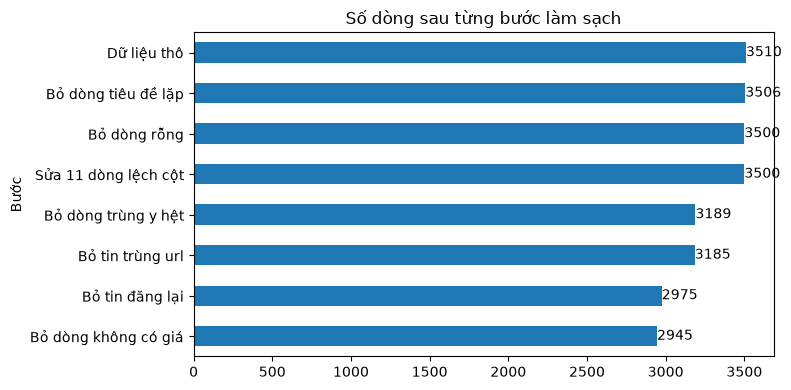

In [33]:
ax = steps.plot.barh(x="Bước", y="Số dòng", legend=False, figsize=(8, 4))
ax.invert_yaxis()
ax.bar_label(ax.containers[0])
ax.set_title("Số dòng sau từng bước làm sạch")
plt.tight_layout()

In [34]:
# So sánh cùng các căn trước và sau
o = clean["order"].astype(str).head(8).tolist()
show = ["order", "city", "district", "house_type", "area_m2", "floors", "bedrooms", "has_parking", "price_billion_vnd"]
print("TRƯỚC (dữ liệu thô)")
display(raw[raw["order"].isin(o)].drop_duplicates("order")[show])
print("SAU (dữ liệu sạch)")
clean[clean["order"].astype(str).isin(o)][show]

TRƯỚC (dữ liệu thô)


,order,city,district,house_type,area_m2,floors,bedrooms,has_parking,price_billion_vnd
0,1,Hà Nội,Quận Cầu Giấy,Nhà trong hẻm,0108,5.0,5.0,True,69.4 triệu/m²
1,2,Hà Nội,Hoàn Kiếm,Nhà mặt tiền,1100.0,1.0,3.0.0,False,27000
2,3,Hà Nội,Bắc Từ Liêm,Hẻm,25.0,4.0,3.0,False,
3,4,Hồ Chí Minh,Gò Vấp.,Nhà trong hẻm,24.0,2.0,2.0,0,"2,9 tỷ VNĐ"
4,5,Hà Nội,Quận Long Biên,Nhà mặt tiền,70.0,4.0,6.0,True,7.0
5,6,Hà Nội,HÀ ĐÔNG,Nhà trong hẻm,55.0,5.0,4.0,False,"11,000,000,000 đ"
6,7,Hà Nội,hoàng mai,Nhà trong hẻm,65.0,4.0,4+,False,6.18
7,8,Hồ Chí Minh,10,nhà ngõ,5.9x20.0,0.0,4.0,False,16.7


SAU (dữ liệu sạch)


,order,city,district,house_type,area_m2,floors,bedrooms,has_parking,price_billion_vnd
0,1,Hà Nội,Cầu Giấy,Nhà trong hẻm,108.0,5,5,True,7.495
1,2,Hà Nội,Hoàn Kiếm,Nhà mặt tiền,NaN,1,3,False,27.000
2,3,Hà Nội,Bắc Từ Liêm,Nhà trong hẻm,25.0,4,3,False,1.650
3,4,Hồ Chí Minh,Gò Vấp,Nhà trong hẻm,24.0,2,2,False,2.900
4,5,Hà Nội,Long Biên,Nhà mặt tiền,70.0,4,6,True,7.000
5,6,Hà Nội,Hà Đông,Nhà trong hẻm,55.0,5,4,False,11.000
6,7,Hà Nội,Hoàng Mai,Nhà trong hẻm,65.0,4,4,False,6.180
7,8,Hồ Chí Minh,Quận 10,Nhà trong hẻm,118.0,<NA>,4,False,16.700


In [35]:
# Số ô còn thiếu (sẽ điền ở bước mô hình hóa, sau khi chia train/test)
clean.isna().sum()[lambda s: s > 0].to_frame("Số ô thiếu")

,Số ô thiếu
title,8
posted_date,228
area_m2,6
width_m,846
length_m,1680
road_width_m,161
floors,226
bedrooms,188
has_dining_room,25
has_kitchen,41


# 4. Lưu kết quả
Tập dữ liệu sạch được ghi vào `data/processed/clean.csv`, nhật ký xử lý được ghi vào `reports/cleaning_log.csv`. Tệp dữ liệu gốc không bị thay đổi.

In [36]:
CLEAN_PATH.parent.mkdir(parents=True, exist_ok=True)
LOG_PATH.parent.mkdir(parents=True, exist_ok=True)
clean.to_csv(CLEAN_PATH, index=False, encoding="utf-8")
steps.rename(columns={"Bước": "buoc", "Số dòng": "so_dong"}).to_csv(LOG_PATH, index=False, encoding="utf-8")
print("Đã lưu", len(clean), "dòng vào", CLEAN_PATH.relative_to(ROOT))

Đã lưu 2945 dòng vào data/processed/clean.csv


# 5. Tiền xử lý dữ liệu (Bước 1 của đề tài)

Mục này thực hiện Bước 1 của đề tài trên tập dữ liệu đã làm sạch (`clean`): phân tích mất cân bằng dữ liệu, phân tích và biến đổi phân phối giá, xử lý dữ liệu vị trí và loại bỏ ngoại lai.

## 5.1 Phân tích mất cân bằng dữ liệu

**Mục đích:** xác định các nhóm dữ liệu có số mẫu chênh lệch lớn. Với bài toán hồi quy, nhóm ít mẫu khiến mô hình học kém ở vùng đó, và sai số trung bình trên toàn tập có thể che giấu sai số lớn ở nhóm thiểu số.

Mục này chỉ phân tích, không thay đổi dữ liệu.

### 5.1.1 Phân bố theo thành phố và loại nhà

Số bản ghi  Tỷ lệ (%)
Thành phố Hà Nội               1974       67.0
          Hồ Chí Minh           971       33.0
Loại nhà  Nhà trong hẻm        2024       68.7
          Nhà mặt tiền          921       31.3

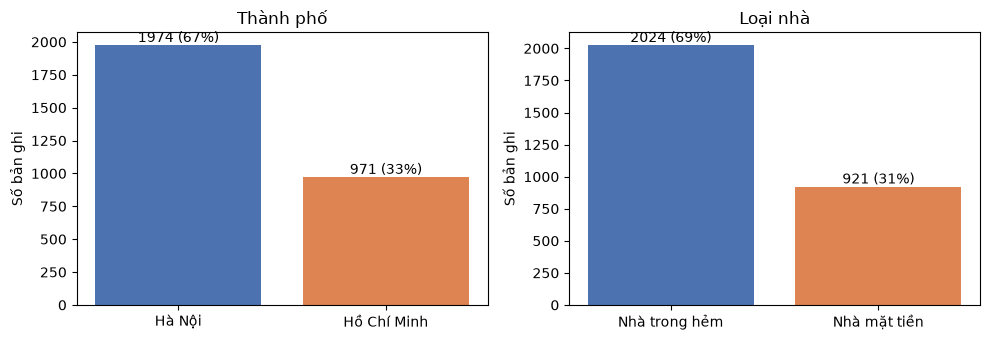

In [37]:
dist = pd.concat({
    "Thành phố": clean["city"].value_counts(),
    "Loại nhà": clean["house_type"].value_counts(),
}).to_frame("Số bản ghi")
dist["Tỷ lệ (%)"] = (dist["Số bản ghi"] / len(clean) * 100).round(1)
display(dist)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col, title in zip(axes, ["city", "house_type"], ["Thành phố", "Loại nhà"]):
    vc = clean[col].value_counts()
    ax.bar(vc.index, vc.values, color=["#4C72B0", "#DD8452"])
    ax.bar_label(ax.containers[0], labels=[f"{v} ({v / len(clean):.0%})" for v in vc.values])
    ax.set_title(title)
    ax.set_ylabel("Số bản ghi")
plt.tight_layout()

### 5.1.2 Phân bố theo quận/huyện

Số quận/huyện: 39
Nhiều mẫu nhất: Đống Đa (276 bản ghi)
Ít mẫu nhất   : Gia Lâm (1 bản ghi)
Số quận/huyện dưới 20 bản ghi: 15, tổng cộng 130 bản ghi (4.4%)


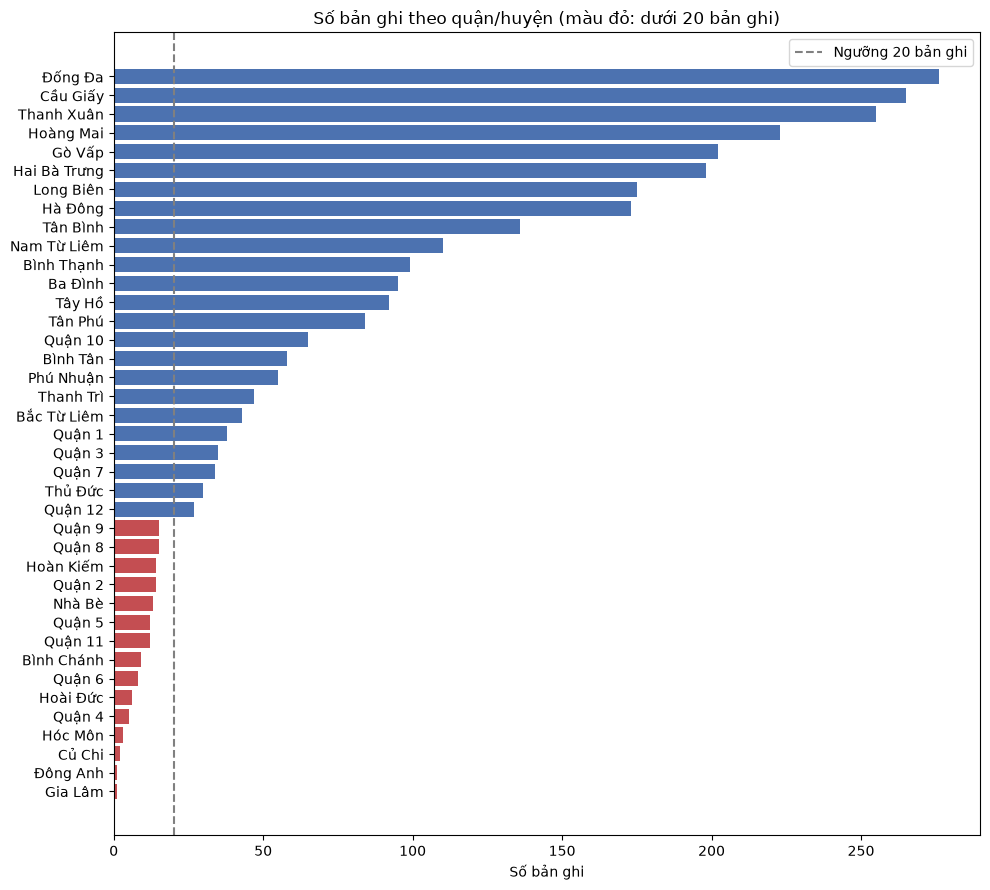

In [38]:
vc = clean["district"].value_counts()
few = vc[vc < 20]
print(f"Số quận/huyện: {len(vc)}")
print(f"Nhiều mẫu nhất: {vc.index[0]} ({vc.iloc[0]} bản ghi)")
print(f"Ít mẫu nhất   : {vc.index[-1]} ({vc.iloc[-1]} bản ghi)")
print(f"Số quận/huyện dưới 20 bản ghi: {len(few)}, tổng cộng {few.sum()} bản ghi ({few.sum() / len(clean):.1%})")

colors = ["#C44E52" if v < 20 else "#4C72B0" for v in vc.values]
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(vc.index[::-1], vc.values[::-1], color=colors[::-1])
ax.axvline(20, color="gray", linestyle="--", label="Ngưỡng 20 bản ghi")
ax.set_xlabel("Số bản ghi")
ax.set_title("Số bản ghi theo quận/huyện (màu đỏ: dưới 20 bản ghi)")
ax.legend()
plt.tight_layout()

### 5.1.3 Phân bố theo phân khúc giá

Giá được chia thành ba phân khúc: **dưới 5 tỷ**, **5–15 tỷ** và **trên 15 tỷ**. Biến phân khúc `price_segment` được dùng lại ở bước chia tập huấn luyện/kiểm thử (phân tầng) và bước đánh giá sai số theo phân khúc.

In [39]:
SEGMENT_BINS = [0, 5, 15, float("inf")]
SEGMENT_LABELS = ["Dưới 5 tỷ", "5–15 tỷ", "Trên 15 tỷ"]
clean["price_segment"] = pd.cut(clean["price_billion_vnd"], bins=SEGMENT_BINS,
                                labels=SEGMENT_LABELS, right=False)

seg = clean["price_segment"].value_counts().sort_index().to_frame("Số bản ghi")
seg["Tỷ lệ (%)"] = (seg["Số bản ghi"] / len(clean) * 100).round(1)
display(seg)
print("Độ lệch (skewness) của giá:", round(clean["price_billion_vnd"].skew(), 2))
print("Số bản ghi giá trên 30 tỷ :", (clean["price_billion_vnd"] > 30).sum())

,Số bản ghi,Tỷ lệ (%)
price_segment,,
Dưới 5 tỷ,1152,39.1
5–15 tỷ,1364,46.3
Trên 15 tỷ,429,14.6


Độ lệch (skewness) của giá: 2.26
Số bản ghi giá trên 30 tỷ : 72


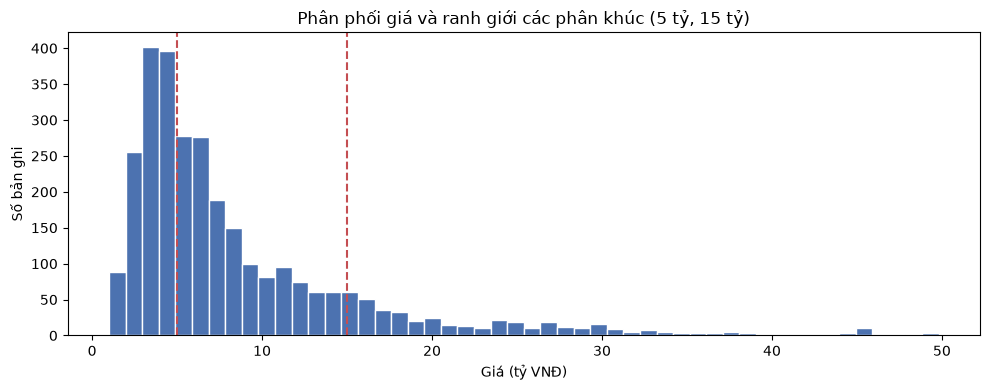

In [40]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(clean["price_billion_vnd"], bins=50, color="#4C72B0", edgecolor="white")
for b in SEGMENT_BINS[1:-1]:
    ax.axvline(b, color="#C44E52", linestyle="--")
ax.set_xlabel("Giá (tỷ VNĐ)")
ax.set_ylabel("Số bản ghi")
ax.set_title("Phân phối giá và ranh giới các phân khúc (5 tỷ, 15 tỷ)")
plt.tight_layout()

In [41]:
# Tỷ lệ phân khúc giá trong từng nhóm (%)
pd.concat({
    "Theo thành phố": (pd.crosstab(clean["price_segment"], clean["city"], normalize="columns") * 100).round(1),
    "Theo loại nhà": (pd.crosstab(clean["price_segment"], clean["house_type"], normalize="columns") * 100).round(1),
}, axis=1)

Theo thành phố             Theo loại nhà              
                      Hà Nội Hồ Chí Minh  Nhà mặt tiền Nhà trong hẻm
price_segment                                                       
Dưới 5 tỷ               43.1        31.1          15.4          49.9
5–15 tỷ                 43.8        51.4          46.8          46.1
Trên 15 tỷ              13.1        17.5          37.8           4.0

### 5.1.4 Nhận xét

**Kết quả phân tích:**
- **Thành phố:** Hà Nội chiếm 67%, TP.HCM 33%. Mức chênh lệch vừa phải, mỗi thành phố đều có gần 1.000 bản ghi trở lên.
- **Loại nhà:** nhà trong hẻm chiếm 69%, nhà mặt tiền 31%.
- **Quận/huyện:** mất cân bằng rõ rệt. Các quận nội thành Hà Nội có trên 250 bản ghi, trong khi 15 quận/huyện có dưới 20 bản ghi, chiếm 4,4% dữ liệu. Nhóm này gồm các huyện ngoại thành (Gia Lâm, Đông Anh, Củ Chi, Hóc Môn, Hoài Đức, Bình Chánh, Nhà Bè) và một số quận ít tin rao trong dữ liệu (Hoàn Kiếm, Quận 2, 4, 5, 6, 8, 9, 11). Gia Lâm và Đông Anh chỉ có 1 bản ghi.
- **Phân khúc giá:** phân khúc trên 15 tỷ chỉ chiếm khoảng 15% số bản ghi; phân phối giá lệch phải mạnh (skewness ≈ 2,26), chỉ 72 bản ghi có giá trên 30 tỷ.
- **Tương quan giữa các nhóm:** phân khúc trên 15 tỷ tập trung ở nhà mặt tiền (khoảng 38% nhà mặt tiền, so với khoảng 4% nhà trong hẻm).

**Ảnh hưởng tới mô hình hồi quy:**
- Mô hình học chủ yếu từ nhà giá dưới 15 tỷ, nên có xu hướng dự đoán thấp hơn thực tế ở phân khúc giá cao.
- Với các quận/huyện ít mẫu, mã hóa theo quận dễ gây quá khớp (*overfitting*).
- Chỉ số trung bình trên toàn tập (RMSE, R²) có thể che giấu sai số lớn ở phân khúc giá cao.

**Hướng xử lý trong các bước sau:**

| Vấn đề | Cách xử lý | Thực hiện ở |
|---|---|---|
| Phân phối giá lệch phải | Biến đổi Log1p / Box-Cox | 5.3 |
| Phân khúc giá cao ít mẫu | Chia tập huấn luyện/kiểm thử phân tầng theo `price_segment` | Bước 2 |
| Quận/huyện ít mẫu | Bổ sung khoảng cách tới trung tâm làm đặc trưng vị trí liên tục, ít phụ thuộc vào số mẫu từng quận | 5.4 |
| Sai số bị che giấu | Đánh giá sai số riêng theo từng phân khúc giá | Bước 3 |

## 5.2 Phân tích phân phối giá

**Mục đích:** mô tả đặc điểm thống kê của biến mục tiêu và các biến số, kiểm tra mức độ lệch của giá, và xem giá thay đổi thế nào theo thành phố, loại nhà, quận/huyện.

### 5.2.1 Thống kê mô tả

In [42]:
NUM_COLS = ["area_m2", "width_m", "length_m", "road_width_m", "floors", "bedrooms", "price_billion_vnd"]
desc = clean[NUM_COLS].astype(float).describe().T
desc["thiếu (%)"] = (clean[NUM_COLS].isna().mean() * 100).round(1)
desc["skewness"] = clean[NUM_COLS].astype(float).skew()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,thiếu (%),skewness
area_m2,2939.0,61.79,41.27,14.4,41.0,54.0,72.0,1000.0,0.2,11.28
width_m,2099.0,4.71,1.34,2.2,4.0,4.2,5.0,20.0,28.7,2.84
length_m,1265.0,14.01,4.62,3.3,10.0,13.5,17.0,30.0,57.0,0.56
road_width_m,2784.0,6.39,4.49,1.0,3.0,5.0,8.0,20.0,5.5,1.60
floors,2719.0,4.03,1.52,1.0,3.0,4.0,5.0,10.0,7.7,-0.12
bedrooms,2757.0,4.18,1.66,1.0,3.0,4.0,5.0,10.0,6.4,1.00
price_billion_vnd,2945.0,8.62,7.48,1.0,3.9,6.0,10.6,49.8,0.0,2.26


### 5.2.2 Histogram và Q-Q plot của giá
Q-Q plot so sánh phân vị của dữ liệu với phân vị của phân phối chuẩn. Nếu dữ liệu có phân phối chuẩn, các điểm nằm trên đường thẳng.

Độ lệch (skewness): 2.261
Độ nhọn (kurtosis): 6.107
Trung bình: 8.62 tỷ | Trung vị: 6.00 tỷ


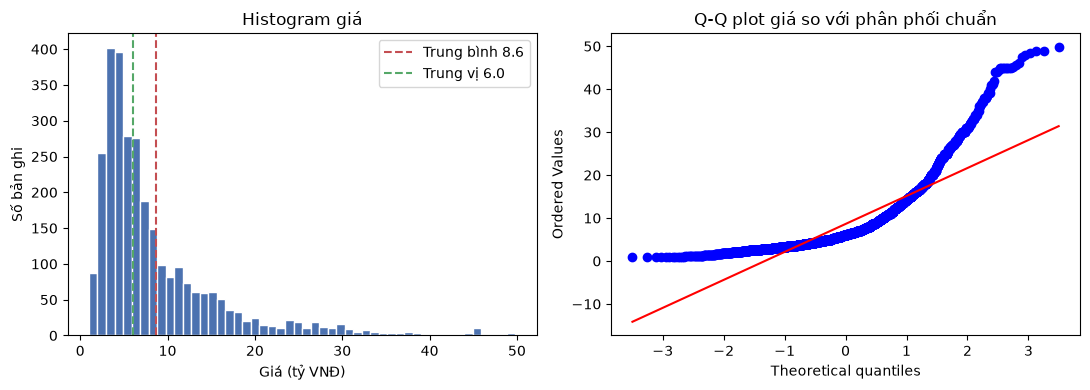

In [43]:
price = clean["price_billion_vnd"].astype(float)
print(f"Độ lệch (skewness): {stats.skew(price):.3f}")
print(f"Độ nhọn (kurtosis): {stats.kurtosis(price):.3f}")
print(f"Trung bình: {price.mean():.2f} tỷ | Trung vị: {price.median():.2f} tỷ")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(price, bins=50, color="#4C72B0", edgecolor="white")
axes[0].axvline(price.mean(), color="#C44E52", linestyle="--", label=f"Trung bình {price.mean():.1f}")
axes[0].axvline(price.median(), color="#55A868", linestyle="--", label=f"Trung vị {price.median():.1f}")
axes[0].set_xlabel("Giá (tỷ VNĐ)")
axes[0].set_ylabel("Số bản ghi")
axes[0].set_title("Histogram giá")
axes[0].legend()
stats.probplot(price, dist="norm", plot=axes[1])
axes[1].set_title("Q-Q plot giá so với phân phối chuẩn")
plt.tight_layout()

### 5.2.3 Giá theo thành phố, loại nhà và quận/huyện

count  median   mean
city        house_type                         
Hà Nội      Nhà mặt tiền     553    11.5  14.29
            Nhà trong hẻm   1421     4.6   5.81
Hồ Chí Minh Nhà mặt tiền     368    12.5  14.17
            Nhà trong hẻm    603     5.9   6.67

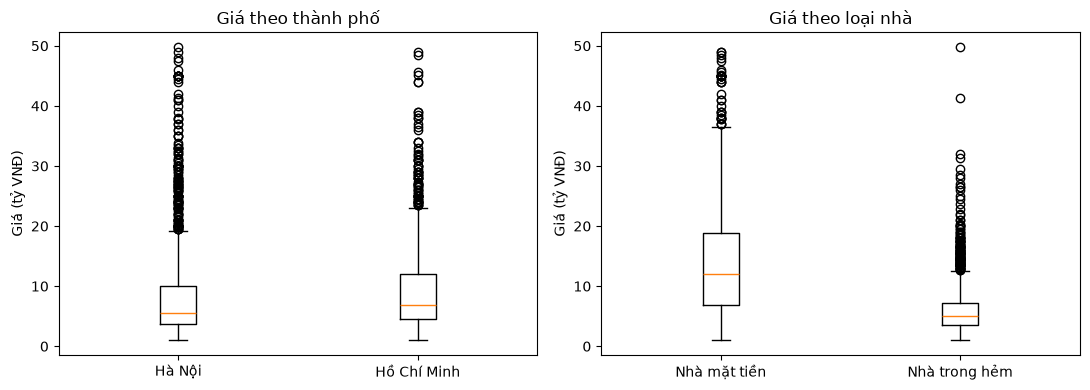

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in zip(axes, ["city", "house_type"], ["Thành phố", "Loại nhà"]):
    groups = [g["price_billion_vnd"].values for _, g in clean.groupby(col)]
    ax.boxplot(groups, tick_labels=sorted(clean[col].dropna().unique()), showfliers=True)
    ax.set_title(f"Giá theo {title.lower()}")
    ax.set_ylabel("Giá (tỷ VNĐ)")
plt.tight_layout()

clean.groupby(["city", "house_type"])["price_billion_vnd"].agg(["count", "median", "mean"]).round(2)

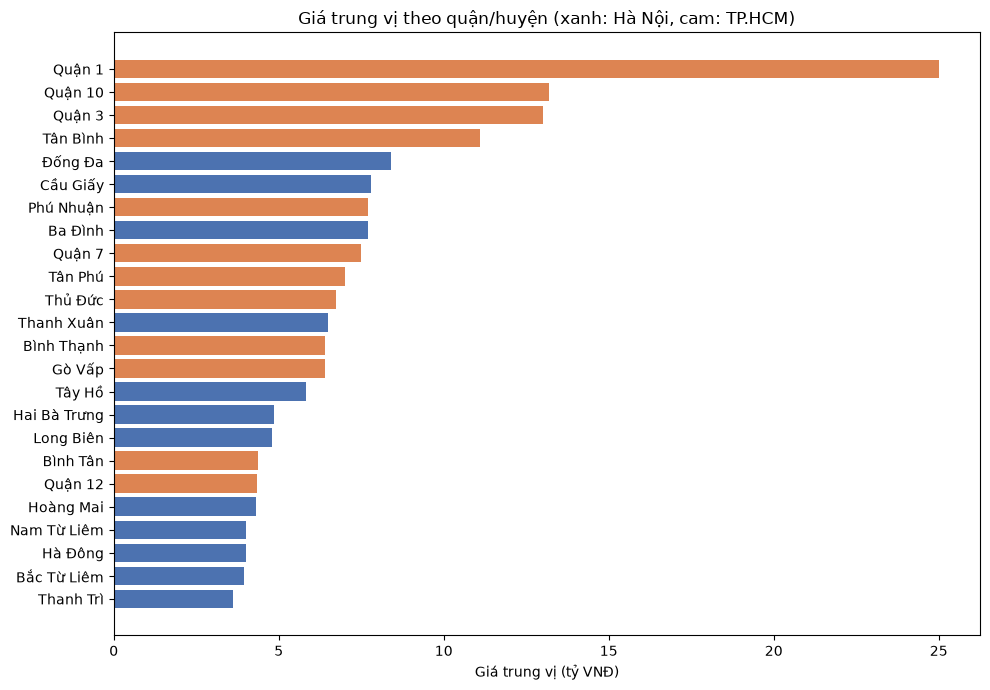

In [45]:
# Giá trung vị theo quận/huyện (chỉ quận có từ 20 bản ghi)
by_d = clean.groupby(["city", "district"])["price_billion_vnd"].agg(["count", "median"])
by_d = by_d[by_d["count"] >= 20].sort_values("median")

fig, ax = plt.subplots(figsize=(10, 7))
colors = ["#4C72B0" if c == "Hà Nội" else "#DD8452" for c in by_d.index.get_level_values(0)]
ax.barh([d for _, d in by_d.index], by_d["median"], color=colors)
ax.set_xlabel("Giá trung vị (tỷ VNĐ)")
ax.set_title("Giá trung vị theo quận/huyện (xanh: Hà Nội, cam: TP.HCM)")
plt.tight_layout()

### 5.2.4 Tương quan giữa các biến số
Hệ số tương quan Pearson giữa các biến số và giá.

,tương quan với giá
road_width_m,0.605
length_m,0.401
width_m,0.359
bedrooms,0.341
area_m2,0.336
floors,0.175


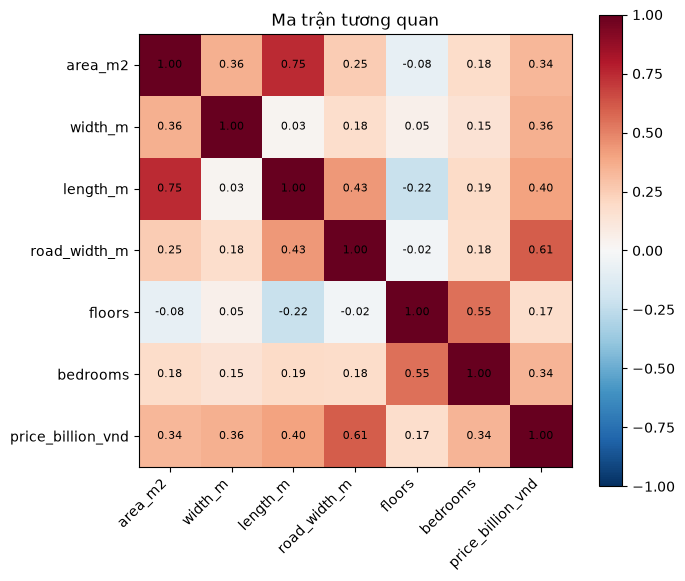

In [46]:
corr = clean[NUM_COLS].astype(float).corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(NUM_COLS)), NUM_COLS, rotation=45, ha="right")
ax.set_yticks(range(len(NUM_COLS)), NUM_COLS)
for i in range(len(NUM_COLS)):
    for j in range(len(NUM_COLS)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im)
ax.set_title("Ma trận tương quan")
plt.tight_layout()

corr["price_billion_vnd"].drop("price_billion_vnd").sort_values(ascending=False).to_frame("tương quan với giá").round(3)

### 5.2.5 Nhận xét

- **Giá lệch phải mạnh:** skewness ≈ 2,26, trung bình (8,6 tỷ) lớn hơn trung vị (6 tỷ). Q-Q plot cong lên ở phần đuôi phải: có ít căn giá rất cao kéo phân phối lệch về bên phải. Các mô hình tuyến tính (Ridge, Lasso, ElasticNet) giả định sai số phân phối chuẩn và phương sai đồng nhất, nên cần biến đổi giá trước khi mô hình hóa (mục 5.3).
- **Loại nhà ảnh hưởng mạnh tới giá:** nhà mặt tiền có giá trung vị cao gấp khoảng 2,5 lần nhà trong hẻm ở Hà Nội (11,5 so với 4,6 tỷ) và khoảng 2,1 lần ở TP.HCM (12,5 so với 5,9 tỷ).
- **Vị trí ảnh hưởng mạnh tới giá:** giá trung vị chênh lệch nhiều lần giữa các quận/huyện, từ khoảng 3,6 tỷ (Thanh Trì) tới 25 tỷ (Quận 1); các quận trung tâm có giá cao nhất. Đây là cơ sở để bổ sung đặc trưng khoảng cách tới trung tâm (mục 5.4).
- **Tương quan:** độ rộng đường trước nhà có tương quan mạnh nhất với giá (≈ 0,6), tiếp theo là kích thước và diện tích (≈ 0,3–0,4). Số tầng tương quan yếu.

## 5.3 Biến đổi phân phối giá: Log1p và Box-Cox

**Log1p:** $y' = \ln(1 + y)$. Không có tham số; dễ đảo ngược bằng $y = e^{y'} - 1$.

**Box-Cox:** $y' = \dfrac{y^\lambda - 1}{\lambda}$ (với $\lambda \ne 0$), $y' = \ln y$ (với $\lambda = 0$). Tham số $\lambda$ được ước lượng bằng hợp lý cực đại để phân phối sau biến đổi gần chuẩn nhất. Chỉ áp dụng được khi $y > 0$ (thỏa mãn vì giá thấp nhất là 1 tỷ).

**Tiêu chí so sánh:** độ lệch (càng gần 0 càng tốt) và hệ số tương quan $r$ của Q-Q plot (càng gần 1 càng gần phân phối chuẩn).

In [47]:
y_log = np.log1p(price)
y_bc, bc_lambda = stats.boxcox(price)
print(f"λ Box-Cox ước lượng: {bc_lambda:.4f}")

compare = pd.DataFrame({
    "Phương pháp": ["Giá gốc", "Log1p", "Box-Cox"],
    "Skewness": [stats.skew(price), stats.skew(y_log), stats.skew(y_bc)],
    "Kurtosis": [stats.kurtosis(price), stats.kurtosis(y_log), stats.kurtosis(y_bc)],
    "Hệ số r của Q-Q plot": [stats.probplot(v)[1][2] for v in (price, y_log, y_bc)],
}).round(4)
compare

λ Box-Cox ước lượng: -0.1682


,Phương pháp,Skewness,Kurtosis,Hệ số r của Q-Q plot
0,Giá gốc,2.2610,6.1073,0.8698
1,Log1p,0.5725,-0.0732,0.9863
2,Box-Cox,0.0077,-0.1306,0.9973


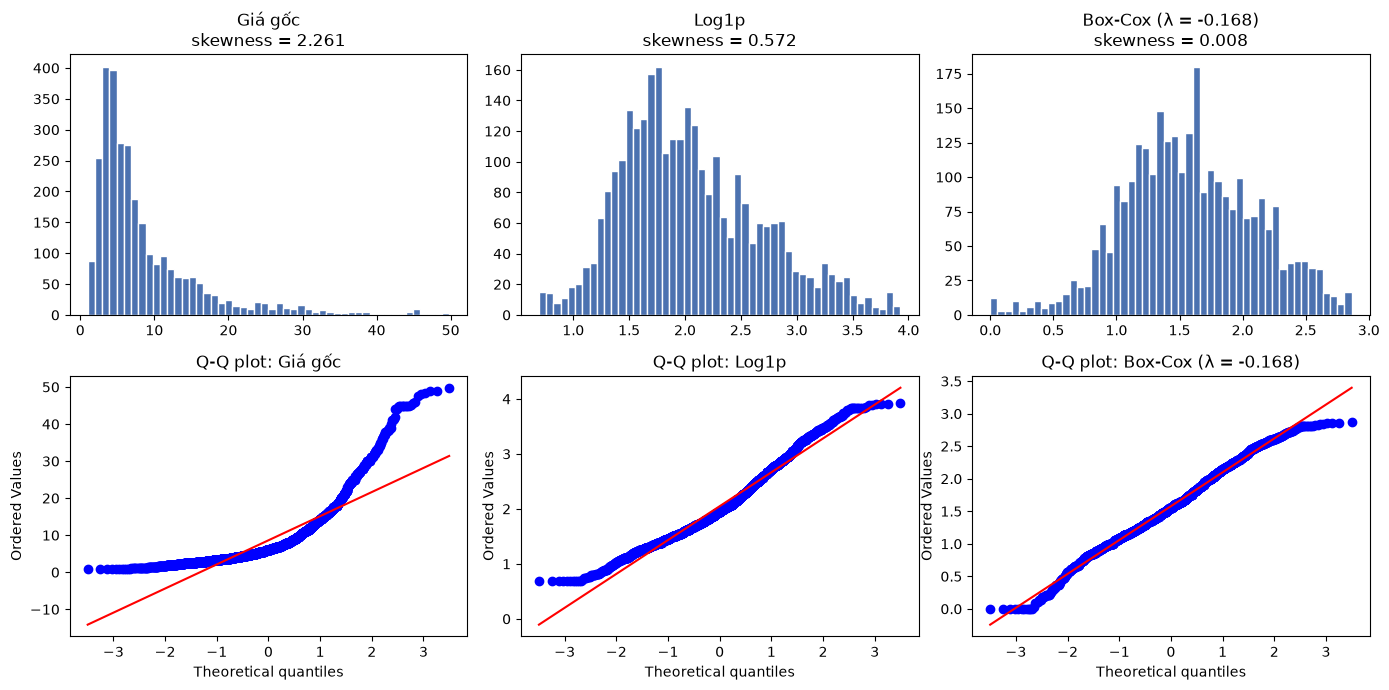

In [48]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for k, (name, v) in enumerate([("Giá gốc", price), ("Log1p", y_log), (f"Box-Cox (λ = {bc_lambda:.3f})", y_bc)]):
    axes[0, k].hist(v, bins=50, color="#4C72B0", edgecolor="white")
    axes[0, k].set_title(f"{name}\nskewness = {stats.skew(v):.3f}")
    stats.probplot(v, dist="norm", plot=axes[1, k])
    axes[1, k].set_title(f"Q-Q plot: {name}")
plt.tight_layout()

### Nhận xét và lựa chọn

- **Log1p** giảm độ lệch từ 2,26 xuống khoảng 0,57: phân phối vẫn còn lệch phải nhẹ.
- **Box-Cox** đưa độ lệch về gần 0 và có hệ số $r$ của Q-Q plot cao nhất: phân phối sau biến đổi gần chuẩn nhất.
- $\lambda$ ước lượng âm và gần 0, cho thấy biến đổi tối ưu mạnh hơn logarit một chút.

**Lựa chọn sơ bộ:** Box-Cox, vì cho phân phối gần chuẩn nhất.

**Phản biện:** hình dạng phân phối chưa phải tiêu chí cuối cùng. Mục tiêu của bài toán là dự đoán giá trên đơn vị tỷ VNĐ, nên lựa chọn được kiểm chứng lại bằng sai số dự đoán ở mục 6.2. Ngoài ra Box-Cox có tham số $\lambda$ phải ước lượng từ dữ liệu; để tránh rò rỉ thông tin, $\lambda$ chỉ được ước lượng trên tập huấn luyện (bằng `PowerTransformer(method="box-cox")` trong pipeline). Log1p không có tham số nên không có vấn đề này.

## 5.4 Xử lý dữ liệu vị trí: tọa độ và khoảng cách tới trung tâm

**Vấn đề:** dữ liệu chỉ có vị trí ở cấp quận/huyện. Quận/huyện là biến phân loại với 39 giá trị, nhiều quận rất ít mẫu (mục 5.1.2), nên khó học được ảnh hưởng của vị trí.

**Xử lý:** gán cho mỗi quận/huyện tọa độ tâm (vĩ độ, kinh độ), rồi tính khoảng cách tới trung tâm thành phố. Khoảng cách là biến số liên tục, giúp mô hình tổng quát hóa cho cả những quận ít mẫu.

**Nguồn tọa độ:** ranh giới hành chính quận/huyện trên OpenStreetMap, truy vấn qua dịch vụ geocoding Photon (photon.komoot.io). Tọa độ được lưu cố định trong notebook để kết quả tái lập được và không cần kết nối mạng khi chạy.

**Mốc trung tâm:** Hồ Hoàn Kiếm (Hà Nội) và chợ Bến Thành (TP.HCM).

**Lưu ý:** Quận 2 và Quận 9 đã sáp nhập vào TP Thủ Đức từ năm 2021, OpenStreetMap không còn ranh giới riêng; tọa độ hai quận này là giá trị xấp xỉ vị trí trung tâm quận cũ.

In [49]:
DISTRICT_COORDS = pd.DataFrame([
    # Hà Nội
    ("Hà Nội", "Ba Đình", 21.03478, 105.82455), ("Hà Nội", "Bắc Từ Liêm", 21.07301, 105.76140),
    ("Hà Nội", "Cầu Giấy", 21.02985, 105.79133), ("Hà Nội", "Gia Lâm", 21.02390, 105.97060),
    ("Hà Nội", "Hai Bà Trưng", 21.00545, 105.86062), ("Hà Nội", "Hoài Đức", 21.02290, 105.70355),
    ("Hà Nội", "Hoàn Kiếm", 21.03078, 105.85406), ("Hà Nội", "Hoàng Mai", 20.97539, 105.85734),
    ("Hà Nội", "Hà Đông", 20.95407, 105.76009), ("Hà Nội", "Long Biên", 21.03673, 105.89850),
    ("Hà Nội", "Nam Từ Liêm", 21.01857, 105.75761), ("Hà Nội", "Thanh Trì", 20.94156, 105.83602),
    ("Hà Nội", "Thanh Xuân", 20.99422, 105.81930), ("Hà Nội", "Tây Hồ", 21.06827, 105.82396),
    ("Hà Nội", "Đông Anh", 21.13650, 105.84580), ("Hà Nội", "Đống Đa", 21.01451, 105.82341),
    # TP.HCM
    ("Hồ Chí Minh", "Bình Chánh", 10.74950, 106.51460), ("Hồ Chí Minh", "Bình Thạnh", 10.81227, 106.70404),
    ("Hồ Chí Minh", "Bình Tân", 10.77035, 106.59958), ("Hồ Chí Minh", "Củ Chi", 11.03730, 106.50210),
    ("Hồ Chí Minh", "Gò Vấp", 10.83535, 106.67403), ("Hồ Chí Minh", "Hóc Môn", 10.87773, 106.57605),
    ("Hồ Chí Minh", "Nhà Bè", 10.65100, 106.72586), ("Hồ Chí Minh", "Phú Nhuận", 10.80101, 106.68000),
    ("Hồ Chí Minh", "Quận 1", 10.77539, 106.69963), ("Hồ Chí Minh", "Quận 2", 10.78720, 106.74980),
    ("Hồ Chí Minh", "Quận 3", 10.77902, 106.68695), ("Hồ Chí Minh", "Quận 4", 10.76075, 106.70708),
    ("Hồ Chí Minh", "Quận 5", 10.75583, 106.66828), ("Hồ Chí Minh", "Quận 6", 10.74573, 106.63908),
    ("Hồ Chí Minh", "Quận 7", 10.73785, 106.72970), ("Hồ Chí Minh", "Quận 8", 10.72112, 106.62921),
    ("Hồ Chí Minh", "Quận 9", 10.84020, 106.81800), ("Hồ Chí Minh", "Quận 10", 10.77253, 106.66820),
    ("Hồ Chí Minh", "Quận 11", 10.76563, 106.64761), ("Hồ Chí Minh", "Quận 12", 10.86127, 106.66421),
    ("Hồ Chí Minh", "Thủ Đức", 10.82050, 106.81390), ("Hồ Chí Minh", "Tân Bình", 10.80312, 106.65251),
    ("Hồ Chí Minh", "Tân Phú", 10.79187, 106.62775),
], columns=["city", "district", "lat", "lon"])

CITY_CENTER = {"Hà Nội": (21.02870, 105.85240),        # Hồ Hoàn Kiếm
               "Hồ Chí Minh": (10.77250, 106.69800)}   # Chợ Bến Thành

missing = set(clean["district"].dropna()) - set(DISTRICT_COORDS["district"])
print("Số quận/huyện có tọa độ:", len(DISTRICT_COORDS))
print("Quận/huyện trong dữ liệu chưa có tọa độ:", missing or "không có")

Số quận/huyện có tọa độ: 39
Quận/huyện trong dữ liệu chưa có tọa độ: không có


### Khoảng cách tới trung tâm
Khoảng cách được tính bằng công thức Haversine (khoảng cách đường tròn lớn trên mặt cầu Trái Đất, bán kính 6.371 km):

$$d = 2R \arcsin\sqrt{\sin^2\frac{\Delta\varphi}{2} + \cos\varphi_1 \cos\varphi_2 \sin^2\frac{\Delta\lambda}{2}}$$

In [50]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))


DISTRICT_COORDS["dist_center_km"] = [
    haversine_km(r.lat, r.lon, *CITY_CENTER[r.city]) for r in DISTRICT_COORDS.itertuples()
]
clean = clean.drop(columns=["lat", "lon", "dist_center_km"], errors="ignore").merge(
    DISTRICT_COORDS, on=["city", "district"], how="left")

print("Số bản ghi chưa có khoảng cách (quận/huyện trống):", clean["dist_center_km"].isna().sum())
DISTRICT_COORDS.sort_values(["city", "dist_center_km"]).round(2)

Số bản ghi chưa có khoảng cách (quận/huyện trống): 0


,city,district,lat,lon,dist_center_km
6,Hà Nội,Hoàn Kiếm,21.03,105.85,0.29
4,Hà Nội,Hai Bà Trưng,21.01,105.86,2.72
0,Hà Nội,Ba Đình,21.03,105.82,2.97
15,Hà Nội,Đống Đa,21.01,105.82,3.40
9,Hà Nội,Long Biên,21.04,105.90,4.87
12,Hà Nội,Thanh Xuân,20.99,105.82,5.15
13,Hà Nội,Tây Hồ,21.07,105.82,5.30
7,Hà Nội,Hoàng Mai,20.98,105.86,5.95
2,Hà Nội,Cầu Giấy,21.03,105.79,6.34
11,Hà Nội,Thanh Trì,20.94,105.84,9.84


Tương quan Spearman giữa khoảng cách và giá/m²:
  Hà Nội      : ρ = -0.211 (p = 2.8e-21)
  Hồ Chí Minh : ρ = -0.544 (p = 7.5e-76)


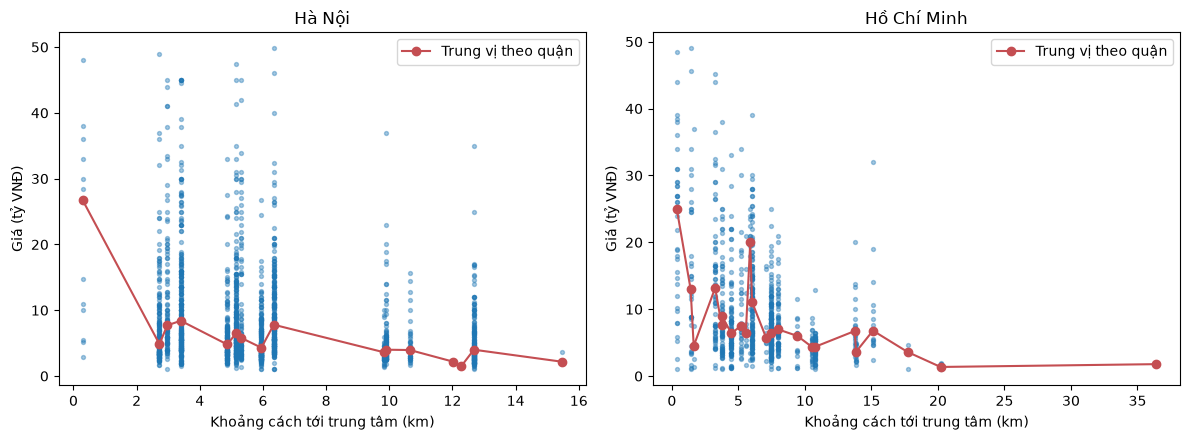

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (city, g) in zip(axes, clean.groupby("city")):
    ax.scatter(g["dist_center_km"], g["price_billion_vnd"], s=8, alpha=0.4)
    med = g.groupby("dist_center_km")["price_billion_vnd"].median()
    ax.plot(med.index, med.values, "o-", color="#C44E52", label="Trung vị theo quận")
    ax.set_title(city)
    ax.set_xlabel("Khoảng cách tới trung tâm (km)")
    ax.set_ylabel("Giá (tỷ VNĐ)")
    ax.legend()
plt.tight_layout()

ppm2 = clean["price_billion_vnd"] * 1000 / clean["area_m2"]
print("Tương quan Spearman giữa khoảng cách và giá/m²:")
for city, g in clean.assign(ppm2=ppm2).groupby("city"):
    r, p = stats.spearmanr(g["dist_center_km"], g["ppm2"], nan_policy="omit")
    print(f"  {city:12}: ρ = {r:.3f} (p = {p:.1e})")

### Nhận xét
- Giá/m² giảm khi khoảng cách tới trung tâm tăng ở cả hai thành phố (tương quan Spearman âm, có ý nghĩa thống kê với p < 0,001). Mức tương quan ở TP.HCM là trung bình (ρ ≈ −0,54), ở Hà Nội là yếu (ρ ≈ −0,21). Kết quả này phù hợp với lý thuyết định giá hedonic: vị trí gần trung tâm là một thuộc tính có giá trị. Tương quan yếu hơn ở Hà Nội có thể do thành phố có nhiều khu vực giá cao không nằm sát trung tâm (ví dụ Cầu Giấy, Tây Hồ).
- Dùng **giá/m²** khi kiểm tra tương quan để loại ảnh hưởng của diện tích; giá/m² chỉ dùng cho phân tích, không đưa vào mô hình (mục 5.6).

**Hạn chế:** vị trí chỉ ở cấp quận/huyện, nên mọi căn trong cùng quận có cùng khoảng cách. Đặc trưng này không phân biệt được hai căn ở hai đầu một quận lớn (ví dụ Hà Đông, Thủ Đức).

### 5.4.3 Tiện ích xung quanh

**Vấn đề:** mục tiêu bài toán yêu cầu định giá dựa trên cả **tiện ích xung quanh**. Dữ liệu tin rao chỉ có tiện ích bên trong căn nhà (bếp, sân thượng, chỗ đỗ ô tô).

**Xử lý:** đếm số tiện ích trong **bán kính 2 km quanh tâm mỗi quận/huyện**, theo 5 nhóm:

| Thuộc tính | Tiện ích (thẻ OpenStreetMap) |
|---|---|
| `n_schools` | Trường mầm non, phổ thông, cao đẳng, đại học (`amenity=kindergarten/school/college/university`) |
| `n_health` | Bệnh viện, phòng khám (`amenity=hospital/clinic/doctors`) |
| `n_markets` | Chợ, siêu thị, trung tâm thương mại, cửa hàng tiện lợi (`amenity=marketplace`, `shop=supermarket/mall/department_store/convenience`) |
| `n_parks` | Công viên (`leisure=park`) |
| `n_transit` | Trạm xe buýt, ga tàu/metro (`highway=bus_stop`, `railway=station/halt`) |

**Nguồn:** bản trích xuất OpenStreetMap Việt Nam ngày 19/11/2026 (Geofabrik, `vietnam-261119.osm.pbf`). Số liệu được đếm một lần và lưu cố định dưới đây để notebook chạy không cần tải lại tệp bản đồ (khoảng 333 MB).

**Hạn chế:**
- Vị trí chỉ ở cấp quận/huyện nên mọi căn trong cùng quận có cùng số tiện ích.
- Dữ liệu OpenStreetMap ở Việt Nam chưa đầy đủ đồng đều, đặc biệt ở ngoại thành; số đếm phản ánh mức độ được ghi nhận trên bản đồ, không phải số lượng thực tế tuyệt đối.
- Tâm của các huyện rộng (Bình Chánh, Củ Chi, Nhà Bè) và TP Thủ Đức nằm xa khu dân cư chính nên số đếm thấp.

In [52]:
AMENITY_COLS = ["n_schools", "n_health", "n_markets", "n_parks", "n_transit"]
DISTRICT_AMENITIES = pd.DataFrame([
    ("Hà Nội", "Ba Đình", 83, 25, 107, 25, 118),
    ("Hà Nội", "Bắc Từ Liêm", 19, 7, 23, 1, 26),
    ("Hà Nội", "Cầu Giấy", 113, 20, 134, 29, 176),
    ("Hà Nội", "Gia Lâm", 13, 3, 2, 1, 36),
    ("Hà Nội", "Hai Bà Trưng", 101, 39, 195, 23, 132),
    ("Hà Nội", "Hoài Đức", 7, 0, 2, 2, 13),
    ("Hà Nội", "Hoàn Kiếm", 78, 34, 204, 25, 155),
    ("Hà Nội", "Hoàng Mai", 48, 14, 64, 25, 104),
    ("Hà Nội", "Hà Đông", 25, 3, 27, 7, 66),
    ("Hà Nội", "Long Biên", 37, 6, 40, 22, 79),
    ("Hà Nội", "Nam Từ Liêm", 39, 10, 37, 10, 60),
    ("Hà Nội", "Thanh Trì", 34, 7, 17, 1, 59),
    ("Hà Nội", "Thanh Xuân", 87, 19, 139, 9, 119),
    ("Hà Nội", "Tây Hồ", 22, 4, 47, 7, 57),
    ("Hà Nội", "Đông Anh", 15, 1, 4, 5, 33),
    ("Hà Nội", "Đống Đa", 127, 34, 144, 23, 163),
    ("Hồ Chí Minh", "Bình Chánh", 1, 0, 0, 0, 0),
    ("Hồ Chí Minh", "Bình Thạnh", 46, 7, 63, 17, 152),
    ("Hồ Chí Minh", "Bình Tân", 18, 1, 33, 2, 104),
    ("Hồ Chí Minh", "Củ Chi", 0, 0, 0, 0, 6),
    ("Hồ Chí Minh", "Gò Vấp", 35, 9, 50, 25, 119),
    ("Hồ Chí Minh", "Hóc Môn", 14, 2, 3, 1, 48),
    ("Hồ Chí Minh", "Nhà Bè", 2, 0, 0, 0, 18),
    ("Hồ Chí Minh", "Phú Nhuận", 94, 28, 126, 14, 166),
    ("Hồ Chí Minh", "Quận 1", 122, 45, 242, 50, 288),
    ("Hồ Chí Minh", "Quận 2", 23, 6, 62, 21, 102),
    ("Hồ Chí Minh", "Quận 3", 143, 50, 262, 32, 313),
    ("Hồ Chí Minh", "Quận 4", 70, 22, 186, 53, 213),
    ("Hồ Chí Minh", "Quận 5", 137, 107, 110, 43, 278),
    ("Hồ Chí Minh", "Quận 6", 92, 20, 52, 50, 172),
    ("Hồ Chí Minh", "Quận 7", 34, 9, 58, 33, 82),
    ("Hồ Chí Minh", "Quận 8", 27, 2, 26, 33, 87),
    ("Hồ Chí Minh", "Quận 9", 12, 1, 16, 3, 60),
    ("Hồ Chí Minh", "Quận 10", 137, 55, 128, 33, 236),
    ("Hồ Chí Minh", "Quận 11", 116, 37, 67, 38, 223),
    ("Hồ Chí Minh", "Quận 12", 31, 3, 25, 9, 81),
    ("Hồ Chí Minh", "Thủ Đức", 3, 1, 12, 4, 52),
    ("Hồ Chí Minh", "Tân Bình", 66, 9, 59, 24, 115),
    ("Hồ Chí Minh", "Tân Phú", 69, 8, 50, 51, 183),
], columns=["city", "district", *AMENITY_COLS])

clean = clean.drop(columns=AMENITY_COLS, errors="ignore").merge(DISTRICT_AMENITIES, on=["city", "district"], how="left")
DISTRICT_COORDS = DISTRICT_COORDS.drop(columns=AMENITY_COLS, errors="ignore").merge(
    DISTRICT_AMENITIES, on=["city", "district"], how="left")

print("Số bản ghi chưa có số liệu tiện ích:", clean[AMENITY_COLS].isna().any(axis=1).sum())
DISTRICT_AMENITIES.set_index(["city", "district"]).sort_values("n_transit", ascending=False).head(10)

Số bản ghi chưa có số liệu tiện ích: 0


n_schools  n_health  n_markets  n_parks  n_transit
city        district                                                     
Hồ Chí Minh Quận 3           143        50        262       32        313
            Quận 1           122        45        242       50        288
            Quận 5           137       107        110       43        278
            Quận 10          137        55        128       33        236
            Quận 11          116        37         67       38        223
            Quận 4            70        22        186       53        213
            Tân Phú           69         8         50       51        183
Hà Nội      Cầu Giấy         113        20        134       29        176
Hồ Chí Minh Quận 6            92        20         52       50        172
            Phú Nhuận         94        28        126       14        166

Thành phố,Hà Nội,Hồ Chí Minh
Thuộc tính,,
dist_center_km,-0.211,-0.544
n_health,0.314,0.484
n_markets,0.324,0.564
n_parks,0.222,0.259
n_schools,0.348,0.518
n_transit,0.349,0.405


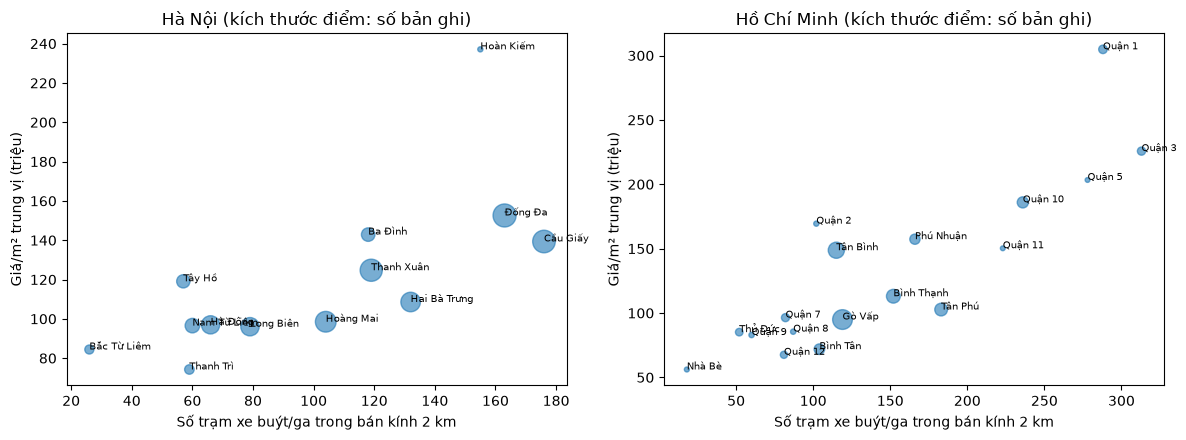

In [53]:
ppm2 = clean["price_billion_vnd"] * 1000 / clean["area_m2"]
rows = []
for city, g in clean.assign(ppm2=ppm2).groupby("city"):
    for c in AMENITY_COLS + ["dist_center_km"]:
        r, p = stats.spearmanr(g[c], g["ppm2"], nan_policy="omit")
        rows.append({"Thành phố": city, "Thuộc tính": c, "ρ Spearman với giá/m²": r, "p-value": p})
amen_corr = pd.DataFrame(rows).pivot(index="Thuộc tính", columns="Thành phố", values="ρ Spearman với giá/m²")
display(amen_corr.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (city, g) in zip(axes, clean.assign(ppm2=ppm2).groupby("city")):
    med = g.groupby("district").agg(n=("n_transit", "first"), ppm2=("ppm2", "median"), cnt=("ppm2", "size"))
    med = med[med["cnt"] >= 10]
    ax.scatter(med["n"], med["ppm2"], s=med["cnt"], alpha=0.6)
    for d, r in med.iterrows():
        ax.annotate(d, (r["n"], r["ppm2"]), fontsize=7)
    ax.set_xlabel("Số trạm xe buýt/ga trong bán kính 2 km")
    ax.set_ylabel("Giá/m² trung vị (triệu)")
    ax.set_title(f"{city} (kích thước điểm: số bản ghi)")
plt.tight_layout()

### Nhận xét
- Các quận có nhiều tiện ích xung quanh có giá/m² cao hơn: tương quan Spearman dương ở cả hai thành phố cho cả 5 nhóm tiện ích.
- Số tiện ích tương quan chặt với khoảng cách tới trung tâm (các quận trung tâm có mật độ tiện ích cao nhất), nên một phần thông tin của tiện ích đã nằm trong khoảng cách. Đóng góp riêng của tiện ích được kiểm chứng bằng mô hình ở mục 6.3.5.

## 5.5 Loại bỏ ngoại lai: IQR và khoảng cách Mahalanobis

Ngoại lai ở đây là các bản ghi có tổ hợp giá, diện tích, số tầng, số phòng bất thường, nhiều khả năng do nhập sai (ví dụ diện tích bị gõ thừa số 0 mà bước làm sạch không đối chiếu được).

Hai phương pháp được áp dụng và so sánh:

| Phương pháp | Biến dùng | Ngưỡng |
|---|---|---|
| **IQR** (đơn biến) | log(giá/m²), tính riêng từng thành phố | ngoài khoảng $[Q_1 - 1{,}5 \cdot IQR,\ Q_3 + 1{,}5 \cdot IQR]$ |
| **Mahalanobis** (đa biến) | log(diện tích), log(giá/m²), số tầng, số phòng ngủ | $D^2 > \chi^2_{0{,}975}(4)$ |

Giá/m² được lấy logarit vì phân phối của nó cũng lệch phải; nếu dùng giá/m² gốc, IQR sẽ đánh dấu nhầm nhiều căn cao cấp hợp lệ.

### 5.5.1 Phương pháp IQR

In [54]:
work = clean.copy()
work["log_ppm2"] = np.log(work["price_billion_vnd"] * 1000 / work["area_m2"])

iqr_flag = pd.Series(False, index=work.index)
bounds = []
for city, g in work.groupby("city"):
    v = g["log_ppm2"].dropna()
    q1, q3 = v.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_flag[v.index] = (v < lo) | (v > hi)
    bounds.append({"Thành phố": city, "Giá/m² thấp nhất (triệu)": np.exp(lo), "Giá/m² cao nhất (triệu)": np.exp(hi),
                   "Số ngoại lai": int(((v < lo) | (v > hi)).sum())})

print("Tổng số ngoại lai theo IQR:", iqr_flag.sum())
pd.DataFrame(bounds).round(1)

Tổng số ngoại lai theo IQR: 126


,Thành phố,Giá/m² thấp nhất (triệu),Giá/m² cao nhất (triệu),Số ngoại lai
0,Hà Nội,34.3,413.0,71
1,Hồ Chí Minh,27.6,470.4,55


### 5.5.2 Khoảng cách Mahalanobis

$$D^2 = (x - \mu)^T \Sigma^{-1} (x - \mu)$$

trong đó $\mu$ là vector trung bình và $\Sigma$ là ma trận hiệp phương sai. Khác với khoảng cách Euclid, Mahalanobis tính đến tương quan giữa các biến: một căn diện tích lớn và giá/m² thấp có thể bình thường, nhưng diện tích nhỏ với 10 phòng ngủ là bất thường. Nếu dữ liệu xấp xỉ phân phối chuẩn nhiều chiều, $D^2$ tuân theo phân phối $\chi^2$ với số bậc tự do bằng số biến.

Chỉ tính được trên các bản ghi có đủ cả 4 biến; các bản ghi còn lại không được đánh giá.

Số bản ghi đủ 4 biến : 2557 / 2945
Ngưỡng χ²(0,975; 4)  : 11.14
Số ngoại lai Mahalanobis: 155


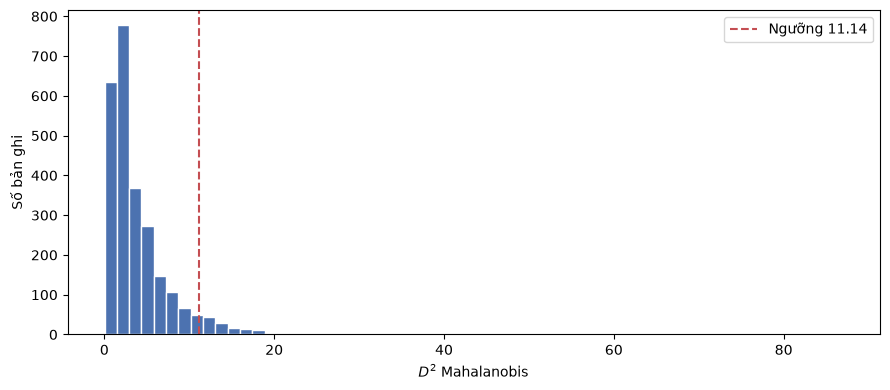

In [55]:
MAHA_COLS = ["log_area", "log_ppm2", "floors", "bedrooms"]
work["log_area"] = np.log(work["area_m2"])
X = work[MAHA_COLS].astype(float).dropna()
diff = X.to_numpy() - X.to_numpy().mean(axis=0)
inv_cov = np.linalg.inv(np.cov(X.to_numpy(), rowvar=False))
d2 = np.einsum("ij,jk,ik->i", diff, inv_cov, diff)

threshold = stats.chi2.ppf(0.975, df=len(MAHA_COLS))
maha_flag = pd.Series(False, index=work.index)
maha_flag[X.index] = d2 > threshold
work["mahalanobis_d2"] = pd.Series(d2, index=X.index)

print(f"Số bản ghi đủ 4 biến : {len(X)} / {len(work)}")
print(f"Ngưỡng χ²(0,975; 4)  : {threshold:.2f}")
print(f"Số ngoại lai Mahalanobis: {maha_flag.sum()}")

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(d2, bins=60, color="#4C72B0", edgecolor="white")
ax.axvline(threshold, color="#C44E52", linestyle="--", label=f"Ngưỡng {threshold:.2f}")
ax.set_xlabel("$D^2$ Mahalanobis")
ax.set_ylabel("Số bản ghi")
ax.legend()
plt.tight_layout()

### 5.5.3 So sánh hai phương pháp

In [56]:
overlap = pd.crosstab(iqr_flag.rename("IQR"), maha_flag.rename("Mahalanobis"), margins=True, margins_name="Tổng")
display(overlap)

show = ["district", "house_type", "area_m2", "floors", "bedrooms", "price_billion_vnd"]
work["ppm2_trieu"] = (np.exp(work["log_ppm2"])).round(1)
print("Ví dụ bản ghi CHỈ Mahalanobis đánh dấu:")
display(work.loc[maha_flag & ~iqr_flag, show + ["ppm2_trieu"]].head(8))
print("Ví dụ bản ghi IQR đánh dấu:")
display(work.loc[iqr_flag, show + ["ppm2_trieu"]].sort_values("ppm2_trieu").iloc[np.r_[0:4, -4:0]])

Mahalanobis,False,True,Tổng
IQR,,,
False,2715,104,2819
True,75,51,126
Tổng,2790,155,2945


Ví dụ bản ghi CHỈ Mahalanobis đánh dấu:


,district,house_type,area_m2,floors,bedrooms,price_billion_vnd,ppm2_trieu
13,Cầu Giấy,Nhà trong hẻm,144.0,4,9,21.00,145.8
55,Long Biên,Nhà trong hẻm,58.0,6,10,7.40,127.6
143,Hai Bà Trưng,Nhà trong hẻm,15.0,3,2,1.62,108.0
180,Gò Vấp,Nhà trong hẻm,80.0,3,10,8.80,110.0
258,Đống Đa,Nhà mặt tiền,55.0,5,9,10.00,181.8
296,Quận 3,Nhà trong hẻm,14.4,4,3,3.30,229.2
302,Cầu Giấy,Nhà trong hẻm,82.0,7,10,27.00,329.3
318,Thanh Trì,Nhà trong hẻm,145.0,4,4,6.00,41.4


Ví dụ bản ghi IQR đánh dấu:


,district,house_type,area_m2,floors,bedrooms,price_billion_vnd,ppm2_trieu
1285,Long Biên,Nhà trong hẻm,1000.0,<NA>,4,5.80,5.8
1221,Hai Bà Trưng,Nhà trong hẻm,320.0,1,2,2.10,6.6
2095,Hoàng Mai,Nhà trong hẻm,330.0,<NA>,6,2.60,7.9
2486,Hoàng Mai,Nhà trong hẻm,850.0,6,8,6.80,8.0
1182,Hoàn Kiếm,Nhà mặt tiền,64.0,3,4,48.00,750.0
2628,Đống Đa,Nhà mặt tiền,52.0,5,7,45.00,865.4
2405,Cầu Giấy,Nhà trong hẻm,44.0,4,4,49.80,1131.8
739,Thanh Xuân,Nhà trong hẻm,35.0,<NA>,5,41.31,1180.3


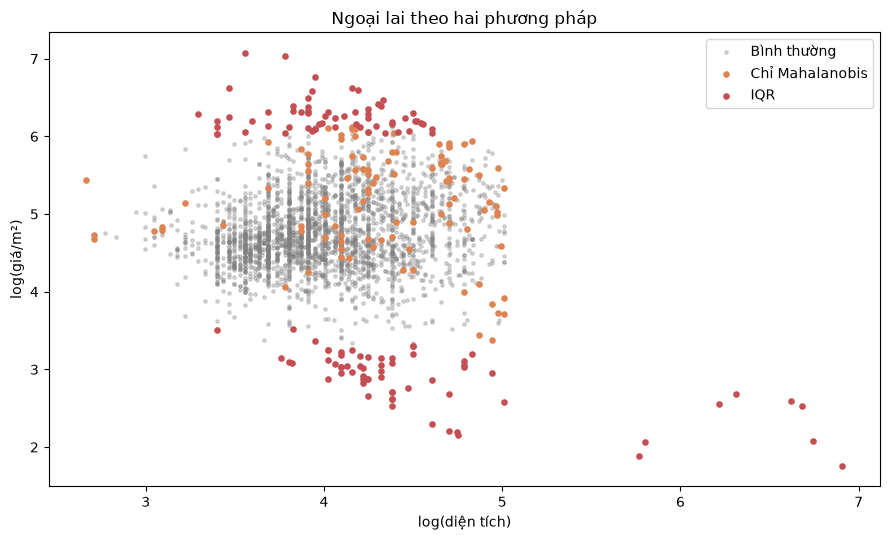

In [57]:
fig, ax = plt.subplots(figsize=(9, 5.5))
normal = ~iqr_flag & ~maha_flag
ax.scatter(work.loc[normal, "log_area"], work.loc[normal, "log_ppm2"], s=6, alpha=0.3, label="Bình thường", color="gray")
ax.scatter(work.loc[maha_flag & ~iqr_flag, "log_area"], work.loc[maha_flag & ~iqr_flag, "log_ppm2"], s=14,
           label="Chỉ Mahalanobis", color="#DD8452")
ax.scatter(work.loc[iqr_flag, "log_area"], work.loc[iqr_flag, "log_ppm2"], s=14, label="IQR", color="#C44E52")
ax.set_xlabel("log(diện tích)")
ax.set_ylabel("log(giá/m²)")
ax.set_title("Ngoại lai theo hai phương pháp")
ax.legend()
plt.tight_layout()

### 5.5.4 Lựa chọn phương pháp

**Kết quả so sánh:**
- **IQR** đánh dấu 126 bản ghi (4,3%) có giá/m² nằm ngoài khoảng 34–413 triệu/m² (Hà Nội) hoặc 28–470 triệu/m² (TP.HCM). Đây là các bản ghi có giá/m² bất thường so với mặt bằng thành phố: giá/m² quá thấp (thường do diện tích gõ thừa số 0, ví dụ 500–1.000 m² với giá vài tỷ) hoặc quá cao (thường do sai giá).
- **Mahalanobis** đánh dấu 155 bản ghi, chỉ 51 bản ghi trùng với IQR. Phần lớn bản ghi chỉ Mahalanobis đánh dấu là nhà lớn có 9–10 phòng ngủ, nhà 1 tầng giá cao, hoặc nhà rất nhỏ: các tổ hợp hiếm nhưng vẫn hợp lý (ví dụ nhà cho thuê phòng).

**Phản biện đối với Mahalanobis:** phương pháp giả định dữ liệu có phân phối chuẩn nhiều chiều. Số tầng và số phòng ngủ là biến rời rạc, phân phối lệch, nên giả định này không thỏa mãn và ngưỡng $\chi^2$ đánh dấu quá nhiều. Ngoài ra Mahalanobis không đánh giá được khoảng 13% bản ghi thiếu số tầng hoặc số phòng ngủ.

**Lựa chọn:** loại các bản ghi do **IQR** đánh dấu. Mahalanobis được dùng để kiểm tra chéo: các bản ghi bị cả hai phương pháp đánh dấu là ngoại lai rõ ràng nhất. Bản ghi chỉ Mahalanobis đánh dấu được giữ lại để mô hình không mất các căn hiếm nhưng hợp lệ.

**Lưu ý:** việc loại ngoại lai được thực hiện trước khi chia tập huấn luyện/kiểm thử, vì đây là bước loại bỏ bản ghi sai do nhập liệu chứ không phải bước học tham số. Tập kiểm thử vì vậy cũng không chứa các bản ghi sai này.

In [58]:
n = len(clean)
data = work.loc[~iqr_flag].drop(columns=["log_ppm2", "log_area", "mahalanobis_d2", "ppm2_trieu"]).reset_index(drop=True)
log.append(("Loại ngoại lai (IQR)", len(data)))
print(f"Trước: {n}  ->  Sau: {len(data)}  (loại {n - len(data)}, {(n - len(data)) / n:.1%})")
print(f"Skewness của giá sau khi loại ngoại lai: {data['price_billion_vnd'].skew():.3f}")

Trước: 2945  ->  Sau: 2819  (loại 126, 4.3%)
Skewness của giá sau khi loại ngoại lai: 2.122


## 5.6 Tạo đặc trưng và tập dữ liệu cho mô hình

| Đặc trưng | Loại | Ghi chú |
|---|---|---|
| `area_m2`, `width_m`, `length_m`, `road_width_m`, `floors`, `bedrooms` | Số | Giữ nguyên, giá trị thiếu được điền trong pipeline ở Bước 2 |
| `width_length_ratio` | Số | **Mới:** tỷ lệ ngang/dài. Nhà mặt tiền rộng, ít sâu thường có giá trị thương mại cao hơn |
| `dist_center_km` | Số | **Mới:** khoảng cách tới trung tâm (mục 5.4) |
| `lat`, `lon` | Số | **Mới:** tọa độ tâm quận/huyện |
| `n_schools`, `n_health`, `n_markets`, `n_parks`, `n_transit` | Số | **Mới:** số tiện ích xung quanh trong bán kính 2 km (mục 5.4.3) |
| `has_dining_room`, `has_kitchen`, `has_terrace`, `has_parking` | Nhị phân | |
| `city`, `district`, `house_type` | Phân loại | Mã hóa one-hot trong pipeline ở Bước 2 |
| `price_billion_vnd` | **Mục tiêu** | Biến đổi Box-Cox trong pipeline ở Bước 2 |
| `price_segment` | Phụ trợ | Chỉ dùng để chia phân tầng và đánh giá theo phân khúc, không đưa vào mô hình |

**Không đưa vào mô hình:**
- **Giá/m²:** được tính từ giá, nên đưa vào sẽ làm lộ biến mục tiêu (*target leakage*).
- `url`, `title`, `posted_date`, `order` và các cờ đánh dấu của bước làm sạch: không mô tả đặc điểm căn nhà.

**Không có trong dữ liệu:** tình trạng pháp lý (sổ đỏ, sổ hồng, giấy tay). Bộ dữ liệu gốc không thu thập thuộc tính này. Thuộc tính này không được giả lập, vì giá trị giả lập sẽ khiến mô hình học một quan hệ do người làm tự đặt ra. Đây là hạn chế của đề tài; ứng dụng ghi chú rằng giá dự báo áp dụng cho nhà có giấy tờ pháp lý đầy đủ.

In [59]:
data["width_length_ratio"] = (data["width_m"] / data["length_m"]).round(3)

FEATURES_NUM = ["area_m2", "width_m", "length_m", "road_width_m", "floors", "bedrooms",
                "width_length_ratio", "dist_center_km", "lat", "lon", *AMENITY_COLS]
FEATURES_BOOL = BOOL_COLS
FEATURES_CAT = ["city", "district", "house_type"]
TARGET = "price_billion_vnd"

model_df = data[FEATURES_NUM + FEATURES_BOOL + FEATURES_CAT + [TARGET, "price_segment"]].copy()
print("Kích thước tập dữ liệu cho mô hình:", model_df.shape)
print("Số đặc trưng:", len(FEATURES_NUM + FEATURES_BOOL + FEATURES_CAT))
model_df.head()

Kích thước tập dữ liệu cho mô hình: (2819, 24)
Số đặc trưng: 22


,area_m2,width_m,length_m,road_width_m,floors,bedrooms,width_length_ratio,dist_center_km,lat,lon,n_schools,n_health,n_markets,n_parks,n_transit,has_dining_room,has_kitchen,has_terrace,has_parking,city,district,house_type,price_billion_vnd,price_segment
0,108.0,6.8,NaN,3.0,5,5,NaN,6.339686,21.02985,105.79133,113,20,134,29,176,True,True,True,True,Hà Nội,Cầu Giấy,Nhà trong hẻm,7.495,5–15 tỷ
1,NaN,6.3,NaN,15.0,1,3,NaN,0.288403,21.03078,105.85406,78,34,204,25,155,False,True,False,False,Hà Nội,Hoàn Kiếm,Nhà mặt tiền,27.000,Trên 15 tỷ
2,25.0,3.5,8.0,3.0,4,3,0.438,10.651489,21.07301,105.76140,19,7,23,1,26,True,True,False,False,Hà Nội,Bắc Từ Liêm,Nhà trong hẻm,1.650,Dưới 5 tỷ
3,24.0,3.0,8.0,8.0,2,2,0.375,7.462907,10.83535,106.67403,35,9,50,25,119,False,False,False,False,Hồ Chí Minh,Gò Vấp,Nhà trong hẻm,2.900,Dưới 5 tỷ
4,70.0,7.0,NaN,5.0,4,6,NaN,4.867167,21.03673,105.89850,37,6,40,22,79,True,True,True,True,Hà Nội,Long Biên,Nhà mặt tiền,7.000,5–15 tỷ


In [60]:
model_df.isna().sum()[lambda s: s > 0].to_frame("Số ô thiếu (điền ở Bước 2)")

,Số ô thiếu (điền ở Bước 2)
area_m2,6
width_m,823
length_m,1626
road_width_m,153
floors,214
bedrooms,175
width_length_ratio,1667
has_dining_room,25
has_kitchen,40
has_terrace,33


### 5.7 Lưu kết quả tiền xử lý
Tập dữ liệu cho mô hình được ghi vào `data/processed/features.csv`, dùng cho Bước 2 và ứng dụng Streamlit.

In [61]:
FEATURES_PATH = ROOT / "data" / "processed" / "features.csv"
model_df.to_csv(FEATURES_PATH, index=False, encoding="utf-8")
pd.DataFrame(log, columns=["buoc", "so_dong"]).to_csv(LOG_PATH, index=False, encoding="utf-8")

display(pd.DataFrame(log, columns=["Bước", "Số bản ghi"]))
print("Đã lưu", len(model_df), "dòng vào", FEATURES_PATH.relative_to(ROOT))

,Bước,Số bản ghi
0,Dữ liệu thô,3510
1,Bỏ dòng tiêu đề lặp,3506
2,Bỏ dòng rỗng,3500
3,Sửa 11 dòng lệch cột,3500
4,Bỏ dòng trùng y hệt,3189
5,Bỏ tin trùng url,3185
6,Bỏ tin đăng lại,2975
7,Bỏ dòng không có giá,2945
8,Loại ngoại lai (IQR),2819


Đã lưu 2819 dòng vào data/processed/features.csv


# 6. Mô hình hóa (Bước 2 của đề tài)

**Mục đích:** huấn luyện và tinh chỉnh các mô hình hồi quy theo yêu cầu của đề tài: Ridge, Lasso, ElasticNet, Gradient Boosting Regressor, LightGBM và Stacking Ensemble; trích chọn thuộc tính; dò tham số bằng grid search cross-validation; lưu mô hình học được.

**Nguyên tắc chống rò rỉ dữ liệu:** tập kiểm thử được tách ra ngay từ đầu và **không được dùng** trong toàn bộ mục 6. Mọi bước học từ dữ liệu (điền giá trị thiếu, chuẩn hóa, mã hóa, ước lượng λ Box-Cox, chọn thuộc tính, chọn tham số, chọn mô hình) chỉ dùng tập huấn luyện, thông qua pipeline và cross-validation. Tập kiểm thử chỉ được dùng một lần ở Bước 3 để đánh giá.

In [62]:
import os
import time
import warnings

import joblib
import lightgbm
import sklearn
from lightgbm import LGBMRegressor
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, StackingRegressor
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNet, Lasso, LinearRegression, Ridge, RidgeCV
from sklearn.model_selection import GridSearchCV, KFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, PowerTransformer, StandardScaler

warnings.filterwarnings("ignore", category=UserWarning, module="lightgbm")
warnings.filterwarnings("ignore", message="X does not have valid feature names")
# Áp dụng cùng bộ lọc cho các tiến trình con khi chạy song song (n_jobs=-1)
os.environ["PYTHONWARNINGS"] = "ignore:X does not have valid feature names:UserWarning"
RANDOM_STATE = 4595
MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

print("scikit-learn", sklearn.__version__)
print("lightgbm    ", lightgbm.__version__)
print("joblib      ", joblib.__version__)

scikit-learn 1.9.1
lightgbm     4.7.0
joblib       1.6.0


## 6.1 Chia tập huấn luyện và tập kiểm thử

- Tỷ lệ 80% huấn luyện, 20% kiểm thử.
- **Phân tầng theo phân khúc giá** (`price_segment`): tỷ lệ ba phân khúc giá trong hai tập giống nhau, để phân khúc giá cao (ít mẫu, mục 5.1.3) có mặt đủ trong tập kiểm thử.
- `random_state` cố định để kết quả tái lập được.

In [63]:
X = model_df[FEATURES_NUM + FEATURES_BOOL + FEATURES_CAT].copy()
X[FEATURES_BOOL] = X[FEATURES_BOOL].astype("float")   # True/False/NA -> 1/0/NaN
y = model_df[TARGET].astype(float)
segment = model_df["price_segment"]

X_train, X_test, y_train, y_test, seg_train, seg_test = train_test_split(
    X, y, segment, test_size=0.2, stratify=segment, random_state=RANDOM_STATE)

print(f"Tập huấn luyện: {len(X_train)} bản ghi | Tập kiểm thử: {len(X_test)} bản ghi")
pd.DataFrame({
    "Toàn bộ (%)": segment.value_counts(normalize=True).sort_index() * 100,
    "Huấn luyện (%)": seg_train.value_counts(normalize=True).sort_index() * 100,
    "Kiểm thử (%)": seg_test.value_counts(normalize=True).sort_index() * 100,
}).round(1)

Tập huấn luyện: 2255 bản ghi | Tập kiểm thử: 564 bản ghi


,Toàn bộ (%),Huấn luyện (%),Kiểm thử (%)
price_segment,,,
Dưới 5 tỷ,38.8,38.8,38.8
5–15 tỷ,48.0,48.0,48.0
Trên 15 tỷ,13.2,13.2,13.1


## 6.2 Pipeline tiền xử lý

Mỗi mô hình được đặt trong cùng một pipeline gồm hai tầng:

1. **Tiền xử lý đặc trưng** (`ColumnTransformer`):

| Nhóm đặc trưng | Điền giá trị thiếu | Biến đổi |
|---|---|---|
| Số | Trung vị | Chuẩn hóa (`StandardScaler`) |
| Nhị phân | Giá trị phổ biến nhất | Giữ nguyên 0/1 |
| Phân loại | Giá trị phổ biến nhất | Mã hóa one-hot; quận/huyện có dưới 10 bản ghi được gộp thành nhóm `infrequent` |

2. **Biến đổi biến mục tiêu** (`TransformedTargetRegressor`): mô hình học trên giá đã biến đổi (Box-Cox hoặc Log1p); dự đoán được tự động đảo ngược về đơn vị tỷ VNĐ. Với Box-Cox, λ được ước lượng lại trên dữ liệu huấn luyện của mỗi lần khớp mô hình (mỗi fold cross-validation).

Gộp quận/huyện ít mẫu xử lý vấn đề mất cân bằng ở mục 5.1.2: mô hình không học riêng một hệ số cho quận chỉ có 1–9 bản ghi.

In [64]:
def make_preprocessor(num=FEATURES_NUM, boolean=FEATURES_BOOL, cat=FEATURES_CAT):
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), num),
        ("bool", SimpleImputer(strategy="most_frequent"), boolean),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                   min_frequency=10, sparse_output=False))]), cat),
    ])


TARGET_TRANSFORM = "box-cox"   # lựa chọn sơ bộ từ mục 5.3, được kiểm chứng ngay bên dưới


def make_model(estimator, target=None, **feature_groups):
    """Pipeline đầy đủ: tiền xử lý -> mô hình, bọc trong biến đổi biến mục tiêu."""
    target = target or TARGET_TRANSFORM
    pipe = Pipeline([("prep", make_preprocessor(**feature_groups)), ("model", estimator)])
    if target == "box-cox":
        transformer = PowerTransformer(method="box-cox", standardize=False)
    else:  # log1p
        transformer = FunctionTransformer(np.log1p, inverse_func=np.expm1, check_inverse=False)
    return TransformedTargetRegressor(regressor=pipe, transformer=transformer)


CV = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"}


CV_FOLDS = {}   # điểm của từng fold, dùng để đánh giá độ ổn định ở mục 7 và trong ứng dụng


def cv_summary(model, X_=None, name=""):
    """Cross-validation 5 fold trên tập huấn luyện; chỉ số tính trên đơn vị tỷ VNĐ."""
    X_ = X_train if X_ is None else X_
    r = cross_validate(model, X_, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    CV_FOLDS[name] = {"RMSE": -r["test_RMSE"], "MAE": -r["test_MAE"], "R2": r["test_R2"]}
    return {"Mô hình": name, "CV RMSE": -r["test_RMSE"].mean(), "CV MAE": -r["test_MAE"].mean(),
            "CV R²": r["test_R2"].mean(), "Độ lệch chuẩn RMSE": r["test_RMSE"].std()}


prep = make_preprocessor().fit(X_train)
n_out = len(prep.get_feature_names_out())
print("Số cột sau tiền xử lý:", n_out)
print("Ví dụ tên cột:", list(prep.get_feature_names_out()[[0, 1, 10, 14, -2, -1]]))

Số cột sau tiền xử lý: 51
Ví dụ tên cột: ['num__area_m2', 'num__width_m', 'num__n_schools', 'num__n_transit', 'cat__house_type_Nhà mặt tiền', 'cat__house_type_Nhà trong hẻm']


### Kiểm tra lựa chọn Box-Cox so với Log1p
Mục 5.3 chọn sơ bộ Box-Cox dựa trên hình dạng phân phối. Tiêu chí quyết định cuối cùng là **sai số dự đoán trên đơn vị tỷ VNĐ**: huấn luyện Ridge và LightGBM (tham số mặc định) với từng cách biến đổi, so sánh bằng cross-validation 5 fold.

In [65]:
rows = []
for target in ["box-cox", "log1p"]:
    rows.append(cv_summary(make_model(Ridge(), target), name=f"Ridge, {target}"))
    rows.append(cv_summary(make_model(LGBMRegressor(random_state=RANDOM_STATE, verbose=-1), target),
                           name=f"LightGBM, {target}"))
rows.append(cv_summary(Pipeline([("prep", make_preprocessor()), ("model", Ridge())]), name="Ridge, không biến đổi"))
pd.DataFrame(rows).round(4)

,Mô hình,CV RMSE,CV MAE,CV R²,Độ lệch chuẩn RMSE
0,"Ridge, box-cox",5.1617,2.5380,0.3127,1.4662
1,"LightGBM, box-cox",3.4097,1.9496,0.7271,0.3562
2,"Ridge, log1p",3.6544,2.1711,0.6839,0.3161
3,"LightGBM, log1p",3.3813,1.9508,0.7322,0.3535
4,"Ridge, không biến đổi",3.6058,2.3822,0.6966,0.1408


In [66]:
tt = pd.DataFrame(rows)
tt["Biến đổi"] = tt["Mô hình"].str.split(", ").str[1]
mean_rmse = tt[tt["Biến đổi"].isin(["box-cox", "log1p"])].groupby("Biến đổi")["CV RMSE"].mean()
TARGET_TRANSFORM = mean_rmse.idxmin()
print("CV RMSE trung bình của Ridge và LightGBM theo cách biến đổi:")
print(mean_rmse.round(4).to_string())
print("=> Chọn biến đổi biến mục tiêu:", TARGET_TRANSFORM)

CV RMSE trung bình của Ridge và LightGBM theo cách biến đổi:
Biến đổi
box-cox    4.2857
log1p      3.5178
=> Chọn biến đổi biến mục tiêu: log1p


**Nhận xét và phản biện lựa chọn ở mục 5.3:**
- Box-Cox cho phân phối gần chuẩn nhất (mục 5.3), nhưng khi dùng với Ridge lại cho **sai số lớn nhất và không ổn định** giữa các fold (độ lệch chuẩn RMSE lớn).
- **Nguyên nhân:** λ ước lượng âm (≈ −0,17), nên giá trị sau biến đổi bị chặn trên bởi $-1/\lambda \approx 6$. Khi mô hình tuyến tính dự đoán giá trị gần hoặc vượt ngưỡng này (ngoại suy với căn có diện tích hoặc đường rộng lớn), phép biến đổi ngược $y = (1 + \lambda y')^{1/\lambda}$ cho kết quả rất lớn hoặc không xác định. Log1p không có giới hạn này: phép biến đổi ngược $e^{y'} - 1$ luôn ổn định.
- Với LightGBM, hai cách biến đổi cho sai số gần nhau vì mô hình cây không ngoại suy ra ngoài miền giá trị đã học.
- So với không biến đổi, Ridge với Log1p có RMSE cao hơn một chút (3,65 so với 3,61 tỷ) nhưng MAE thấp hơn rõ (2,17 so với 2,38 tỷ). RMSE bị chi phối bởi sai số của các căn giá rất cao, trong khi Log1p giúp mô hình dự đoán tốt hơn về sai số tương đối ở đa số căn. Biến đổi vẫn cần thiết để phần dư của mô hình tuyến tính gần chuẩn hơn và để khoảng dự báo ở Bước 4 hợp lý.

**Kết luận:** chọn **Log1p** làm biến đổi biến mục tiêu cho tất cả mô hình. Đây là ví dụ cho thấy tiêu chí "phân phối gần chuẩn nhất" chưa đủ; lựa chọn cuối cùng cần dựa trên sai số dự đoán trên đơn vị gốc.

## 6.3 Trích chọn thuộc tính

Hai phương pháp bổ sung cho nhau:
1. **Lasso (`SelectFromModel`):** hồi quy với chuẩn L1 đưa hệ số của thuộc tính ít đóng góp về 0. Thuộc tính có hệ số khác 0 được giữ lại. Phương pháp này đánh giá ở mức từng cột sau mã hóa (từng quận/huyện).
2. **Độ quan trọng hoán vị (permutation importance):** xáo trộn ngẫu nhiên từng thuộc tính gốc và đo mức tăng sai số của mô hình LightGBM. Thuộc tính quan trọng khi xáo trộn làm sai số tăng nhiều. Đánh giá trên một phần tập huấn luyện được tách riêng (tập kiểm định), không dùng tập kiểm thử.

### 6.3.1 Lasso

Số cột được giữ: 25 / 51
Các cột bị loại (hệ số = 0): ['num__lat', 'num__lon', 'num__n_health', 'num__n_markets', 'bool__has_kitchen', 'bool__has_terrace', 'cat__city_Hà Nội', 'cat__city_Hồ Chí Minh', 'cat__district_Bình Thạnh', 'cat__district_Bắc Từ Liêm', 'cat__district_Cầu Giấy', 'cat__district_Gò Vấp', 'cat__district_Nam Từ Liêm', 'cat__district_Phú Nhuận', 'cat__district_Quận 1', 'cat__district_Quận 10', 'cat__district_Quận 2', 'cat__district_Quận 3', 'cat__district_Quận 7', 'cat__district_Quận 8', 'cat__district_Quận 9', 'cat__district_Thanh Xuân', 'cat__district_Thủ Đức', 'cat__district_Tân Phú', 'cat__district_infrequent_sklearn', 'cat__house_type_Nhà trong hẻm']


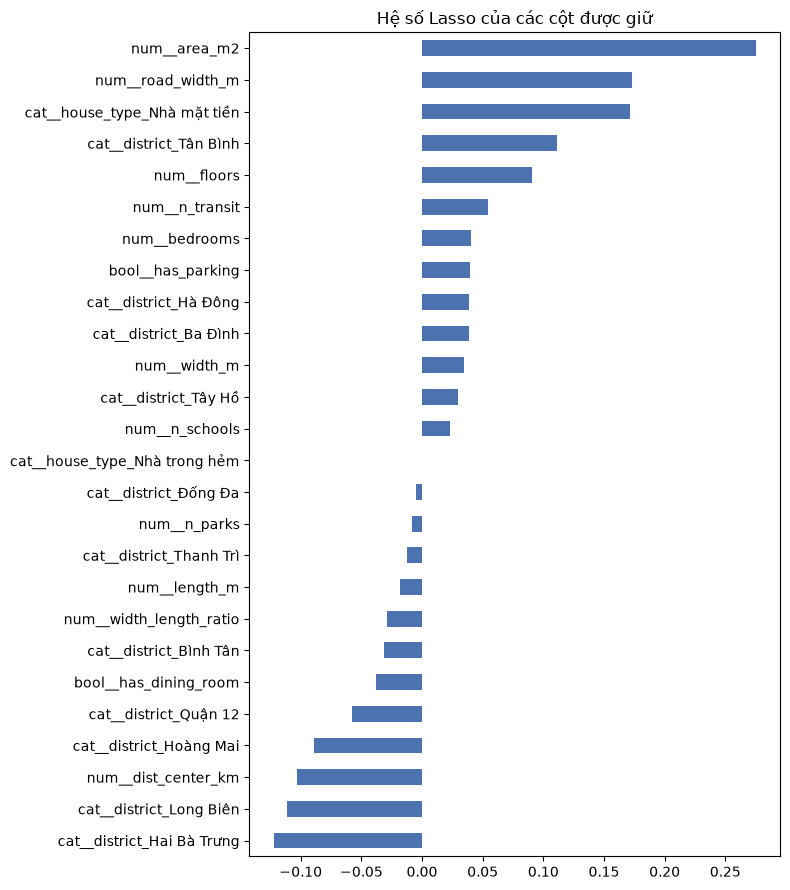

In [67]:
prep_train = make_preprocessor().fit(X_train)
Xt = prep_train.transform(X_train)
yt = np.log1p(y_train.to_numpy()) if TARGET_TRANSFORM == "log1p" else     PowerTransformer(method="box-cox", standardize=False).fit_transform(y_train.to_frame()).ravel()

selector = SelectFromModel(Lasso(alpha=0.002, max_iter=20000)).fit(Xt, yt)
names = prep_train.get_feature_names_out()
coef = pd.Series(selector.estimator_.coef_, index=names)

print(f"Số cột được giữ: {selector.get_support().sum()} / {len(names)}")
print("Các cột bị loại (hệ số = 0):", list(names[~selector.get_support()]))
coef[coef != 0].sort_values().plot.barh(figsize=(8, 9), color="#4C72B0", title="Hệ số Lasso của các cột được giữ")
plt.tight_layout()

### 6.3.2 Độ quan trọng hoán vị

,Mức tăng RMSE (tỷ),Độ lệch chuẩn
area_m2,1.9396,0.1314
road_width_m,1.1938,0.1045
house_type,0.4177,0.0634
dist_center_km,0.3815,0.0793
floors,0.2730,0.0684
n_markets,0.1989,0.0661
width_m,0.0929,0.0386
lat,0.0697,0.0273
n_schools,0.0382,0.0277
n_transit,0.0365,0.0213


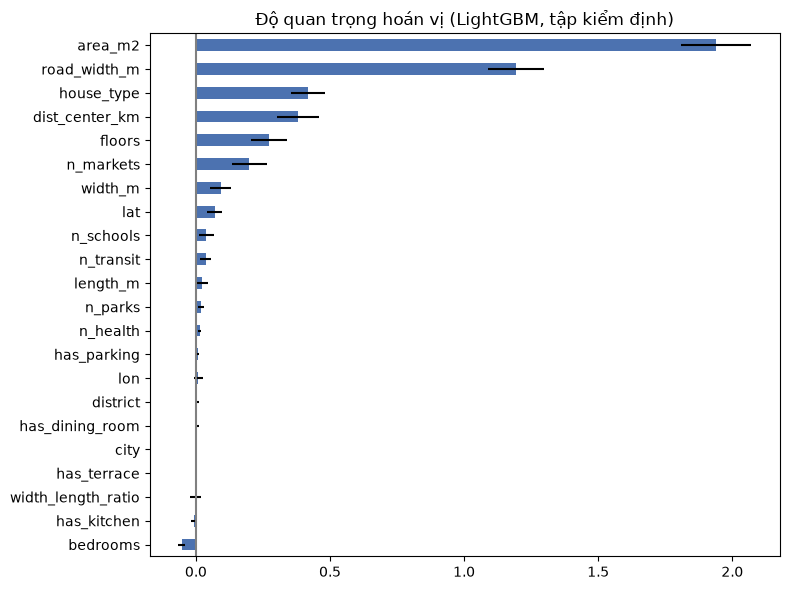

In [68]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=RANDOM_STATE)
lgbm_base = make_model(LGBMRegressor(random_state=RANDOM_STATE, verbose=-1)).fit(X_fit, y_fit)

perm = permutation_importance(lgbm_base, X_val, y_val, scoring="neg_root_mean_squared_error",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"Mức tăng RMSE (tỷ)": perm.importances_mean, "Độ lệch chuẩn": perm.importances_std},
                   index=X_train.columns).sort_values("Mức tăng RMSE (tỷ)")

ax = imp["Mức tăng RMSE (tỷ)"].plot.barh(xerr=imp["Độ lệch chuẩn"], figsize=(8, 6), color="#4C72B0")
ax.axvline(0, color="gray")
ax.set_title("Độ quan trọng hoán vị (LightGBM, tập kiểm định)")
plt.tight_layout()
imp.sort_values("Mức tăng RMSE (tỷ)", ascending=False).round(4)

### 6.3.3 So sánh tập thuộc tính đầy đủ và tập đã chọn
Thuộc tính bị loại là thuộc tính có độ quan trọng hoán vị không lớn hơn độ lệch chuẩn của chính nó (không phân biệt được với nhiễu).

In [69]:
weak = imp.index[imp["Mức tăng RMSE (tỷ)"] <= imp["Độ lệch chuẩn"]].tolist()
SEL_NUM = [c for c in FEATURES_NUM if c not in weak]
SEL_BOOL = [c for c in FEATURES_BOOL if c not in weak]
SEL_CAT = [c for c in FEATURES_CAT if c not in weak]
print("Thuộc tính bị loại:", weak or "không có")

rows = []
for label, groups in [("Đầy đủ", {}), ("Đã chọn", {"num": SEL_NUM, "boolean": SEL_BOOL, "cat": SEL_CAT})]:
    rows.append(cv_summary(make_model(Ridge(), **groups), name=f"Ridge, {label}"))
    rows.append(cv_summary(make_model(LGBMRegressor(random_state=RANDOM_STATE, verbose=-1), **groups),
                           name=f"LightGBM, {label}"))
feat_cmp = pd.DataFrame(rows).round(4)
feat_cmp

Thuộc tính bị loại: ['bedrooms', 'has_kitchen', 'width_length_ratio', 'has_terrace', 'city', 'has_dining_room', 'lon', 'length_m']


,Mô hình,CV RMSE,CV MAE,CV R²,Độ lệch chuẩn RMSE
0,"Ridge, Đầy đủ",3.6544,2.1711,0.6839,0.3161
1,"LightGBM, Đầy đủ",3.3813,1.9508,0.7322,0.3535
2,"Ridge, Đã chọn",3.6787,2.1867,0.6799,0.3089
3,"LightGBM, Đã chọn",3.3457,1.9416,0.7375,0.3381


In [70]:
full_rmse = feat_cmp.loc[feat_cmp["Mô hình"].str.contains("Đầy đủ"), "CV RMSE"].mean()
sel_rmse = feat_cmp.loc[feat_cmp["Mô hình"].str.contains("Đã chọn"), "CV RMSE"].mean()
USE_SELECTED = bool(weak) and sel_rmse <= full_rmse * 1.01   # chấp nhận tăng tối đa 1% sai số để có mô hình gọn hơn

if USE_SELECTED:
    FEAT_GROUPS = {"num": SEL_NUM, "boolean": SEL_BOOL, "cat": SEL_CAT}
    print(f"Dùng tập đã chọn ({len(SEL_NUM + SEL_BOOL + SEL_CAT)} thuộc tính).")
else:
    FEAT_GROUPS = {}
    print("Dùng tập thuộc tính đầy đủ.")
print(f"RMSE trung bình: đầy đủ = {full_rmse:.4f}, đã chọn = {sel_rmse:.4f}")

Dùng tập đã chọn (14 thuộc tính).
RMSE trung bình: đầy đủ = 3.5179, đã chọn = 3.5122


### 6.3.4 Nhận xét
- **Thuộc tính quan trọng nhất:** diện tích, độ rộng đường trước nhà, loại nhà và khoảng cách tới trung tâm, tiếp theo là số tầng và số chợ/siêu thị xung quanh (`n_markets`). Hai đặc trưng tạo ở mục 5.4 đều nằm trong nhóm quan trọng, xác nhận giá trị của việc xử lý dữ liệu vị trí.
- **Thuộc tính bị loại:** `city`, `lon`, `length_m`, `width_length_ratio`, `bedrooms` và ba tiện ích trong nhà (`has_kitchen`, `has_terrace`, `has_dining_room`). Thông tin của chúng đã có trong thuộc tính khác (thành phố nằm trong tọa độ; số phòng ngủ tương quan với diện tích và số tầng; chiều dài suy ra từ diện tích và chiều ngang) hoặc quá nhiễu (cột tiện ích trong nhà thường trống khi tin rao không đề cập).
- **Kết quả so sánh:** bỏ các thuộc tính yếu giúp LightGBM giảm sai số (CV RMSE 3,381 → 3,346 tỷ), trong khi Ridge tăng nhẹ (3,654 → 3,679 tỷ). Sai số trung bình của hai mô hình giảm nhẹ.

**Quyết định:** dùng **tập thuộc tính đã chọn (14 thuộc tính)** cho tất cả mô hình ở các mục sau: mô hình gọn hơn, ít thuộc tính nhiễu hơn, và sai số trung bình không tăng.

### 6.3.5 Đóng góp của tiện ích xung quanh
So sánh mô hình có và không có 5 thuộc tính tiện ích xung quanh (mục 5.4.3), bằng cross-validation 5 fold trên tập huấn luyện.

In [71]:
NO_AMEN = [c for c in FEATURES_NUM if c not in AMENITY_COLS]
rows = []
for label, groups in [("Không có tiện ích", {"num": NO_AMEN}), ("Có tiện ích", {})]:
    rows.append(cv_summary(make_model(Ridge(), **groups), name=f"Ridge, {label}"))
    rows.append(cv_summary(make_model(LGBMRegressor(random_state=RANDOM_STATE, verbose=-1), **groups),
                           name=f"LightGBM, {label}"))
amen_cmp = pd.DataFrame(rows)
amen_cmp.round(4)

,Mô hình,CV RMSE,CV MAE,CV R²,Độ lệch chuẩn RMSE
0,"Ridge, Không có tiện ích",3.6575,2.1724,0.6832,0.3284
1,"LightGBM, Không có tiện ích",3.3778,1.9562,0.7323,0.3340
2,"Ridge, Có tiện ích",3.6544,2.1711,0.6839,0.3161
3,"LightGBM, Có tiện ích",3.3813,1.9508,0.7322,0.3535


**Nhận xét:**
- Thêm 5 thuộc tính tiện ích xung quanh **gần như không thay đổi sai số trung bình** (Ridge: 3,658 → 3,654 tỷ; LightGBM: 3,378 → 3,381 tỷ), mức chênh nhỏ hơn rất nhiều so với độ lệch chuẩn giữa các fold.
- **Nguyên nhân:** số tiện ích được tính ở cấp quận và tương quan chặt với khoảng cách tới trung tâm (mục 5.4.3); mô hình đã học được ảnh hưởng của vị trí từ khoảng cách và tọa độ, nên tiện ích chủ yếu mang thông tin trùng lặp.
- Dù vậy, `n_markets` vẫn được độ quan trọng hoán vị (mục 6.3.2) và SHAP (mục 7.4) xếp ngang khoảng cách tới trung tâm: khi có cả hai, mô hình chia ảnh hưởng của vị trí cho cả hai thuộc tính.

**Quyết định:** giữ các thuộc tính tiện ích xung quanh, vì chúng đáp ứng yêu cầu của đề tài, có ý nghĩa diễn giải rõ ràng (khu vực nhiều chợ, trường học có giá cao hơn) và không làm mô hình kém đi. **Hạn chế:** để tiện ích có giá trị dự báo riêng cần tọa độ của từng căn nhà, khi đó số tiện ích sẽ khác nhau giữa các căn trong cùng quận.

## 6.4 Dò tham số bằng grid search cross-validation

Mỗi mô hình được dò tham số bằng `GridSearchCV` với cross-validation 5 fold trên tập huấn luyện. Tiêu chí chọn tham số là **RMSE** trên đơn vị tỷ VNĐ (giá đã được đảo ngược biến đổi). Linear Regression không có tham số, được dùng làm mô hình cơ sở.

| Mô hình | Tham số dò | Ý nghĩa |
|---|---|---|
| Ridge | `alpha` | Mức phạt L2 |
| Lasso | `alpha` | Mức phạt L1 |
| ElasticNet | `alpha`, `l1_ratio` | Mức phạt và tỷ lệ L1/L2 |
| Gradient Boosting | `n_estimators`, `learning_rate`, `max_depth`, `subsample` | Số cây, tốc độ học, độ sâu cây, tỷ lệ mẫu mỗi cây |
| LightGBM | `n_estimators`, `learning_rate`, `num_leaves`, `min_child_samples` | Số cây, tốc độ học, số lá, số mẫu tối thiểu mỗi lá |

In [72]:
P = "regressor__model__"   # tiền tố tên tham số trong pipeline
SEARCH = {
    "Ridge": (Ridge(), {P + "alpha": [0.1, 1, 3, 10, 30, 100, 300, 1000]}),
    "Lasso": (Lasso(max_iter=20000), {P + "alpha": [1e-5, 3e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2]}),
    "ElasticNet": (ElasticNet(max_iter=20000), {P + "alpha": [1e-4, 1e-3, 1e-2, 3e-2],
                                                P + "l1_ratio": [0.2, 0.5, 0.8]}),
    "Gradient Boosting": (GradientBoostingRegressor(random_state=RANDOM_STATE),
                          {P + "n_estimators": [200, 400], P + "learning_rate": [0.05, 0.1],
                           P + "max_depth": [3, 4], P + "subsample": [0.8, 1.0]}),
    "LightGBM": (LGBMRegressor(random_state=RANDOM_STATE, verbose=-1),
                 {P + "n_estimators": [300, 600], P + "learning_rate": [0.03, 0.06],
                  P + "num_leaves": [15, 31], P + "min_child_samples": [10, 20]}),
}

fitted, search_rows, search_cv = {}, [], {}
for name, (est, grid) in SEARCH.items():
    t0 = time.time()
    gs = GridSearchCV(make_model(est, **FEAT_GROUPS), grid, cv=CV,
                      scoring="neg_root_mean_squared_error", n_jobs=-1)
    gs.fit(X_train, y_train)
    fitted[name] = gs.best_estimator_
    search_cv[name] = pd.DataFrame(gs.cv_results_)
    search_rows.append({"Mô hình": name, "Số tổ hợp": len(gs.cv_results_["params"]),
                        "CV RMSE tốt nhất": -gs.best_score_,
                        "Tham số tốt nhất": {k.replace(P, ""): v for k, v in gs.best_params_.items()},
                        "Thời gian (giây)": round(time.time() - t0, 1)})
    print(f"{name:18} xong: CV RMSE = {-gs.best_score_:.4f}")

pd.DataFrame(search_rows).round(4)

Ridge              xong: CV RMSE = 3.6515


Lasso              xong: CV RMSE = 3.6693


ElasticNet         xong: CV RMSE = 3.6668


Gradient Boosting  xong: CV RMSE = 3.3332


LightGBM           xong: CV RMSE = 3.3078


,Mô hình,Số tổ hợp,CV RMSE tốt nhất,Tham số tốt nhất,Thời gian (giây)
0,Ridge,8,3.6515,{'alpha': 30},0.2
1,Lasso,8,3.6693,{'alpha': 0.001},0.5
2,ElasticNet,12,3.6668,"{'alpha': 0.001, 'l1_ratio': 0.5}",0.6
3,Gradient Boosting,16,3.3332,"{'learning_rate': 0.05, 'max_depth': 3, 'n_est...",8.4
4,LightGBM,16,3.3078,"{'learning_rate': 0.03, 'min_child_samples': 2...",70.5


### Ví dụ: ảnh hưởng của tham số `alpha` tới sai số của Ridge
Kết quả cross-validation của từng giá trị tham số cho thấy lý do chọn tham số tốt nhất.

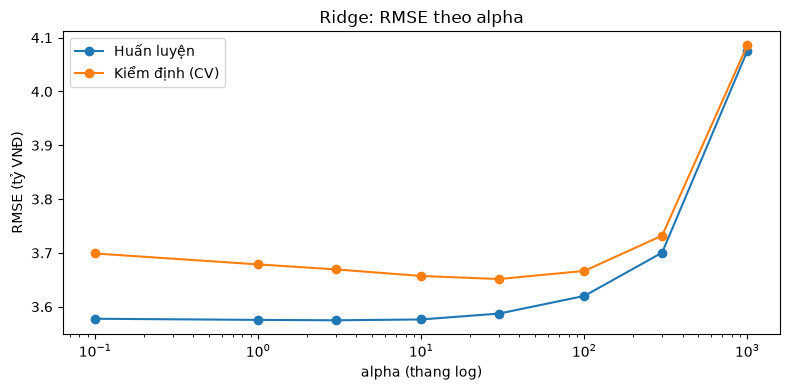

In [73]:
gs_ridge = GridSearchCV(make_model(Ridge(), **FEAT_GROUPS), SEARCH["Ridge"][1], cv=CV,
                        scoring="neg_root_mean_squared_error", n_jobs=-1, return_train_score=True).fit(X_train, y_train)
res = pd.DataFrame(gs_ridge.cv_results_)
alphas = res["param_" + P + "alpha"].astype(float)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(alphas, -res["mean_train_score"], "o-", label="Huấn luyện")
ax.plot(alphas, -res["mean_test_score"], "o-", label="Kiểm định (CV)")
ax.set_xscale("log")
ax.set_xlabel("alpha (thang log)")
ax.set_ylabel("RMSE (tỷ VNĐ)")
ax.set_title("Ridge: RMSE theo alpha")
ax.legend()
plt.tight_layout()

**Nhận xét:** khi `alpha` quá nhỏ, mô hình gần với Linear Regression và sai số kiểm định cao hơn; khi `alpha` quá lớn, mô hình bị phạt quá mức (*underfitting*), sai số trên cả hai tập cùng tăng. Giá trị tốt nhất nằm ở giữa lưới tìm kiếm, cho thấy lưới tham số đủ rộng. Khoảng cách nhỏ giữa sai số huấn luyện và kiểm định cho thấy mô hình tuyến tính không bị quá khớp.

## 6.5 Stacking Ensemble

Stacking kết hợp dự đoán của nhiều mô hình cơ sở bằng một mô hình meta:
- **Mô hình cơ sở:** Ridge, Lasso, ElasticNet, Gradient Boosting, LightGBM với tham số tốt nhất từ mục 6.4.
- **Mô hình meta:** `RidgeCV`, học trọng số kết hợp từ dự đoán ngoài fold (out-of-fold) của các mô hình cơ sở, nhờ đó không học trên dự đoán của chính dữ liệu đã huấn luyện.

Tầng tiền xử lý và biến đổi biến mục tiêu dùng chung cho cả khối stacking.

In [74]:
base = [(name.replace(" ", "_"), fitted[name].regressor.named_steps["model"]) for name in SEARCH]
stacking = make_model(StackingRegressor(estimators=base, final_estimator=RidgeCV(alphas=np.logspace(-3, 2, 20)),
                                        cv=5, n_jobs=-1), **FEAT_GROUPS)
t0 = time.time()
stack_cv = cv_summary(stacking, name="Stacking")
stacking.fit(X_train, y_train)
fitted["Stacking"] = stacking
print(f"Thời gian: {time.time() - t0:.1f} giây")

weights = pd.Series(stacking.regressor_.named_steps["model"].final_estimator_.coef_,
                    index=[n for n, _ in base])
print("Trọng số của mô hình meta cho từng mô hình cơ sở:")
weights.round(3).to_frame("trọng số")

Thời gian: 13.1 giây
Trọng số của mô hình meta cho từng mô hình cơ sở:


,trọng số
Ridge,0.099
Lasso,-0.028
ElasticNet,0.140
Gradient_Boosting,0.240
LightGBM,0.560


## 6.6 Tổng hợp kết quả cross-validation và chọn mô hình

Tất cả mô hình được đánh giá lại bằng cùng một cách chia 5 fold trên tập huấn luyện. Mô hình tốt nhất được chọn theo **CV RMSE thấp nhất**. Tập kiểm thử chưa được dùng.

In [75]:
fitted = {"Linear Regression": make_model(LinearRegression(), **FEAT_GROUPS).fit(X_train, y_train), **fitted}

cv_rows = [cv_summary(m, name=n) if n != "Stacking" else stack_cv for n, m in fitted.items()]
cv_table = pd.DataFrame(cv_rows).sort_values("CV RMSE").reset_index(drop=True)
BEST_NAME = cv_table.loc[0, "Mô hình"]
print("Mô hình tốt nhất theo CV RMSE:", BEST_NAME)
cv_table.round(4)

Mô hình tốt nhất theo CV RMSE: Stacking


,Mô hình,CV RMSE,CV MAE,CV R²,Độ lệch chuẩn RMSE
0,Stacking,3.2914,1.9121,0.7457,0.2818
1,LightGBM,3.3078,1.9162,0.7434,0.3144
2,Gradient Boosting,3.3332,1.9277,0.7393,0.3126
3,Ridge,3.6515,2.1827,0.6855,0.2704
4,ElasticNet,3.6668,2.1840,0.6824,0.2870
5,Lasso,3.6693,2.1887,0.6821,0.2774
6,Linear Regression,3.7117,2.1958,0.6739,0.3055


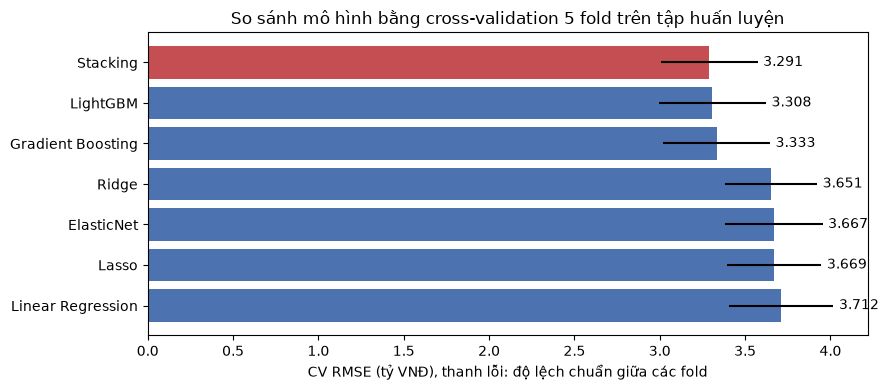

In [76]:
fig, ax = plt.subplots(figsize=(9, 4))
t = cv_table.sort_values("CV RMSE", ascending=False)
ax.barh(t["Mô hình"], t["CV RMSE"], xerr=t["Độ lệch chuẩn RMSE"],
        color=["#C44E52" if n == BEST_NAME else "#4C72B0" for n in t["Mô hình"]])
ax.bar_label(ax.containers[1], fmt="%.3f", padding=4)
ax.set_xlabel("CV RMSE (tỷ VNĐ), thanh lỗi: độ lệch chuẩn giữa các fold")
ax.set_title("So sánh mô hình bằng cross-validation 5 fold trên tập huấn luyện")
plt.tight_layout()

### Nhận xét
- **Mô hình cây vượt trội mô hình tuyến tính:** Gradient Boosting và LightGBM có CV RMSE khoảng 3,31–3,33 tỷ, thấp hơn khoảng 9–10% so với nhóm tuyến tính (khoảng 3,65–3,71 tỷ). Mô hình cây học được quan hệ phi tuyến và tương tác giữa các thuộc tính, ví dụ diện tích lớn chỉ làm giá tăng mạnh khi nhà ở mặt tiền và gần trung tâm.
- **Ridge, Lasso, ElasticNet chỉ tốt hơn Linear Regression một chút:** số thuộc tính ít so với số mẫu, nên chính quy hóa không cải thiện nhiều.
- **Stacking tốt nhất nhưng chênh lệch rất nhỏ:** CV RMSE của Stacking thấp hơn LightGBM khoảng 0,5%, nhỏ hơn nhiều so với độ lệch chuẩn giữa các fold (khoảng 0,3 tỷ). Mô hình meta dành khoảng 4/5 tổng trọng số cho hai mô hình cây (LightGBM ≈ 0,56, Gradient Boosting ≈ 0,24).
- **Mức chính xác:** R² khoảng 0,75. Phần biến thiên còn lại của giá đến từ các yếu tố dữ liệu không có: tình trạng pháp lý, vị trí cụ thể trong quận, hướng nhà, chất lượng xây dựng.

**Phản biện:** Stacking phức tạp hơn và huấn luyện chậm hơn LightGBM mà chỉ cải thiện rất ít. Stacking vẫn được chọn theo tiêu chí đặt trước (CV RMSE thấp nhất); LightGBM là phương án thay thế hợp lý nếu cần mô hình đơn giản hơn. Kết luận cuối cùng được kiểm chứng trên tập kiểm thử độc lập ở Bước 3.

## 6.7 Lưu kết quả học được

- `models/learnt.pkl`: mô hình tốt nhất, gồm toàn bộ pipeline (tiền xử lý, biến đổi biến mục tiêu, mô hình). Có thể nạp lại và dự đoán trực tiếp từ dữ liệu thô của một căn nhà.
- `models/all_models.pkl`: tất cả mô hình đã huấn luyện, dùng để so sánh ở Bước 3.
- `reports/best_params.csv`: tham số tốt nhất của từng mô hình.
- `reports/cv_results.csv`: kết quả cross-validation.

In [77]:
learnt = {
    "model": fitted[BEST_NAME],
    "model_name": BEST_NAME,
    "features": {"num": FEAT_GROUPS.get("num", FEATURES_NUM), "bool": FEAT_GROUPS.get("boolean", FEATURES_BOOL),
                 "cat": FEAT_GROUPS.get("cat", FEATURES_CAT)},
    "district_coords": DISTRICT_COORDS,
    "city_center": CITY_CENTER,
    "target_transform": TARGET_TRANSFORM,
    "cv_rmse": float(cv_table.loc[0, "CV RMSE"]),
    "trained_on": len(X_train),
}
joblib.dump(learnt, MODELS_DIR / "learnt.pkl")
joblib.dump(fitted, MODELS_DIR / "all_models.pkl")
pd.DataFrame(search_rows).to_csv(ROOT / "reports" / "best_params.csv", index=False, encoding="utf-8")
cv_table.to_csv(ROOT / "reports" / "cv_results.csv", index=False, encoding="utf-8")

for f in ["models/learnt.pkl", "models/all_models.pkl", "reports/best_params.csv", "reports/cv_results.csv"]:
    print(f"{f:28} {(ROOT / f).stat().st_size / 1024:8.1f} KB")

models/learnt.pkl               725.2 KB
models/all_models.pkl          1461.6 KB
reports/best_params.csv           0.5 KB
reports/cv_results.csv            0.6 KB


### Kiểm tra nạp lại mô hình
Nạp `learnt.pkl` và dự đoán cho một căn nhà mẫu, để xác nhận tệp lưu dùng được độc lập.

In [78]:
loaded = joblib.load(MODELS_DIR / "learnt.pkl")
sample = X_train.iloc[[0]]
print("Mô hình:", loaded["model_name"])
print(f"Giá thực tế : {y_train.iloc[0]:.2f} tỷ")
print(f"Giá dự đoán : {loaded['model'].predict(sample)[0]:.2f} tỷ")
sample

Mô hình: Stacking
Giá thực tế : 8.00 tỷ
Giá dự đoán : 6.47 tỷ


,area_m2,width_m,length_m,road_width_m,floors,bedrooms,width_length_ratio,dist_center_km,lat,lon,n_schools,n_health,n_markets,n_parks,n_transit,has_dining_room,has_kitchen,has_terrace,has_parking,city,district,house_type
2169,80.0,5.0,15.0,2.5,5,6,0.333,9.902805,21.01857,105.75761,39,10,37,10,60,1.0,1.0,1.0,1.0,Hà Nội,Nam Từ Liêm,Nhà trong hẻm


# 7. Đánh giá mô hình (Bước 3 của đề tài)

**Mục đích:** so sánh các mô hình trên **tập kiểm thử độc lập** (564 bản ghi, tách ra ở mục 6.1 và chưa được dùng trong bất kỳ bước học nào) theo bốn thang đo của đề tài, phân tích sai số và giải thích kết quả.

| Thang đo | Công thức | Ý nghĩa |
|---|---|---|
| RMSE | $\sqrt{\frac{1}{n}\sum (y_i - \hat{y}_i)^2}$ | Sai số trung bình, phạt nặng sai số lớn (tỷ VNĐ) |
| MAE | $\frac{1}{n}\sum \lvert y_i - \hat{y}_i \rvert$ | Sai số tuyệt đối trung bình (tỷ VNĐ) |
| R² | $1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$ | Tỷ lệ biến thiên của giá được mô hình giải thích |
| MAPE | $\frac{100\%}{n}\sum \left\lvert \frac{y_i - \hat{y}_i}{y_i} \right\rvert$ | Sai số tương đối trung bình (%) |

Tất cả thang đo được tính trên đơn vị gốc (tỷ VNĐ), sau khi đảo ngược biến đổi Log1p.

In [79]:
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             mean_squared_error, r2_score)
from sklearn.model_selection import cross_val_predict
import shap

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def metrics(y_true, y_pred):
    return {"RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE": mean_absolute_error(y_true, y_pred),
            "R²": r2_score(y_true, y_pred),
            "MAPE (%)": mean_absolute_percentage_error(y_true, y_pred) * 100}


print("shap", shap.__version__)

shap 0.54.1


## 7.1 So sánh các mô hình trên tập kiểm thử

In [80]:
preds = {name: m.predict(X_test) for name, m in fitted.items()}
test_table = pd.DataFrame([{"Mô hình": n, **metrics(y_test, p)} for n, p in preds.items()])
test_table = test_table.merge(cv_table[["Mô hình", "CV RMSE"]], on="Mô hình")
test_table["Chênh lệch RMSE so với CV (%)"] = (test_table["RMSE"] / test_table["CV RMSE"] - 1) * 100
test_table = test_table.sort_values("RMSE").reset_index(drop=True)
test_table.to_csv(ROOT / "reports" / "metrics.csv", index=False, encoding="utf-8")
test_table.round(4)

,Mô hình,RMSE,MAE,R²,MAPE (%),CV RMSE,Chênh lệch RMSE so với CV (%)
0,Gradient Boosting,3.2077,1.9696,0.7617,25.1211,3.3332,-3.7664
1,Stacking,3.2147,1.9841,0.7606,24.8065,3.2914,-2.3312
2,LightGBM,3.3796,2.0591,0.7354,25.4692,3.3078,2.1728
3,Ridge,3.4595,2.1335,0.7228,26.4780,3.6515,-5.2589
4,ElasticNet,3.4769,2.1333,0.7200,26.4617,3.6668,-5.1780
5,Linear Regression,3.4773,2.1253,0.7199,26.5703,3.7117,-6.3163
6,Lasso,3.4844,2.1483,0.7188,26.5793,3.6693,-5.0386


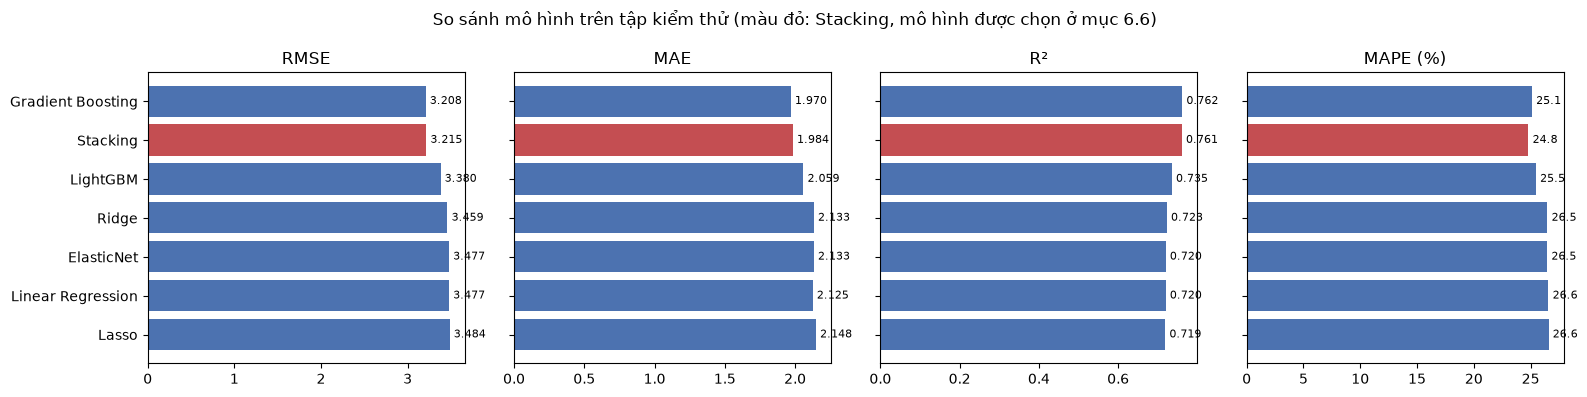

In [81]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
t = test_table.sort_values("RMSE", ascending=False)
colors = ["#C44E52" if n == BEST_NAME else "#4C72B0" for n in t["Mô hình"]]
for ax, col in zip(axes, ["RMSE", "MAE", "R²", "MAPE (%)"]):
    ax.barh(t["Mô hình"], t[col], color=colors)
    ax.bar_label(ax.containers[0], fmt="%.3f" if col != "MAPE (%)" else "%.1f", padding=3, fontsize=8)
    ax.set_title(col)
    if col != "RMSE":
        ax.set_yticklabels([])
fig.suptitle(f"So sánh mô hình trên tập kiểm thử (màu đỏ: {BEST_NAME}, mô hình được chọn ở mục 6.6)")
plt.tight_layout()
fig.savefig(FIG_DIR / "model_comparison.png", dpi=120, bbox_inches="tight")

### Nhận xét
- **Thứ hạng nhóm được giữ nguyên giữa cross-validation và tập kiểm thử:** nhóm mô hình cây (Gradient Boosting, Stacking, LightGBM) có RMSE khoảng 3,20–3,38 tỷ và R² khoảng 0,74–0,76, tốt hơn nhóm tuyến tính (RMSE khoảng 3,46–3,48 tỷ, R² khoảng 0,72).
- **Không có dấu hiệu quá khớp:** RMSE trên tập kiểm thử xấp xỉ CV RMSE (chênh lệch từ −6% đến +2%). Mô hình tổng quát hóa tốt cho dữ liệu chưa thấy.
- **Stacking và Gradient Boosting gần như ngang nhau:** Gradient Boosting có RMSE và MAE thấp hơn Stacking khoảng 0,01 tỷ, trong khi Stacking có MAPE thấp nhất. Mức chênh này rất nhỏ so với sai số của mô hình.
- **MAPE khoảng 25–27%:** trung bình mô hình lệch khoảng một phần tư giá căn nhà.

**Phản biện:** không chọn lại mô hình dựa trên tập kiểm thử. Nếu đổi sang Gradient Boosting vì RMSE kiểm thử thấp hơn, tập kiểm thử sẽ trở thành một phần của quá trình chọn mô hình và mất tính độc lập. Stacking được giữ theo tiêu chí đã định trước (CV RMSE, mục 6.6); kết quả kiểm thử xác nhận Stacking thuộc nhóm tốt nhất, với sai số tương đối (MAPE) thấp nhất.

## 7.2 Giá thực tế và giá dự đoán

Phần dư trung bình: 0.112 tỷ | Trung vị: -0.044 tỷ


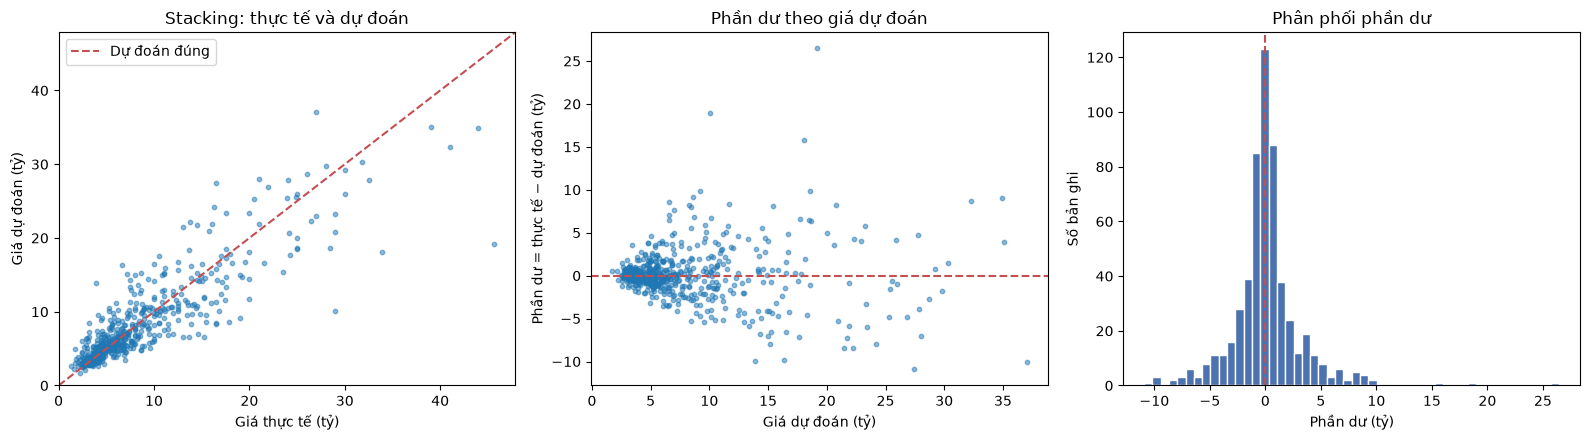

In [82]:
best_pred = preds[BEST_NAME]
resid = y_test - best_pred

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
lim = [0, max(y_test.max(), best_pred.max()) * 1.05]
axes[0].scatter(y_test, best_pred, s=10, alpha=0.5)
axes[0].plot(lim, lim, "--", color="#C44E52", label="Dự đoán đúng")
axes[0].set_xlim(lim); axes[0].set_ylim(lim)
axes[0].set_xlabel("Giá thực tế (tỷ)"); axes[0].set_ylabel("Giá dự đoán (tỷ)")
axes[0].set_title(f"{BEST_NAME}: thực tế và dự đoán")
axes[0].legend()

axes[1].scatter(best_pred, resid, s=10, alpha=0.5)
axes[1].axhline(0, color="#C44E52", linestyle="--")
axes[1].set_xlabel("Giá dự đoán (tỷ)"); axes[1].set_ylabel("Phần dư = thực tế − dự đoán (tỷ)")
axes[1].set_title("Phần dư theo giá dự đoán")

axes[2].hist(resid, bins=50, color="#4C72B0", edgecolor="white")
axes[2].axvline(0, color="#C44E52", linestyle="--")
axes[2].set_xlabel("Phần dư (tỷ)"); axes[2].set_ylabel("Số bản ghi")
axes[2].set_title("Phân phối phần dư")
plt.tight_layout()
fig.savefig(FIG_DIR / "pred_vs_actual.png", dpi=120, bbox_inches="tight")

print(f"Phần dư trung bình: {resid.mean():.3f} tỷ | Trung vị: {resid.median():.3f} tỷ")

### Nhận xét
- Các điểm phân bố quanh đường chéo; mô hình nắm được xu hướng chung của giá.
- **Phương sai sai số tăng theo mức giá** (phần dư tỏa rộng khi giá dự đoán tăng): sai số tuyệt đối lớn hơn ở các căn đắt. Đây là đặc điểm thường gặp của dữ liệu giá và là lý do dùng biến đổi log cho biến mục tiêu và cho khoảng dự báo (mục 7.5).
- Phần dư trung bình gần 0 nhưng phân phối lệch phải: một số căn giá cao bị dự đoán thấp hơn nhiều so với thực tế.

## 7.3 Sai số theo phân khúc giá, thành phố và loại nhà

Mục 5.1 cho thấy phân khúc giá trên 15 tỷ chỉ chiếm khoảng 13% dữ liệu. Phân tích sai số theo nhóm kiểm tra xem mô hình có kém hơn ở các nhóm ít mẫu hay không.

**Sai số hệ thống (bias)** = trung bình của (thực tế − dự đoán). Bias dương nghĩa là mô hình **dự đoán thấp hơn** thực tế.

In [83]:
def group_errors(groups, model_names=(BEST_NAME, "LightGBM", "Ridge")):
    rows = []
    for g in pd.Series(groups).dropna().unique():
        mask = (pd.Series(groups, index=y_test.index) == g).to_numpy()
        for n in dict.fromkeys(model_names):
            m = metrics(y_test[mask], preds[n][mask])
            rows.append({"Nhóm": g, "Mô hình": n, "Số bản ghi": int(mask.sum()), "RMSE": m["RMSE"],
                         "MAE": m["MAE"], "MAPE (%)": m["MAPE (%)"],
                         "Bias (tỷ)": float((y_test[mask] - preds[n][mask]).mean())})
    return pd.DataFrame(rows)


seg_err = group_errors(seg_test.astype(str))
seg_err["Nhóm"] = pd.Categorical(seg_err["Nhóm"], SEGMENT_LABELS, ordered=True)
seg_err.sort_values(["Nhóm", "RMSE"]).round(3)

,Nhóm,Mô hình,Số bản ghi,RMSE,MAE,MAPE (%),Bias (tỷ)
4,Dưới 5 tỷ,LightGBM,219,1.438,0.927,27.150,-0.597
3,Dưới 5 tỷ,Stacking,219,1.458,0.919,26.946,-0.605
5,Dưới 5 tỷ,Ridge,219,1.646,1.028,30.235,-0.746
2,5–15 tỷ,Ridge,271,2.654,1.955,23.012,0.204
0,5–15 tỷ,Stacking,271,2.716,1.971,23.397,-0.093
1,5–15 tỷ,LightGBM,271,2.842,2.064,24.497,-0.176
6,Trên 15 tỷ,Stacking,74,6.742,5.184,23.637,2.984
7,Trên 15 tỷ,LightGBM,74,7.166,5.392,24.056,3.263
8,Trên 15 tỷ,Ridge,74,7.577,6.060,28.053,2.726


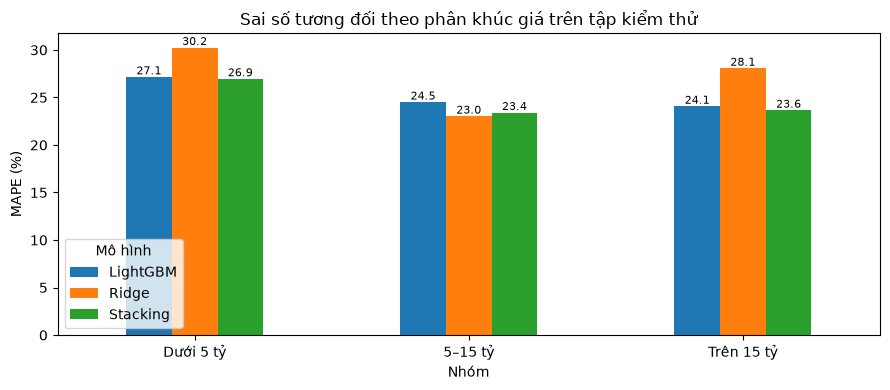

In [84]:
pivot = seg_err.pivot(index="Nhóm", columns="Mô hình", values="MAPE (%)")
ax = pivot.plot.bar(figsize=(9, 4), rot=0)
ax.set_ylabel("MAPE (%)")
ax.set_title("Sai số tương đối theo phân khúc giá trên tập kiểm thử")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.1f", fontsize=8)
plt.tight_layout()
plt.gcf().savefig(FIG_DIR / "error_by_segment.png", dpi=120, bbox_inches="tight")

In [85]:
pd.concat({
    "Thành phố": group_errors(X_test["city"], (BEST_NAME,)).set_index("Nhóm"),
    "Loại nhà": group_errors(X_test["house_type"], (BEST_NAME,)).set_index("Nhóm"),
}).drop(columns="Mô hình").round(3)

Số bản ghi   RMSE    MAE  MAPE (%)  Bias (tỷ)
          Nhóm                                                        
Thành phố Hà Nội                369  2.787  1.785    23.458      0.076
          Hồ Chí Minh           195  3.897  2.361    27.358      0.181
Loại nhà  Nhà trong hẻm         388  1.902  1.271    22.305      0.059
          Nhà mặt tiền          176  5.014  3.557    30.321      0.229

### Nhận xét
- **Ảnh hưởng của mất cân bằng dữ liệu được xác nhận:** ở phân khúc trên 15 tỷ (13% dữ liệu), sai số tuyệt đối lớn nhất và **bias dương rõ rệt** (khoảng +3,0 tỷ với Stacking): mô hình có xu hướng **định giá thấp** nhà đắt. Ngược lại, ở phân khúc dưới 5 tỷ, mô hình định giá cao hơn thực tế khoảng 0,6 tỷ. Mô hình bị kéo về mức giá phổ biến.
- **Sai số tương đối (MAPE) khá đồng đều** giữa các phân khúc (khoảng 23–27%), nhờ biến đổi log của biến mục tiêu và chia tập phân tầng.
- **Nhà mặt tiền và TP.HCM có sai số lớn hơn:** đây là các nhóm ít mẫu hơn và có giá phân tán hơn.

**Hướng cải thiện:** bổ sung dữ liệu nhà giá cao, gán trọng số mẫu lớn hơn cho phân khúc ít mẫu, hoặc huấn luyện mô hình riêng cho nhà mặt tiền.

## 7.4 Giải thích mô hình bằng SHAP

SHAP (SHapley Additive exPlanations) phân rã mỗi dự đoán thành tổng đóng góp của từng thuộc tính, dựa trên giá trị Shapley của lý thuyết trò chơi. Phân tích được thực hiện trên mô hình **LightGBM** (thành phần có trọng số lớn nhất trong Stacking), trên tập kiểm thử. Giá trị SHAP nằm trên thang Log1p của giá: đóng góp +0,1 tương ứng với giá tăng khoảng 10%.

Đóng góp của các cột one-hot được cộng lại theo thuộc tính gốc (ví dụ tất cả cột `district_*` thành `district`).

,trung bình |SHAP|
area_m2,0.2489
road_width_m,0.1498
house_type,0.0776
floors,0.0647
n_markets,0.0418
dist_center_km,0.0410
n_schools,0.0330
n_transit,0.0263
district,0.0179
width_m,0.0158


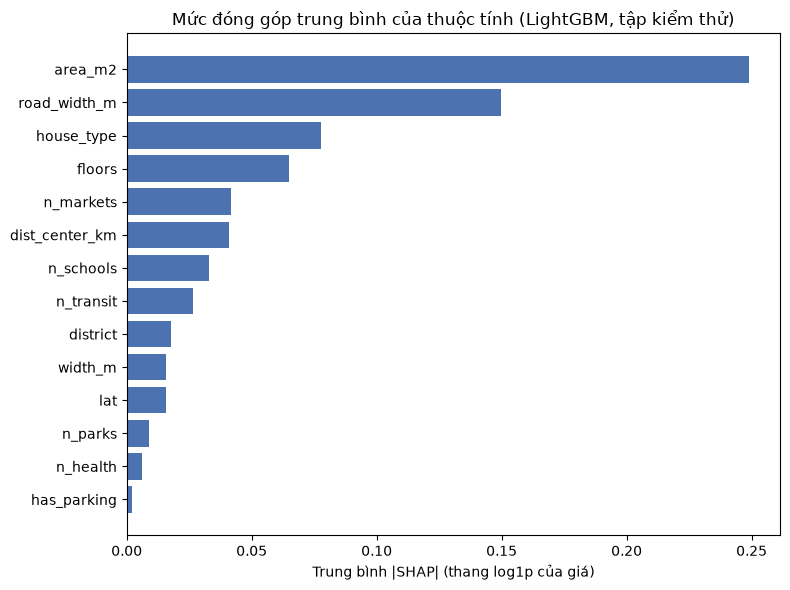

In [86]:
lgbm_fit = fitted["LightGBM"].regressor_
prep_fit, lgbm_model = lgbm_fit.named_steps["prep"], lgbm_fit.named_steps["model"]
Xt_test = prep_fit.transform(X_test)
col_names = [n.split("__", 1)[1] for n in prep_fit.get_feature_names_out()]
shap_values = shap.TreeExplainer(lgbm_model).shap_values(Xt_test)


def original_feature(col):
    for f in FEATURES_CAT:
        if col.startswith(f + "_"):
            return f
    return col


shap_df = pd.DataFrame(np.abs(shap_values), columns=col_names)
shap_imp = shap_df.T.groupby(original_feature).sum().T.mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(shap_imp.index, shap_imp.values, color="#4C72B0")
ax.set_xlabel("Trung bình |SHAP| (thang log1p của giá)")
ax.set_title("Mức đóng góp trung bình của thuộc tính (LightGBM, tập kiểm thử)")
plt.tight_layout()
fig.savefig(FIG_DIR / "shap_importance.png", dpi=120, bbox_inches="tight")
shap_imp.sort_values(ascending=False).round(4).to_frame("trung bình |SHAP|")

### Nhận xét
- Các thuộc tính có đóng góp lớn nhất: **diện tích, độ rộng đường trước nhà, loại nhà, số tầng**, tiếp theo là nhóm vị trí (**số chợ/siêu thị xung quanh, khoảng cách tới trung tâm, số trường học, số trạm giao thông**). Thứ tự này gần trùng với độ quan trọng hoán vị ở mục 6.3.2; hai phương pháp độc lập cho cùng kết luận, tăng độ tin cậy của phần giải thích.
- Kết quả phù hợp với lý thuyết định giá hedonic: giá nhà được quyết định bởi quy mô (diện tích, số tầng), khả năng tiếp cận (độ rộng đường, mặt tiền) và vị trí (khoảng cách tới trung tâm, tiện ích xung quanh).
- Biểu đồ chiều hướng cho thấy diện tích lớn, đường rộng, nhà mặt tiền và khu vực nhiều tiện ích làm **tăng** giá; khoảng cách tới trung tâm lớn làm **giảm** giá.
- Chỗ đỗ ô tô đóng góp rất ít, một phần có thể do giá trị "không" ở cột này thường chỉ có nghĩa là tin rao không đề cập.

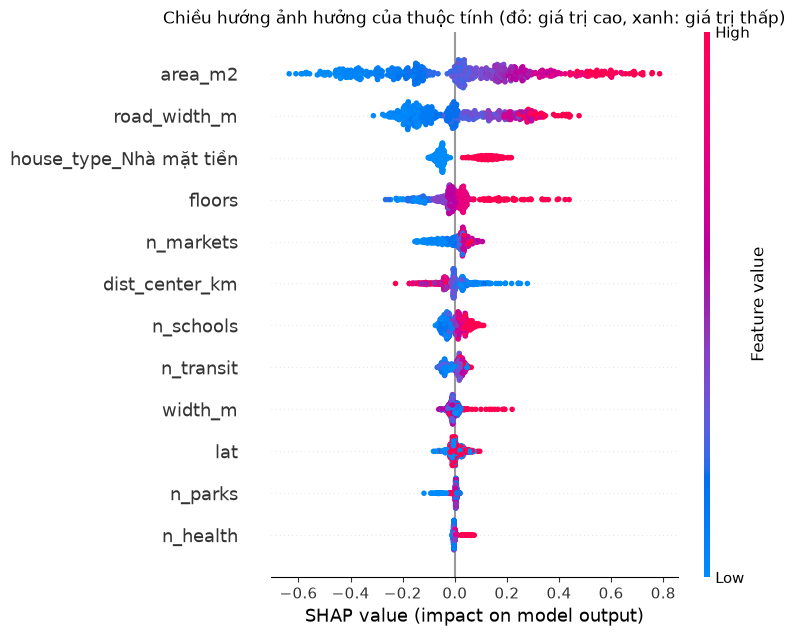

In [87]:
shap.summary_plot(shap_values, Xt_test, feature_names=col_names, max_display=12, show=False)
plt.title("Chiều hướng ảnh hưởng của thuộc tính (đỏ: giá trị cao, xanh: giá trị thấp)")
plt.gcf().savefig(FIG_DIR / "shap_beeswarm.png", dpi=120, bbox_inches="tight")

## 7.5 Khoảng dự báo 95%

Bước 4 của đề tài yêu cầu trả về giá dự báo kèm khoảng 95%. Khoảng này được xây dựng theo phương pháp **cross-conformal** dựa trên phần dư ngoài fold:

1. Dự đoán ngoài fold (out-of-fold) cho tập huấn luyện bằng cross-validation 5 fold: mỗi bản ghi được dự đoán bởi mô hình không được huấn luyện trên chính nó.
2. Tính phần dư trên thang log: $r_i = \ln(1 + y_i) - \ln(1 + \hat{y}_i)$.
3. Lấy phân vị 2,5% và 97,5% của phần dư: $q_{lo}$, $q_{hi}$.
4. Với căn nhà mới có giá dự đoán $\hat{y}$: khoảng 95% là $\left[e^{\ln(1+\hat{y}) + q_{lo}} - 1,\ e^{\ln(1+\hat{y}) + q_{hi}} - 1\right]$.

Làm trên thang log nên độ rộng khoảng **tỷ lệ với mức giá**: căn 3 tỷ có khoảng hẹp hơn căn 30 tỷ, phù hợp với thực tế định giá.

**Về thuật ngữ:** đề tài dùng cụm từ *khoảng tin cậy 95%*. Về mặt thống kê, khoảng chứa giá của **một căn nhà cụ thể** với xác suất 95% là **khoảng dự báo** (*prediction interval*). Khoảng tin cậy (*confidence interval*) là khoảng chứa **giá trung bình** của các căn có cùng đặc điểm, hẹp hơn khoảng dự báo. Ứng dụng dùng khoảng dự báo vì môi giới cần biết giá của căn đang định giá.

In [88]:
t0 = time.time()
oof = cross_val_predict(fitted[BEST_NAME], X_train, y_train, cv=CV, n_jobs=-1)
resid_log = np.log1p(y_train.to_numpy()) - np.log1p(oof)
Q_LO, Q_HI = np.quantile(resid_log, [0.025, 0.975])
print(f"Thời gian: {time.time() - t0:.1f} giây")
print(f"q_lo = {Q_LO:.4f}  (giá thực tế thấp hơn dự đoán tối đa khoảng {1 - np.exp(Q_LO):.0%})")
print(f"q_hi = {Q_HI:.4f}  (giá thực tế cao hơn dự đoán tối đa khoảng {np.exp(Q_HI) - 1:.0%})")


def interval(pred):
    lp = np.log1p(pred)
    return np.expm1(lp + Q_LO), np.expm1(lp + Q_HI)


lo, hi = interval(best_pred)
inside = (y_test >= lo) & (y_test <= hi)
print(f"\nĐộ phủ trên tập kiểm thử: {inside.mean():.1%} (mục tiêu 95%)")
pd.DataFrame({"Phân khúc": seg_test.values, "Trong khoảng": inside.values,
              "Độ rộng tương đối": ((hi - lo) / best_pred)}).groupby("Phân khúc", observed=True).agg(
    **{"Số bản ghi": ("Trong khoảng", "size"), "Độ phủ (%)": ("Trong khoảng", lambda s: s.mean() * 100),
       "Độ rộng TB (% giá dự đoán)": ("Độ rộng tương đối", lambda s: s.mean() * 100)}).round(1)

Thời gian: 10.5 giây
q_lo = -0.5455  (giá thực tế thấp hơn dự đoán tối đa khoảng 42%)
q_hi = 0.5117  (giá thực tế cao hơn dự đoán tối đa khoảng 67%)

Độ phủ trên tập kiểm thử: 94.1% (mục tiêu 95%)


,Số bản ghi,Độ phủ (%),Độ rộng TB (% giá dự đoán)
Phân khúc,,,
Dưới 5 tỷ,219,94.5,136.6
5–15 tỷ,271,95.6,123.7
Trên 15 tỷ,74,87.8,115.5


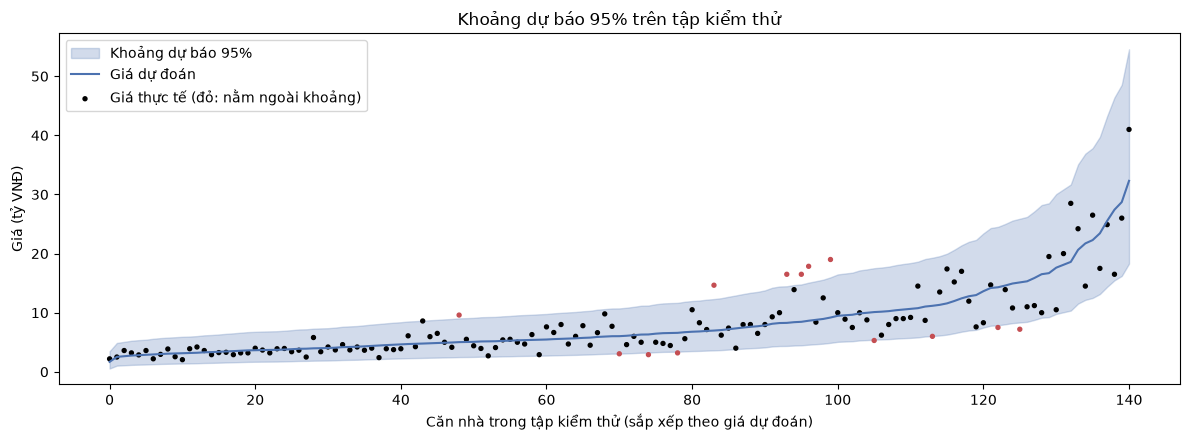

In [89]:
order = np.argsort(best_pred)[::4]   # vẽ 1/4 số điểm cho dễ nhìn
fig, ax = plt.subplots(figsize=(12, 4.5))
xs = np.arange(len(order))
ax.fill_between(xs, lo[order], hi[order], color="#4C72B0", alpha=0.25, label="Khoảng dự báo 95%")
ax.plot(xs, best_pred[order], color="#4C72B0", label="Giá dự đoán")
ax.scatter(xs, y_test.to_numpy()[order], s=8, color=np.where(inside.to_numpy()[order], "black", "#C44E52"),
           label="Giá thực tế (đỏ: nằm ngoài khoảng)")
ax.set_xlabel("Căn nhà trong tập kiểm thử (sắp xếp theo giá dự đoán)")
ax.set_ylabel("Giá (tỷ VNĐ)")
ax.set_title("Khoảng dự báo 95% trên tập kiểm thử")
ax.legend()
plt.tight_layout()
fig.savefig(FIG_DIR / "prediction_interval.png", dpi=120, bbox_inches="tight")

### Nhận xét
- **Độ phủ 94,1%** trên tập kiểm thử, sát mục tiêu 95%: khoảng dự báo được hiệu chỉnh đúng.
- Khoảng khá rộng (từ khoảng −42% đến +67% so với giá dự đoán), phản ánh trung thực mức bất định của mô hình với dữ liệu hiện có (R² ≈ 0,76, MAPE ≈ 25%).
- **Phân khúc trên 15 tỷ có độ phủ thấp hơn (87,8%)**, nhất quán với bias dương ở mục 7.3: khoảng dự báo dùng chung một bộ phân vị cho mọi phân khúc nên chưa đủ rộng cho nhà đắt. Có thể cải thiện bằng conformal theo nhóm (ước lượng phân vị riêng cho từng phân khúc).

### Cập nhật mô hình học được
Bổ sung tham số khoảng dự báo và kết quả đánh giá vào `models/learnt.pkl` để ứng dụng Streamlit sử dụng.

In [90]:
learnt["interval"] = {"q_lo": float(Q_LO), "q_hi": float(Q_HI), "level": 0.95,
                      "method": "cross-conformal, phần dư ngoài fold trên thang log1p",
                      "test_coverage": float(inside.mean())}
learnt["test_metrics"] = test_table.set_index("Mô hình").loc[BEST_NAME, ["RMSE", "MAE", "R²", "MAPE (%)"]].to_dict()
joblib.dump(learnt, MODELS_DIR / "learnt.pkl")

reloaded = joblib.load(MODELS_DIR / "learnt.pkl")
print("Các khóa trong learnt.pkl:", list(reloaded))
print("Kết quả trên tập kiểm thử:", {k: round(v, 3) for k, v in reloaded["test_metrics"].items()})

Các khóa trong learnt.pkl: ['model', 'model_name', 'features', 'district_coords', 'city_center', 'target_transform', 'cv_rmse', 'trained_on', 'interval', 'test_metrics']
Kết quả trên tập kiểm thử: {'RMSE': 3.215, 'MAE': 1.984, 'R²': 0.761, 'MAPE (%)': 24.807}


## 7.6 Kết luận

| Nội dung | Kết quả |
|---|---|
| Mô hình được chọn | **Stacking Ensemble** (Ridge, Lasso, ElasticNet, Gradient Boosting, LightGBM; mô hình meta RidgeCV) |
| Thuộc tính đầu vào | 14 thuộc tính (sau trích chọn), gồm 5 thuộc tính tiện ích xung quanh |
| Kết quả trên tập kiểm thử | RMSE ≈ 3,21 tỷ, MAE ≈ 1,98 tỷ, R² ≈ 0,76, MAPE ≈ 24,8% |
| So với mô hình cơ sở (Linear Regression) | RMSE giảm khoảng 7,6%, MAE giảm khoảng 6,6% |
| Thuộc tính quan trọng nhất | Diện tích, độ rộng đường, loại nhà, số tầng, nhóm vị trí (tiện ích xung quanh, khoảng cách tới trung tâm) |
| Khoảng dự báo 95% | Độ phủ 94,1% trên tập kiểm thử |

**Đánh giá chung:** mô hình giải thích được khoảng 3/4 biến thiên của giá rao bán, tổng quát hóa tốt (không quá khớp), và kết quả giải thích được bằng lý thuyết định giá hedonic. Mô hình phù hợp để **ước lượng sơ bộ** và đưa ra khoảng giá tham khảo cho môi giới.

**Hạn chế:**
- Sai số tương đối khoảng 25% còn lớn so với yêu cầu định giá chính xác; mô hình định giá thấp nhà trên 15 tỷ.
- Dữ liệu thiếu các yếu tố quan trọng: tình trạng pháp lý (yêu cầu của đề tài), vị trí chi tiết dưới cấp quận (nên tiện ích xung quanh chỉ tính được theo quận), hướng nhà, chất lượng và năm xây dựng.
- Biến mục tiêu là giá rao bán, không phải giá giao dịch; dữ liệu thu thập trước 01/2022.

**Hướng phát triển:** thu thập thêm dữ liệu có tọa độ chính xác và tình trạng pháp lý; khai thác thông tin từ tiêu đề và mô tả tin rao; bổ sung dữ liệu phân khúc giá cao; dùng conformal theo nhóm cho khoảng dự báo.

# 8. Lưu kết quả cho ứng dụng

Các kết quả trung gian được gom vào `reports/artifacts.pkl` để ứng dụng Streamlit trình bày và tính lại các phân tích tương tác (độ tin cậy bằng bootstrap, khoảng dự báo ở các mức khác 95%, so sánh cặp mô hình) mà không phải huấn luyện lại.

In [91]:
shap_signed = pd.DataFrame(shap_values, columns=col_names).T.groupby(original_feature).sum().T
artifacts = {
    "target_compare": tt,
    "box_cox": {"lambda": float(bc_lambda), "compare": compare},
    "lasso_coef": coef,
    "perm_importance": imp,
    "weak_features": weak,
    "feature_compare": feat_cmp,
    "amenity_compare": amen_cmp,
    "search_rows": pd.DataFrame(search_rows),
    "search_cv": search_cv,
    "cv_folds": CV_FOLDS,
    "cv_table": cv_table,
    "test_table": test_table,
    "stack_weights": weights,
    "test": {"y": y_test.to_numpy(), "segment": seg_test.astype(str).to_numpy(),
             "X": X_test.reset_index(drop=True), "preds": preds},
    "oof": {"y": y_train.to_numpy(), "pred": oof, "segment": seg_train.astype(str).to_numpy()},
    "shap": {"values": shap_signed.reset_index(drop=True), "importance": shap_imp},
    "split": {"train": len(X_train), "test": len(X_test), "random_state": RANDOM_STATE},
}
joblib.dump(artifacts, ROOT / "reports" / "artifacts.pkl")
print("Đã lưu reports/artifacts.pkl:", f"{(ROOT / 'reports' / 'artifacts.pkl').stat().st_size / 1024:.0f} KB")
print("Các khóa:", list(artifacts))

Đã lưu reports/artifacts.pkl: 332 KB
Các khóa: ['target_compare', 'box_cox', 'lasso_coef', 'perm_importance', 'weak_features', 'feature_compare', 'amenity_compare', 'search_rows', 'search_cv', 'cv_folds', 'cv_table', 'test_table', 'stack_weights', 'test', 'oof', 'shap', 'split']
